# RAG-консультант ювелирного магазина: собственный парсинг документов, векторные базы данных и сравнение языковых моделей

## Практическое задание по базам данных для RAG: парсинг PDF, DOCX и TXT, Qdrant и ChromaDB, GigaChat и OpenRouter

Работа выполнена в рамках практического задания курса по работе с LLM (практика 1, базы данных). Объект исследования — учебная RAG-система: виртуальный консультант, который отвечает на вопросы клиентов о выборе ювелирных изделий и уходе за ними. Работа включает три задания:

1. собственный парсинг документов PDF, DOCX и TXT без библиотеки `unstructured`: очистка текста, разбиение на чанки и сравнение с прежней версией конвейера;
2. эксперимент с векторными базами данных Qdrant и ChromaDB на коллекциях из 1 000 и 10 000 документов;
3. подключение GigaChat и моделей OpenRouter к приложению через единый интерфейс и их сравнение на одинаковых задачах.

**Инфраструктура.**

* Векторные БД развёрнуты локально: Qdrant 1.19.2 — нативная сборка сервера, ChromaDB 1.5.9 — сервер `chroma run` и встроенный режим `PersistentClient`.
* Языковые модели:
  * GigaChat-2 и GigaChat-2-Max (тариф Freemium);
  * бесплатные модели OpenRouter `liquid/lfm-2.5-2.6b:free` (2,6 млрд параметров) и `nvidia/nemotron-3-super-120b-a12b:free` (120 млрд параметров, MoE);
  * для оценки локального запуска — модель LFM-2.5-2.6B через MLX.
* Независимый оценщик ответов (LLM-as-a-Judge) — `deepseek-flash` (DeepSeek API).

**Воспроизводимость.** Результаты измерений и ответы моделей сохраняются в каталоге `practice_db/results/`. При повторном запуске ноутбук загружает сохранённые результаты и воспроизводит приведённые таблицы без новых измерений и запросов к API. Чтобы провести эксперименты заново, нужно установить `RERUN = True`.

**Запуск.**

1. Установить зависимости: `pip install -r requirements.txt`; для распознавания сканов нужен Tesseract с языковым пакетом `rus`.
2. Указать ключи в файле `.env` (шаблон — `.env.example`): `GIGACHAT_CREDENTIALS`, `OPENROUTER_API_KEY` и, при необходимости, `DEEPSEEK_API_KEY`.
3. Сертификат Минцифры для проверки SSL GigaChat находится в файле `certs/russian_trusted_root_ca.pem`.

## 0. Подготовка окружения

Вспомогательная функция `stored` сохраняет результат эксперимента в каталог `practice_db/results/`. При повторном запуске результат загружается из файла, поэтому таблицы и выводы ноутбука не расходятся с проведёнными измерениями. Конфигурация компьютера и версии библиотек также фиксируются в момент проведения экспериментов.

In [1]:
# Зависимости (один раз): %pip install -r requirements.txt
import hashlib, json, os, platform, re, shutil, socket, subprocess, sys, threading, time, unicodedata, warnings
import importlib.metadata as metadata
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict, dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd
import psutil
from dotenv import load_dotenv

load_dotenv(".env")  # ключи берутся из файла .env в рабочей папке
for var, value in {"TOKENIZERS_PARALLELISM": "false", "UNSTRUCTURED_DISABLE_NOTICE": "1",
                   "HF_HUB_DISABLE_PROGRESS_BARS": "1", "HF_HUB_VERBOSITY": "error",
                   "TRANSFORMERS_VERBOSITY": "error"}.items():
    os.environ.setdefault(var, value)
warnings.filterwarnings("ignore", message="IProgress not found")
import logging  # служебные предупреждения библиотек не относятся к результатам
for name in ["unstructured", "unstructured_inference", "huggingface_hub", "transformers", "sentence_transformers",
             "torch.distributed.elastic.multiprocessing.redirects", "pdfminer", "httpx", "chromadb", "pypdf"]:
    logging.getLogger(name).setLevel(logging.ERROR)

WORK = Path("practice_db")
DOCS, DATA, RESULTS, STORAGE = WORK / "documents", WORK / "data", WORK / "results", WORK / "storage"
for p in (DATA, RESULTS, STORAGE):
    p.mkdir(parents=True, exist_ok=True)
RERUN = False  # True — провести измерения и запросы к API заново


def stored(name, run):
    """Результат эксперимента: из файла, если эксперимент уже проводился, иначе — выполнить и сохранить."""
    path = RESULTS / f"{name}.json"
    if path.exists() and not RERUN:
        return json.loads(path.read_text("utf-8"))
    data = run()
    path.write_text(json.dumps(data, ensure_ascii=False, indent=1, default=str), "utf-8")
    return data


def cpu_name():
    if sys.platform == "darwin":
        return subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()
    return platform.processor() or platform.machine()


PACKAGES = ["pypdf", "python-docx", "pytesseract", "pypdfium2", "unstructured", "sentence-transformers", "torch",
            "chromadb", "qdrant-client", "gigachat", "openai", "mlx-lm", "pandas"]
ENV = stored("environment", lambda: {
    "cpu": cpu_name(), "cores": os.cpu_count(), "ram_gb": round(psutil.virtual_memory().total / 2**30),
    "os": f"{platform.system()} {platform.release()}", "python": platform.python_version(),
    "packages": {p: metadata.version(p) for p in PACKAGES}})

pd.set_option("display.max_colwidth", 160)
print(f"Конфигурация экспериментов: {ENV['cpu']}, {ENV['cores']} ядер, {ENV['ram_gb']} ГБ ОЗУ; "
      f"{ENV['os']}; Python {ENV['python']}")
pd.DataFrame([ENV["packages"]], index=["версия"])

Конфигурация экспериментов: Darwin 25.6.0; Python 3.11.15


,pypdf,python-docx,pytesseract,pypdfium2,unstructured,sentence-transformers,torch,chromadb,qdrant-client,gigachat,openai,mlx-lm,pandas
версия,6.21.1,1.2.0,0.3.13,5.14.0,0.27.28,6.1.0,2.14.1,1.5.9,1.19.1,0.2.3,3.26.0,0.32.2,3.0.6


---
## Задание 1. Собственный парсинг документов (без unstructured)

В исходном конвейере документы обрабатывались облачным сервисом Unstructured Serverless API (стратегия `hi_res`): каждый распознанный элемент — заголовок, абзац, пункт списка, ячейка таблицы — становился отдельной записью векторной БД. В настоящем задании библиотека `unstructured` исключена из конвейера и заменена собственной реализацией из трёх этапов:

1. **загрузка** — единый интерфейс `load_document(path)`: PDF читается через `pypdf`, DOCX — через `python-docx`, TXT — стандартными средствами Python;
2. **очистка** — нормализация пробелов и переносов строк, удаление артефактов PDF (битые символы, колонтитулы, разрывы слов);
3. **разбиение на чанки** фиксированного размера с перекрытием.

Дополнительно реализовано распознавание сканированных страниц: если на странице PDF нет текстового слоя, она распознаётся через Tesseract. Библиотека `unstructured` используется только в п. 1.7, где запускается прежняя версия конвейера для сравнения.

### 1.1. Тестовый корпус

Корпус состоит из шести документов предметной области консультанта: три PDF различной структуры, два DOCX и один TXT.

* **PDF** — реальные публичные документы органов власти. Текстовый PDF сформирован системой управления сайтом; PDF с таблицами — приказ, свёрстанный в Microsoft Word, с приложениями-бланками; скан — постраничные изображения 200 dpi со скрытым OCR-слоем ABBYY FineReader.
* **DOCX и TXT.** Исходные файлы курса в ноутбуке недоступны: сохранился только результат их обработки сервисом unstructured. Поэтому документы DOCX и TXT подготовлены скриптом `practice_db/scripts/build_test_documents.py` из текстов исходного корпуса курса (памяток для потребителей). В них включены типичные элементы документов Word: заголовки, нумерованные и маркированные списки, таблицы (в том числе с объединённой ячейкой), колонтитулы и рисунок с текстом. TXT-файл сохранён в кодировке cp1251 с жёстким переносом строк.

Для проверки распознавания из скана дополнительно получен вариант **без текстового слоя**: исходные изображения страниц переупакованы в новый PDF.

Источники PDF:

* `pdf_text.pdf` — https://04.rospotrebnadzor.ru/index.php/consumer-information/faq/18133-07032023.pdf
* `pdf_tables.pdf` — https://probpalata.gov.ru/files/Приказ-ФПП-24.11.2025-189н.pdf
* `pdf_scan.pdf` — https://luga.ru/Files/file/1673875081yuvelirka.pdf

In [2]:
from pypdf import PdfReader

CORPUS = pd.DataFrame([
    {"Файл": "pdf_text.pdf", "Формат": "PDF",
     "Структура": "текстовый слой; абзацы, маркированные списки, колонтитулы, номера страниц",
     "Источник": "Управление Роспотребнадзора по Республике Алтай. «О правилах приобретения ювелирных изделий», 07.03.2023",
     "URL": "https://04.rospotrebnadzor.ru/index.php/consumer-information/faq/18133-07032023.pdf"},
    {"Файл": "pdf_tables.pdf", "Формат": "PDF",
     "Структура": "текстовый слой (Microsoft Word); нормативный текст, сноски, приложения-бланки с таблицами",
     "Источник": "Приказ ФПП от 24.11.2025 № 189н «Об утверждении Порядка проведения экспертизы ювелирных и других изделий из драгоценных металлов»",
     "URL": "https://probpalata.gov.ru/files/Приказ-ФПП-24.11.2025-189н.pdf"},
    {"Файл": "pdf_scan.pdf", "Формат": "PDF",
     "Структура": "скан 200 dpi (изображения CCITT) со скрытым OCR-слоем ABBYY FineReader 9",
     "Источник": "«Роспотребнадзор рекомендует: как правильно выбрать ювелирное изделие» (сайт администрации Лужского района)",
     "URL": "https://luga.ru/Files/file/1673875081yuvelirka.pdf"},
    {"Файл": "docx_choice.docx", "Формат": "DOCX",
     "Структура": "заголовки, нумерованный и маркированный списки, таблица, рисунок с текстом, колонтитулы",
     "Источник": "памятка ФБУЗ «Центр гигиены и эпидемиологии в Оренбургской области» (г. Орск) из корпуса курса", "URL": ""},
    {"Файл": "docx_care.docx", "Формат": "DOCX",
     "Структура": "заголовки двух уровней, списки, три таблицы (одна с объединённой ячейкой), колонтитулы",
     "Источник": "рекомендации по уходу за ювелирными изделиями из корпуса курса", "URL": ""},
    {"Файл": "txt_novgorod.txt", "Формат": "TXT",
     "Структура": "кодировка cp1251, переводы строк CRLF, жёсткий перенос по 78 символов, списки",
     "Источник": "памятка Управления Роспотребнадзора по Новгородской области из корпуса курса", "URL": ""},
])
DOC_FILES = list(CORPUS["Файл"])
CORPUS["Размер, КБ"] = [round((DOCS / f).stat().st_size / 1024, 1) for f in DOC_FILES]
CORPUS["Страниц"] = [len(PdfReader(DOCS / f).pages) if f.endswith(".pdf") else None for f in DOC_FILES]
CORPUS["SHA-256 (начало)"] = [hashlib.sha256((DOCS / f).read_bytes()).hexdigest()[:12] for f in DOC_FILES]

SCAN_NOOCR = DATA / "pdf_scan_noocr.pdf"


def make_image_only_pdf(src, dst):
    """Скан без текстового слоя: исходные изображения страниц переупаковываются в новый PDF."""
    images = [page.images[0].image.convert("L") for page in PdfReader(src).pages]
    images[0].save(dst, save_all=True, append_images=images[1:], resolution=200)


make_image_only_pdf(DOCS / "pdf_scan.pdf", SCAN_NOOCR)
CORPUS.drop(columns="URL").style.hide(axis="index")

Файл,Формат,Структура,Источник,"Размер, КБ",Страниц,SHA-256 (начало)
pdf_text.pdf,PDF,"текстовый слой; абзацы, маркированные списки, колонтитулы, номера страниц","Управление Роспотребнадзора по Республике Алтай. «О правилах приобретения ювелирных изделий», 07.03.2023",237.800000,3.000000,5ca29c825299
pdf_tables.pdf,PDF,"текстовый слой (Microsoft Word); нормативный текст, сноски, приложения-бланки с таблицами",Приказ ФПП от 24.11.2025 № 189н «Об утверждении Порядка проведения экспертизы ювелирных и других изделий из драгоценных металлов»,226.600000,23.000000,52afddcd0017
pdf_scan.pdf,PDF,скан 200 dpi (изображения CCITT) со скрытым OCR-слоем ABBYY FineReader 9,«Роспотребнадзор рекомендует: как правильно выбрать ювелирное изделие» (сайт администрации Лужского района),201.600000,3.000000,3f8b1fc57d5e
docx_choice.docx,DOCX,"заголовки, нумерованный и маркированный списки, таблица, рисунок с текстом, колонтитулы",памятка ФБУЗ «Центр гигиены и эпидемиологии в Оренбургской области» (г. Орск) из корпуса курса,46.500000,nan,184c27251ee4
docx_care.docx,DOCX,"заголовки двух уровней, списки, три таблицы (одна с объединённой ячейкой), колонтитулы",рекомендации по уходу за ювелирными изделиями из корпуса курса,42.000000,nan,890682c65289
txt_novgorod.txt,TXT,"кодировка cp1251, переводы строк CRLF, жёсткий перенос по 78 символов, списки",памятка Управления Роспотребнадзора по Новгородской области из корпуса курса,4.000000,nan,90bae66e8cac


### 1.2. Загрузка документов: единый интерфейс `load_document(path)`

* **PDF** (`pypdf`). Текст извлекается постранично методом `extract_text`. Если на странице меньше 30 символов текста, но есть изображения, страница считается сканом: она отрисовывается библиотекой `pypdfium2` с разрешением 300 dpi и распознаётся Tesseract (языки `rus+eng`).
* **DOCX** (`python-docx`). Абзацы и таблицы обходятся в порядке следования в документе (`iter_inner_content`). Структура передаётся разметкой в стиле Markdown:
  * стиль `Title` и `Heading N` — заголовок `#` соответствующего уровня;
  * стили `List Number` и `List Bullet` — пункт списка; номер пункта восстанавливается счётчиком, так как в тексте абзаца Word номера нет;
  * таблица — строки вида `ячейка | ячейка`; объединённая ячейка, которую `python-docx` повторяет в каждой занимаемой позиции, берётся один раз;
  * колонтитулы добавляются в начало и конец текста; рисунки подсчитываются, но текст на них не извлекается.
* **TXT** (стандартная библиотека). Кодировка определяется так: при наличии BOM или успешном декодировании выбирается UTF-8; иначе из однобайтовых кодировок cp1251, KOI8-R и cp866 выбирается та, при которой доля частотных строчных букв кириллицы максимальна.

Функция `load_document` выбирает загрузчик по расширению файла, измеряет время и возвращает объект `ParsedDocument` с текстом по страницам и метаданными.

In [3]:
from docx import Document as DocxDocument
from docx.table import Table


@dataclass
class ParsedDocument:
    """Результат загрузки: текст по страницам (PDF) или одним блоком (DOCX, TXT) и метаданные."""
    source: str
    doc_type: str
    pages: list
    meta: dict = field(default_factory=dict)
    parse_s: float = 0.0

    @property
    def text(self):
        return "\n\n".join(self.pages)


def ocr_page(path, index, dpi=300, lang="rus+eng"):
    """Распознавание страницы PDF: отрисовка через pdfium и OCR через Tesseract."""
    import pypdfium2 as pdfium
    import pytesseract
    pdf = pdfium.PdfDocument(str(path))
    try:
        image = pdf[index].render(scale=dpi / 72).to_pil()
    finally:
        pdf.close()
    return pytesseract.image_to_string(image, lang=lang)


def load_pdf(path, ocr="auto", min_chars=30, dpi=300):
    """PDF через pypdf; страница без текстового слоя, но с изображениями распознаётся (ocr="auto")."""
    reader = PdfReader(path)
    pages, ocr_pages, image_pages = [], [], 0
    for i, page in enumerate(reader.pages):
        text = page.extract_text() or ""
        has_images = len(page.images) > 0
        image_pages += has_images
        if ocr == "auto" and len(text.strip()) < min_chars and has_images and shutil.which("tesseract"):
            text = ocr_page(path, i, dpi)
            ocr_pages.append(i + 1)
        pages.append(text)
    meta = {"pages": len(pages), "image_pages": image_pages, "ocr_pages": ocr_pages,
            "producer": (reader.metadata or {}).get("/Producer")}
    return pages, meta


BULLET = "•"


def paragraph_kind(paragraph):
    """Тип абзаца по стилю Word: заголовок (с уровнем), пункт нумерованного или маркированного списка, текст."""
    style = paragraph.style.name if paragraph.style is not None else ""
    if style == "Title":
        return "heading", 1
    m = re.match(r"Heading (\d)", style)
    if m:
        return "heading", int(m.group(1)) + 1
    if style.startswith("List Number"):
        return "numbered", 0
    has_numbering = paragraph._p.pPr is not None and paragraph._p.pPr.numPr is not None
    if style.startswith("List Bullet") or has_numbering:
        return "bullet", 0
    return "text", 0


def table_rows(table):
    """Строки таблицы; объединённая ячейка, повторяемая python-docx в каждой позиции, берётся один раз."""
    rows = []
    for row in table.rows:
        cells, seen = [], set()
        for cell in row.cells:
            if id(cell._tc) not in seen:
                seen.add(id(cell._tc))
                cells.append(" ".join(cell.text.split()))
        rows.append(cells)
    return rows


def load_docx(path, with_headers=True):
    """DOCX через python-docx: абзацы и таблицы в порядке следования, разметка заголовков и списков, колонтитулы."""
    doc = DocxDocument(path)
    blocks, number, n_tables = [], 0, 0
    for item in doc.iter_inner_content():
        if isinstance(item, Table):
            n_tables, number = n_tables + 1, 0
            blocks.append("\n".join(" | ".join(row) for row in table_rows(item)))
            continue
        kind, level = paragraph_kind(item)
        number = number + 1 if kind == "numbered" else 0
        text = item.text.strip()
        if not text:
            continue
        if kind == "heading":
            text = "#" * level + " " + text
        elif kind == "numbered":
            text = f"{number}. {text}"
        elif kind == "bullet":
            text = f"{BULLET} {text}"
        blocks.append(text)
    headers = [p.text.strip() for s in doc.sections for p in s.header.paragraphs if p.text.strip()]
    footers = [p.text.strip() for s in doc.sections for p in s.footer.paragraphs if p.text.strip()]
    body = (headers + blocks + footers) if with_headers else blocks
    meta = {"blocks": len(blocks), "tables": n_tables, "images": len(doc.inline_shapes),
            "headers": len(headers), "footers": len(footers)}
    return ["\n\n".join(body)], meta


FREQUENT_CYRILLIC = set("оеаинтсрвлкмдпуяыьгзбчйхжшюцщэфъё")


def detect_encoding(raw):
    """UTF-8 (с BOM или без) проверяется декодированием; из однобайтовых кодировок выбирается та,
    при которой доля частотных строчных букв кириллицы максимальна."""
    if raw.startswith(b"\xef\xbb\xbf"):
        return "utf-8-sig"
    try:
        raw.decode("utf-8")
        return "utf-8"
    except UnicodeDecodeError:
        pass

    def share(encoding):
        letters = [c for c in raw.decode(encoding, errors="replace") if c.isalpha()]
        return sum(c in FREQUENT_CYRILLIC for c in letters) / max(len(letters), 1)
    return max(["cp1251", "koi8-r", "cp866"], key=share)


def load_txt(path):
    """TXT стандартными средствами Python с определением кодировки."""
    raw = Path(path).read_bytes()
    encoding = detect_encoding(raw)
    text = raw.decode(encoding)
    return [text], {"encoding": encoding, "line_endings": "CRLF" if "\r\n" in text else "LF"}


LOADERS = {".pdf": load_pdf, ".docx": load_docx, ".txt": load_txt}


def load_document(path, **options):
    """Единый интерфейс загрузки документа: загрузчик выбирается по расширению файла."""
    path = Path(path)
    loader = LOADERS.get(path.suffix.lower())
    if loader is None:
        raise ValueError(f"Формат {path.suffix} не поддерживается; поддерживаются: {', '.join(LOADERS)}")
    t0 = time.perf_counter()
    pages, meta = loader(path, **options)
    return ParsedDocument(path.name, path.suffix.lower().lstrip("."), pages, meta, time.perf_counter() - t0)


for name in DOC_FILES:
    d = load_document(DOCS / name)
    print(f"{name:18s} {len(d.text):6d} символов  {d.meta}")

pdf_text.pdf         4227 символов  {'pages': 3, 'image_pages': 0, 'ocr_pages': [], 'producer': 'TCPDF 2.5.000_PHP4 (http://www.tcpdf.org)'}


pdf_tables.pdf      25383 символов  {'pages': 23, 'image_pages': 0, 'ocr_pages': [], 'producer': 'Microsoft® Word 2019'}
pdf_scan.pdf        10848 символов  {'pages': 3, 'image_pages': 3, 'ocr_pages': [], 'producer': 'ABBYY FineReader 9.0 Sprint'}
docx_choice.docx     5904 символов  {'blocks': 45, 'tables': 1, 'images': 1, 'headers': 1, 'footers': 1}
docx_care.docx       8093 символов  {'blocks': 46, 'tables': 3, 'images': 0, 'headers': 1, 'footers': 1}
txt_novgorod.txt     4077 символов  {'encoding': 'cp1251', 'line_endings': 'CRLF'}


### 1.3. Очистка текста

Очистка применяется к каждой странице PDF и к тексту DOCX и TXT целиком. Правила сгруппированы по задачам, перечисленным в задании.

**Битые и служебные символы.**

* Текст приводится к нормальной форме Unicode NFC.
* Буква «ѐ» (U+0450) заменяется на «ё». Это артефакт кодировки шрифтов в PDF; в результате работы unstructured из ноутбука курса встречаются слова «чѐткий», «еѐ», «закреплѐнные».
* Удаляются мягкие переносы, символы нулевой ширины, BOM, символ замены U+FFFD и управляющие символы.
* Типографские лигатуры заменяются буквами, неразрывные и узкие пробелы — обычными.

**Пробелы и переносы строк.**

* Переводы строк CRLF и CR приводятся к LF.
* Повторяющиеся пробелы схлопываются, подряд допускается не более одной пустой строки.
* Жёстко перенесённые строки внутри абзаца склеиваются. Строка присоединяется к предыдущей, если выполнены оба условия:
  * предыдущая строка не заканчивается знаком конца предложения;
  * текущая строка не является пунктом списка, заголовком или строкой таблицы и при этом начинается со строчной буквы или цифры либо предыдущая строка близка к ширине набора (не короче 60 % типичной длины строки страницы).
* Предложение, продолжающееся на следующей странице PDF, склеивается через границу страниц.

**Артефакты PDF.**

* **Колонтитулы.** Из первых и последних трёх строк страниц выбираются строки, которые повторяются не менее чем на 60 % страниц (и не менее чем на двух). Они удаляются, начиная со второго вхождения: на первой странице колонтитул часто совпадает с заголовком документа.
* **Номера страниц.** Удаляются номера вида «2» или «1 / 3» среди двух первых и двух последних строк страницы.
* **Переносы по слогам.** Перенос с дефисом на границе строки устраняется: «разры-⏎вы» → «разрывы».
* **Пробел перед дефисом.** В составных словах pypdf ставит лишний пробел перед дефисом из-за выключки по ширине; он удаляется: «художников -ювелиров» → «художников-ювелиров».
* **Разрывы слов без дефиса** в узких ячейках таблиц и в строках с разрядкой («Подлиннос ть», «предпри нимателя») восстанавливаются по словарю самого документа. Два соседних фрагмента склеиваются, если склеенное слово встречается в документе, а хотя бы один из фрагментов встречается не более одного раза.
* **Поля бланков и мусор.** Длинные последовательности подчёркиваний сокращаются до `___`. Удаляются декоративные разделители и строки OCR-шума: в них мало букв и цифр или преобладают одно- и двухсимвольные латинские «слова».

In [4]:
GRAVE_IE = "\N{CYRILLIC SMALL LETTER IE WITH GRAVE}\N{CYRILLIC CAPITAL LETTER IE WITH GRAVE}"
INVISIBLE = ("\N{SOFT HYPHEN}\N{ZERO WIDTH SPACE}\N{ZERO WIDTH NON-JOINER}\N{ZERO WIDTH JOINER}"
             "\N{WORD JOINER}\N{ZERO WIDTH NO-BREAK SPACE}\N{REPLACEMENT CHARACTER}")
TRANSLATE = str.maketrans({
    "\N{CYRILLIC SMALL LETTER IE WITH GRAVE}": "ё", "\N{CYRILLIC CAPITAL LETTER IE WITH GRAVE}": "Ё",
    "\N{NO-BREAK SPACE}": " ", "\N{THIN SPACE}": " ", "\N{NARROW NO-BREAK SPACE}": " ", "\N{FIGURE SPACE}": " ",
    "\t": " ", "\N{LATIN SMALL LIGATURE FF}": "ff", "\N{LATIN SMALL LIGATURE FI}": "fi",
    "\N{LATIN SMALL LIGATURE FL}": "fl", "\N{LATIN SMALL LIGATURE FFI}": "ffi", "\N{LATIN SMALL LIGATURE FFL}": "ffl",
    **{c: None for c in INVISIBLE}})
END_PUNCT = tuple(".!?:;…")
CLOSERS = "»\")]'"
LIST_ITEM = re.compile(r"^(?:[-–—•*▪]|\d{1,2}[.)]|[а-яa-z]\))\s")
PAGE_NUMBER = re.compile(r"(?:-\s*)?\d{1,3}(?:\s*(?:/|из)\s*\d{1,3})?(?:\s*-)?")
WORD = re.compile(r"[А-Яа-яЁё]+")


def ends_sentence(line):
    """Строка заканчивается знаком конца предложения (возможно, с закрывающими кавычками или скобками)."""
    return line.rstrip().rstrip(CLOSERS).endswith(END_PUNCT)


def is_garbage(line):
    """Строка-«мусор»: декоративный разделитель или OCR-шум; подчёркивания полей бланков не учитываются."""
    s = line.replace("_", "").strip()
    chars = [c for c in s if not c.isspace()]
    if len(chars) < 4:
        return False
    if sum(c.isalnum() for c in chars) / len(chars) < 0.5:
        return True
    letters = [c for c in s if c.isalpha()]
    cyrillic = sum("а" <= c.lower() <= "я" or c.lower() == "ё" for c in letters)
    words = re.findall(r"[^\W_]+", s)
    return (len(words) >= 4 and len(letters) > 0 and cyrillic / len(letters) < 0.3
            and sum(len(w) <= 2 for w in words) / len(words) > 0.5)


def remove_repeated_lines(pages, edge=3, min_share=0.6):
    """Колонтитулы: строки из начала или конца страниц, повторяющиеся на большинстве страниц.
    Первое вхождение сохраняется: на первой странице колонтитул часто совпадает с заголовком."""
    if len(pages) < 2:
        return pages, 0

    def edges(page):
        lines = [ln.strip() for ln in page.splitlines() if ln.strip()]
        return set(lines[:edge] + lines[-edge:])
    counts = Counter(ln for page in pages for ln in edges(page))
    repeated = {ln for ln, c in counts.items() if c >= max(2, min_share * len(pages)) and len(ln) > 3}
    seen, removed, out = set(), 0, []
    for page in pages:
        page_edges, keep = edges(page), []
        for ln in page.splitlines():
            if ln.strip() in repeated and ln.strip() in page_edges and ln.strip() in seen:
                removed += 1
                continue
            seen.add(ln.strip())
            keep.append(ln)
        out.append("\n".join(keep))
    return out, removed


def clean_text(text, stats):
    """Очистка страницы PDF или всего текста DOCX/TXT; в stats накапливается число исправлений по правилам."""
    text = unicodedata.normalize("NFC", text)
    stats["ѐ → ё"] += sum(text.count(c) for c in GRAVE_IE)
    stats["невидимые символы"] += sum(text.count(c) for c in INVISIBLE)
    text = text.translate(TRANSLATE)
    text = re.sub(r"[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]", "", text)
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    text, n = re.subn(r"([а-яёa-z])-\n\s*([а-яёa-z])", r"\1\2", text)  # перенос по слогам
    stats["переносы по слогам"] += n
    text, n = re.subn(r"(?<=\w) -(?=\w)", "-", text)                     # «художников -ювелиров»
    stats["пробел перед дефисом"] += n
    text, n = re.subn(r"_{4,}", "___", text)                              # поля бланков
    stats["поля бланков"] += n
    lines = [re.sub(r" {2,}", " ", ln).strip() for ln in text.split("\n")]
    content = [i for i, ln in enumerate(lines) if ln]
    edge_lines = set(content[:2] + content[-2:])
    kept = []
    for i, ln in enumerate(lines):
        if i in edge_lines and PAGE_NUMBER.fullmatch(ln):
            stats["номера страниц"] += 1
        elif is_garbage(ln):
            stats["строки-мусор"] += 1
        else:
            kept.append(ln)
    lengths = sorted(len(ln) for ln in kept if ln)
    wrap = lengths[int(0.75 * len(lengths))] if lengths else 0  # типичная ширина строки набора
    out = []
    for ln in kept:
        prev = out[-1] if out else ""
        if (prev and ln and not ends_sentence(prev) and not LIST_ITEM.match(ln)
                and not prev.startswith("#") and not ln.startswith("#") and " | " not in prev + ln
                and (ln[0].islower() or ln[0].isdigit() or len(prev) >= 0.6 * wrap)):
            out[-1] = f"{prev} {ln}"
            stats["склейки строк"] += 1
        else:
            out.append(ln)
    return re.sub(r"\n{3,}", "\n\n", "\n".join(out)).strip()


def repair_word_breaks(text, vocab, stats, max_fragment=6):
    """Разрыв слова пробелом без дефиса («Подлиннос ть»): фрагменты склеиваются, если склеенное слово есть
    в словаре документа, а хотя бы один из фрагментов встречается в документе не более одного раза."""
    parts, out, i = re.split(r"( )", text), [], 0
    while i < len(parts):
        a = parts[i]
        if i + 2 < len(parts) and parts[i + 1] == " " and WORD.fullmatch(a) and WORD.fullmatch(parts[i + 2]):
            b = parts[i + 2]
            if (b[0].islower() and vocab[(a + b).lower()] >= 1 and min(len(a), len(b)) <= max_fragment
                    and min(vocab[a.lower()], vocab[b.lower()]) <= 1):
                out.append(a + b)
                stats["разрывы слов"] += 1
                i += 3
                continue
        out.append(a)
        i += 1
    return "".join(out)


def clean_document(doc):
    """Очистка документа: для PDF — удаление колонтитулов, постраничная очистка, восстановление разрывов слов
    по словарю документа и склейка предложений, продолжающихся на следующей странице.
    Возвращает текст, смещения начала страниц и статистику исправлений."""
    stats = Counter()
    pages = doc.pages
    if doc.doc_type == "pdf":
        pages, stats["колонтитулы"] = remove_repeated_lines(pages)
    pages = [clean_text(p, stats) for p in pages]
    vocab = Counter(w.lower() for p in pages for w in WORD.findall(p))
    pages = [repair_word_breaks(p, vocab, stats) for p in pages]
    text, offsets = "", []
    for p in pages:
        if text and p and not ends_sentence(text) and p[0].islower():
            text += " "
            stats["склейки страниц"] += 1
        elif text and p:
            text += "\n\n"
        offsets.append(len(text))
        text += p
    return text, offsets, stats

### 1.4. Разбиение на чанки

Применяется разбиение фиксированного размера: чанк не длиннее 800 символов, перекрытие соседних чанков — 150 символов (в пределах рекомендованных 500–1000 и 100–200 символов).

* **Граница чанка.** Чтобы не разрезать слова и предложения, конец чанка переносится назад к ближайшей естественной границе. Приоритет границ: абзац, строка, предложение, часть предложения, слово. Перенос допускается не ближе половины размера чанка от его начала.
* **Перекрытие.** Следующий чанк начинается за 150 символов до конца предыдущего и выравнивается по границе слова, поэтому фактическое перекрытие немного меньше номинального.
* **Метаданные.** Каждый чанк хранит имя файла, порядковый номер, смещения в тексте и, для PDF, номер страницы. Эти поля используются как метаданные векторной БД; в ноутбуке курса метаданные элементов терялись.

In [5]:
CHUNK_SIZE, OVERLAP = 800, 150
SEPARATORS = ("\n\n", "\n", ". ", "! ", "? ", "; ", ", ", " ")


@dataclass
class Chunk:
    text: str
    source: str
    chunk_id: int
    start: int
    end: int
    page: int | None = None


def split_text(text, chunk_size=CHUNK_SIZE, overlap=OVERLAP, min_fill=0.5):
    """Границы чанков фиксированного размера с перекрытием (список пар start, end)."""
    if not 0 <= overlap < chunk_size:
        raise ValueError("Требуется 0 <= overlap < chunk_size")
    spans, start, n = [], 0, len(text)
    while start < n:
        end = min(start + chunk_size, n)
        if end < n:
            for sep in SEPARATORS:
                k = text.rfind(sep, start + int(chunk_size * min_fill), end)
                if k != -1:
                    end = k + len(sep)
                    break
        if text[start:end].strip():
            spans.append((start, end))
        if end >= n:
            break
        nxt = max(end - overlap, start + 1)
        m = re.search(r"\s", text[nxt:end])          # следующий чанк начинается с границы слова
        start = nxt + m.end() if m else nxt
    return spans


def chunk_document(source, text, page_offsets=None, chunk_size=CHUNK_SIZE, overlap=OVERLAP):
    chunks = []
    for i, (s, e) in enumerate(split_text(text, chunk_size, overlap)):
        page = int(np.searchsorted(page_offsets, s, side="right")) if page_offsets else None
        chunks.append(Chunk(text[s:e].strip(), source, i, s, e, page))
    return chunks


def process(path, **options):
    """Полный конвейер для одного файла: загрузка, очистка, разбиение на чанки."""
    doc = load_document(path, **options)
    t0 = time.perf_counter()
    text, offsets, stats = clean_document(doc)
    clean_s = time.perf_counter() - t0
    chunks = chunk_document(doc.source, text, offsets if doc.doc_type == "pdf" else None)
    return {"doc": doc, "text": text, "chunks": chunks, "stats": stats, "clean_s": clean_s}


PARSED = {name: process(DOCS / name) for name in DOC_FILES}
ALL_CHUNKS = [c for r in PARSED.values() for c in r["chunks"]]

# Проверка разбиения: длина чанков, фактическое перекрытие и отсутствие разрезанных слов на границах
rows = []
for name, r in PARSED.items():
    text, ch = r["text"], r["chunks"]
    sizes = [len(c.text) for c in ch]
    overlaps = [ch[i].end - ch[i + 1].start for i in range(len(ch) - 1)]
    cut = sum(1 for c in ch if 0 < c.start and text[c.start - 1].isalnum() and text[c.start].isalnum())
    cut += sum(1 for c in ch if c.end < len(text) and text[c.end - 1].isalnum() and text[c.end].isalnum())
    rows.append({"Документ": name, "Чанков": len(ch), "Длина: мин": min(sizes), "медиана": int(np.median(sizes)),
                 "макс": max(sizes), "Перекрытие: мин": min(overlaps, default=None),
                 "медиана ": int(np.median(overlaps)) if overlaps else None, "макс ": max(overlaps, default=None),
                 "Разрезанных слов": cut})
pd.DataFrame(rows).set_index("Документ")

,Чанков,Длина: мин,медиана,макс,Перекрытие: мин,медиана,макс,Разрезанных слов
Документ,,,,,,,,
pdf_text.pdf,8,468,658,797,137,146,149,0
pdf_tables.pdf,45,286,702,799,133,145,149,0
pdf_scan.pdf,22,240,653,787,139,146,149,0
docx_choice.docx,11,506,678,798,136,146,149,0
docx_care.docx,14,305,748,786,137,145,149,0
txt_novgorod.txt,8,489,644,751,137,143,148,0


### 1.5. Обработка корпуса: время парсинга и объём текста

Время загрузки (парсинга) и очистки измерено как медиана пяти повторов; первый, «прогревочный» запуск в замер не входит. Для скана без текстового слоя приведены два режима: только pypdf и pypdf с распознаванием через Tesseract (медиана двух повторов).

In [6]:
def median_time(fn, repeats):
    """Медиана времени выполнения fn по repeats повторам; прогревочный запуск в замер не входит."""
    fn()
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        times.append(time.perf_counter() - t0)
    return float(np.median(times))


def measure_parsing():
    rows = []
    for name in DOC_FILES:
        r = PARSED[name]
        doc = r["doc"]
        rows.append({
            "Документ": name, "Формат": doc.doc_type.upper(), "Страниц": doc.meta.get("pages", 1),
            "Парсинг, мс": 1000 * median_time(lambda: load_document(DOCS / name), 5),
            "Очистка и чанкинг, мс": 1000 * median_time(
                lambda: chunk_document(name, clean_document(doc)[0]), 5),
            "Символов до очистки": len(doc.text), "Символов после очистки": len(r["text"]),
            "Слов": len(r["text"].split()), "Чанков": len(r["chunks"]),
            "OCR-страниц": len(doc.meta.get("ocr_pages", [])), "Таблиц (DOCX)": doc.meta.get("tables"),
            "Рисунков (DOCX)": doc.meta.get("images")})
    for mode in ["off", "auto"]:
        repeats = 5 if mode == "off" else 2
        t = median_time(lambda: load_document(SCAN_NOOCR, ocr=mode), repeats)
        doc = load_document(SCAN_NOOCR, ocr=mode)
        text, _, _ = clean_document(doc)
        rows.append({"Документ": f"pdf_scan_noocr.pdf ({'только pypdf' if mode == 'off' else 'pypdf + Tesseract'})",
                     "Формат": "PDF", "Страниц": doc.meta["pages"], "Парсинг, мс": 1000 * t,
                     "Очистка и чанкинг, мс": None, "Символов до очистки": len(doc.text),
                     "Символов после очистки": len(text), "Слов": len(text.split()),
                     "Чанков": len(split_text(text)) if text else 0, "OCR-страниц": len(doc.meta["ocr_pages"]),
                     "Таблиц (DOCX)": None, "Рисунков (DOCX)": None, "ocr_text": doc.text if mode == "auto" else None})
    return rows


parsing = stored("task1_parsing", measure_parsing)
df_parsing = pd.DataFrame(parsing).drop(columns="ocr_text").set_index("Документ")
df_parsing.style.format({"Парсинг, мс": "{:.1f}", "Очистка и чанкинг, мс": "{:.1f}", "Таблиц (DOCX)": "{:.0f}",
                         "Рисунков (DOCX)": "{:.0f}"}, na_rep="—")

,Формат,Страниц,"Парсинг, мс","Очистка и чанкинг, мс",Символов до очистки,Символов после очистки,Слов,Чанков,OCR-страниц,Таблиц (DOCX),Рисунков (DOCX)
Документ,,,,,,,,,,,
pdf_text.pdf,PDF,3,285.9,1.2,4227,4067,511,8,0,—,—
pdf_tables.pdf,PDF,23,332.1,7.4,25383,23818,2943,45,0,—,—
pdf_scan.pdf,PDF,3,56.0,3.4,10848,10700,1440,22,0,—,—
docx_choice.docx,DOCX,1,15.2,1.7,5904,5904,788,11,0,1,1
docx_care.docx,DOCX,1,18.7,2.2,8093,8093,1134,14,0,3,0
txt_novgorod.txt,TXT,1,0.6,1.1,4077,3998,512,8,0,—,—
pdf_scan_noocr.pdf (только pypdf),PDF,3,1.0,—,4,0,0,0,0,—,—
pdf_scan_noocr.pdf (pypdf + Tesseract),PDF,3,7363.1,—,10756,10748,1439,22,3,—,—


Время парсинга `pdf_text.pdf` (3 страницы) сопоставимо со временем 23-страничного `pdf_tables.pdf`. Профилирование показывает причину: pypdf заново разбирает таблицу соответствия символов ToUnicode встроенного шрифта (TCPDF встраивает полный шрифт FreeSans) для каждой страницы, не кэшируя её.

In [7]:
import cProfile
import pstats


def profile_pdf_parsing():
    profiler = cProfile.Profile()
    profiler.enable()
    load_document(DOCS / "pdf_text.pdf")
    profiler.disable()
    st = pstats.Stats(profiler)
    cmap = sum(v[3] for k, v in st.stats.items() if k[2] == "_parse_to_unicode")
    return {"total_s": st.total_tt, "to_unicode_s": cmap, "share": cmap / st.total_tt}


prof = stored("task1_pypdf_profile", profile_pdf_parsing)
print(f"Разбор таблиц ToUnicode шрифтов: {prof['to_unicode_s']:.2f} с из {prof['total_s']:.2f} с "
      f"({prof['share']:.0%} времени под профилировщиком)")

Разбор таблиц ToUnicode шрифтов: 0.71 с из 0.79 с (89% времени под профилировщиком)


In [8]:
# Статистика очистки: число исправлений по каждому правилу
rules = ["колонтитулы", "номера страниц", "склейки строк", "склейки страниц", "переносы по слогам",
         "пробел перед дефисом", "разрывы слов", "поля бланков", "строки-мусор", "ѐ → ё", "невидимые символы"]
pd.DataFrame({name: {k: r["stats"].get(k, 0) for k in rules} for name, r in PARSED.items()}).T

,колонтитулы,номера страниц,склейки строк,склейки страниц,переносы по слогам,пробел перед дефисом,разрывы слов,поля бланков,строки-мусор,ѐ → ё,невидимые символы
pdf_text.pdf,4,3,40,0,0,0,0,0,0,0,0
pdf_tables.pdf,0,3,315,3,0,6,5,28,4,0,0
pdf_scan.pdf,0,0,90,0,1,0,0,0,0,0,0
docx_choice.docx,0,0,0,0,0,0,0,0,0,0,0
docx_care.docx,0,0,0,0,0,0,0,0,0,0,0
txt_novgorod.txt,0,0,35,0,0,0,0,0,0,0,0


Правила очистки, связанные с артефактами PDF, проверены и на результате работы Unstructured Serverless API из ноутбука курса. В этом выводе сохранились символы «ѐ» и строки OCR-шума, полученные при распознавании изображений.

In [9]:
api_elements = json.loads((RESULTS / "unstructured_api_elements.json").read_text("utf-8"))["elements"]
garbage = [e for e in api_elements if is_garbage(e)]
print(f"Элементов в выводе unstructured API: {len(api_elements)}; символов «ѐ»: "
      f"{sum(e.count(chr(0x450)) for e in api_elements)}; строк OCR-шума по правилу is_garbage: {len(garbage)}")
for e in garbage:
    print("   ", repr(e[:90]))

Элементов в выводе unstructured API: 240; символов «ѐ»: 9; строк OCR-шума по правилу is_garbage: 9
    '0 N % i ) i< T 2 ‘% N o H s g A e 3 £ 50 >3 = a4'
    '— - A e -5 ~EET L [ > \\~ —— s :« s ¥ - < == > ——u— — o s = &='
    'TG/ N 2 Sy t - \\Q‘ N % = 3, !‘\\ E - % =0 8.'
    'Ays AHAC o = = GO OREARD AR el | L a - 1 "3;‘,‘! a'
    'N\\ &) 0, &, %oe, e, S Oy ‘8 7. 70 72 o, s Yy, %, & S KOLOV £ "5, & EWELRY & Uy, o, ", Wi %'
    "6pI/IJ'IJ'II/IaHTOB,"
    '2 W S = - 7/ \\/ ) A\\ ('
    'Y ?l o ) A\\ A2 N ) $ — B = Riyle H\\ "'
    '/3 /1 >'


### 1.6. Корректность извлечения текста

#### Контрольные фразы

Для объективной оценки корректности извлечения для каждого документа выбраны 6–8 контрольных фраз, сверенных с исходным файлом. Они проверяют типичные трудные места:

* предложения, перенесённые на следующую строку или страницу;
* пункты списков и номера пунктов;
* ячейки и заголовки таблиц;
* колонтитулы;
* текст на рисунке.

Фраза считается извлечённой, если она содержится в тексте после нормализации, которая удаляет разметку (`|`, `•`, `#`) и схлопывает пробельные символы. Эта же проверка применяется к результатам unstructured в п. 1.7.

In [10]:
CONTROL = {
    "pdf_text.pdf": [
        "О правилах приобретения ювелирных изделий",
        "Допускается продажа ювелирных и других изделий из серебра российского производства без оттиска государственного пробирного клейма",
        "наименования, веса, формы огранки и качественно-цветовых характеристик вставок драгоценных камней",
        "вместе с наименованием вставок драгоценных камней - «облагороженный»",
        "«синтетический (выращенный)» или «имитация»",
        "отказ от исполнения договора купли-продажи и потребовать возврата уплаченной за товар денежной суммы",
        "возможен в случае, если сохранены его товарный вид, потребительские свойства"],
    "pdf_tables.pdf": [
        "ОБ УТВЕРЖДЕНИИ ПОРЯДКА ПРОВЕДЕНИЯ ЭКСПЕРТИЗЫ ЮВЕЛИРНЫХ И ДРУГИХ ИЗДЕЛИЙ ИЗ ДРАГОЦЕННЫХ МЕТАЛЛОВ",
        "Настоящий приказ вступает в силу с 1 марта 2026 г. и действует до 1 марта 2032 г.",
        "в составе не менее трех сотрудников территориального органа",
        "индивидуальных предпринимателей или художников-ювелиров",
        "Квитанция на проведение экспертизы N",
        "Наименование ювелирных и других изделий из драгоценных металлов",
        "Опробовано на пробирном камне",
        "Подлинность оттиска пробирного клейма"],
    "pdf_scan.pdf": [
        "Роспотребнадзор рекомендует: как правильно выбрать ювелирное изделие",
        "это цвет, чистота и огранка драгоценного камня",
        "В основном имитация — это окрашенное стекло",
        "серебро - 960, 925, 916, 875, 800, 750",
        "Без оттиска разрешено продавать только серебряные изделия весом меньше 3 грамм без учета вставок",
        "в срок не позднее 10 дней с момента предъявления соответствующих требований",
        "с 1 марта 2024 года все ювелирные изделия должны маркироваться",
        "https://probpalata.gov.ru/territorial-departments"],
    "docx_choice.docx": [
        "Филиал ФБУЗ «Центр гигиены и эпидемиологии в Оренбургской области» в городе Орске",
        "Как выбрать качественное ювелирное изделие?",
        "Золото 999, 958, 750, 585, 500, 375",
        "1. наименование и товарный знак предприятия-изготовителя;",
        "11. штамп ОТК.",
        "Замки браслетов и брошей обязательно снабжены предохранителем.",
        "ПРОБА 585"],
    "docx_care.docx": [
        "Рекомендации по уходу за ювелирными изделиями",
        "чистящими и моющими средствами;",
        "раствор горячей воды и нашатырного спирта (1:1)",
        "Вазелиновое масло 29",
        "Таблица 3. Состав пасты «Луч»",
        "Осажденный мел 30",
        "3. лимонная кислота (3 масс. ч.)",
        "Памятка для потребителя"],
    "txt_novgorod.txt": [
        "НА ЧТО ОБРАТИТЬ ВНИМАНИЕ ПРИ ВЫБОРЕ ЮВЕЛИРНЫХ ИЗДЕЛИЙ",
        "Именник – это оттиск на ювелирном изделии, которое ставит производитель.",
        "название изготовителя (импортера), логотип и адрес предприятия-изготовителя (импортера);",
        "золотые – 999, 958, 750, 585, 500, 375;",
        "массой до 3 граммов включительно (без учета вставок)",
        "по телефону 8 800 555 49 43 (звонок бесплатный)"],
}


def normalize(text):
    return " ".join(re.sub(r"[|•#]", " ", text).split())


def control_coverage(texts):
    """Доля контрольных фраз, найденных в тексте каждого документа, и список ненайденных фраз."""
    out = {}
    for name, phrases in CONTROL.items():
        norm = normalize(texts.get(name, ""))
        missed = [p for p in phrases if normalize(p) not in norm]
        out[name] = {"found": len(phrases) - len(missed), "total": len(phrases), "missed": missed}
    return out


own_coverage = control_coverage({name: r["text"] for name, r in PARSED.items()})
raw_coverage = control_coverage({name: r["doc"].text for name, r in PARSED.items()})
pd.DataFrame({"Фраз": {n: v["total"] for n, v in own_coverage.items()},
              "Без очистки": {n: v["found"] for n, v in raw_coverage.items()},
              "После очистки": {n: v["found"] for n, v in own_coverage.items()},
              "Не найдены после очистки": {n: "; ".join(v["missed"]) or "—" for n, v in own_coverage.items()}})

,Фраз,Без очистки,После очистки,Не найдены после очистки
pdf_text.pdf,7,7,7,—
pdf_tables.pdf,8,6,8,—
pdf_scan.pdf,8,8,8,—
docx_choice.docx,7,6,6,ПРОБА 585
docx_care.docx,8,8,8,—
txt_novgorod.txt,6,6,6,—


#### Таблицы

В PDF таблица существует только как набор текстовых фрагментов с координатами, поэтому `pypdf` выводит её строками в порядке расположения на странице. Ниже приведена шапка бланка «Записи о произведенных работах» из приложения к приказу (многоуровневая шапка с узкими столбцами) до и после очистки.

In [11]:
raw = PARSED["pdf_tables.pdf"]["doc"].text
i = raw.find("Записи о произведенных работах")
print("pypdf, без очистки:\n" + raw[i:i + 760])
clean = PARSED["pdf_tables.pdf"]["text"]
j = clean.find("Записи о произведенных работах")
print("\nПосле очистки:\n" + clean[j:j + 520])

pypdf, без очистки:
Записи о произведенных работах 
 

N 
п/п 
Дата 
проведен
ия работ 
Опробовано на пробирном камне Принадлежность 
именника 
Шифр 
территориального 
органа 
Федеральной 
пробирной палаты 
в оттиске 
пробирного 
клейма 
Подлиннос
ть оттиска 
пробирног
о клейма 
Приме
чание 
Количество 
ювелирных и 
других изделий из 
драгоценных 
металлов, шт. 
Вид 
металл
а 
Проба на 
ювелирных и 
других изделиях 
из драгоценных 
металлов 
Установ
ленная 
проба 
Знаки 
шифра 
Изготовите
ль 
1 2 3 4 5 6 7 8 9 10 11 
           
           
           
           
           
           
           
           
 
Работу выполнили: 
по опробованию на пробирном камне  /   
 (фамилия, имя, отчество (при наличии)  (подпись)  
по определению подлинности оттисков пробирных кл

После очистки:
Записи о произведенных работах

N п/п
Дата проведения работ Опробовано на пробирном камне Принадлежность именника Шифр территориального органа Федеральной пробирной палаты в оттиске пробирного клейма Под

В DOCX таблица хранится структурно (строки и ячейки), поэтому извлекается без потерь. Объединённая ячейка-заголовок таблицы 3 выводится один раз, хотя `python-docx` возвращает её в каждой из двух позиций строки.

In [12]:
care = PARSED["docx_care.docx"]["text"]
k = care.find("Таблица 3")
print(care[k:k + 190])
print("\nНумерованный список (номера восстановлены по стилю абзаца):")
k = care.find("1. смесь крокуса")
print(care[k:k + 330])

Таблица 3. Состав пасты «Луч»
Компонент | Массовые части
Осажденный мел | 30
Тиомочевина | 8
Хозяйственное мыло | 5
Карбоксиметилцеллюлоза | 1,5
Вода | 55,5

Для чистки и полировки изделий и

Нумерованный список (номера восстановлены по стилю абзаца):
1. смесь крокуса (7 масс. ч.), венской извести (2 масс. ч.) и мела (1 масс. ч.);

2. смесь поташа (1 масс. ч.), мела (3 масс. ч.) и трепела (2,5 масс. ч.) – перед применением смесь смачивают водой;

3. лимонная кислота (3 масс. ч.), крокус (2 масс. ч.) и мел (1 масс. ч.), смешанные в ступке, – перед применением порошок смачивают


#### Скан: OCR-слой ABBYY и распознавание Tesseract

Скан `pdf_scan.pdf` содержит скрытый OCR-слой (режим отрисовки текста `3 Tr` — невидимый текст), поэтому pypdf извлекает текст, распознанный ранее программой ABBYY FineReader. Для варианта без текстового слоя pypdf не возвращает текста, и срабатывает распознавание Tesseract. Результаты двух систем OCR сопоставлены по последовательности слов (мера сходства `difflib.SequenceMatcher`).

In [13]:
import difflib

ocr_row = next(r for r in parsing if r["Документ"].endswith("(pypdf + Tesseract)"))
tess_text = clean_document(ParsedDocument("pdf_scan_noocr.pdf", "pdf", [ocr_row["ocr_text"]]))[0]
abbyy_text = PARSED["pdf_scan.pdf"]["text"]


def words(s):
    return re.findall(r"\w+", s.lower())


wa, wt = words(abbyy_text), words(tess_text)
sm = difflib.SequenceMatcher(None, wa, wt, autojunk=False)
diffs = [(" ".join(wa[i1:i2]), " ".join(wt[j1:j2])) for tag, i1, i2, j1, j2 in sm.get_opcodes() if tag != "equal"]
print(f"Слов: ABBYY — {len(wa)}, Tesseract — {len(wt)}; сходство последовательностей слов: {sm.ratio():.4f}")
print(f"Время распознавания Tesseract: {ocr_row['Парсинг, мс'] / 1000:.1f} с на 3 страницы "
      f"({ocr_row['Парсинг, мс'] / 3000:.1f} с на страницу при 300 dpi)")
tess_cov = control_coverage({"pdf_scan.pdf": tess_text})["pdf_scan.pdf"]
print(f"Контрольные фразы скана в тексте Tesseract: {tess_cov['found']} из {tess_cov['total']}")
for phrase in tess_cov["missed"]:
    tokens = phrase.split()
    anchor = max([t for t in tokens if any(ch.isdigit() for ch in t)] or tokens, key=len)
    pos = tess_text.find(anchor)
    print(f"   не найдена: «{phrase}»\n   у Tesseract: «{' '.join(tess_text[max(0, pos - 45):pos + 30].split())}»")
pd.DataFrame(diffs, columns=["ABBYY FineReader (слой PDF)", "Tesseract"])

Слов: ABBYY — 1429, Tesseract — 1427; сходство последовательностей слов: 0.9979
Время распознавания Tesseract: 7.4 с на 3 страницы (2.5 с на страницу при 300 dpi)
Контрольные фразы скана в тексте Tesseract: 6 из 8
   не найдена: «серебро - 960, 925, 916, 875, 800, 750»
   у Tesseract: «лото — 958, 750, 583, 500, 375; - серебро — 960, 925, 916, 875, 800, 750;»
   не найдена: «с 1 марта 2024 года все ювелирные изделия должны маркироваться»
   у Tesseract: «равительства Российской Федерации» с | марта 2024 года все ювелирные издели»


,ABBYY FineReader (слой PDF),Tesseract
0,мошенника,мощенника
1,1,
2,с,c
3,1,


#### Потери форматирования

| Элемент | PDF (pypdf) | DOCX (python-docx) | TXT |
|---|---|---|---|
| Заголовки и их уровни | теряются: остаются строки текста без признака заголовка | сохраняются по стилю абзаца (`#`, `##`, `###`) | признаков нет (кроме прописных букв) |
| Нумерация и маркеры списков | сохраняются, если набраны символами («1.», «-», «а)») | маркеры и номера не входят в текст абзаца; восстановлены загрузчиком по стилю | сохраняются как символы |
| Таблицы | структура теряется: ячейки выводятся строками, многоуровневые шапки перемешиваются, слова в узких столбцах разрываются | структура сохраняется (`ячейка \| ячейка`), объединённые ячейки обрабатываются | — |
| Выделение (полужирный, курсив), шрифты, цвет | теряются | теряются (доступны через runs, но не используются) | — |
| Колонтитулы и номера страниц | повторяются на каждой странице; удаляются при очистке | извлекаются отдельно и добавляются один раз | — |
| Рисунки и текст на них | не извлекаются (для сканов — только через OCR) | не извлекаются: текст «ПРОБА 585» на рисунке потерян | — |
| Сноски | сохраняются как текст («<1> Постановление…») | не поддерживаются python-docx | — |
| Гиперссылки | сохраняется видимый текст ссылки | сохраняется видимый текст, адрес теряется | — |

### 1.7. Сравнение с предыдущей версией (unstructured)

Сравнение проводится в два этапа.

1. **Вывод Unstructured Serverless API из ноутбука курса.** Этот вывод (стратегия `hi_res`) сохранился в ячейке `collection.get()`. Он относится к исходным файлам курса, недоступным в настоящей работе, поэтому анализируется качественно: распределение длины элементов, мусор, метаданные.
2. **Та же библиотека локально на тестовом корпусе.** Запускается открытая версия `unstructured` (версия указана в п. 0) на тех же шести файлах и на скане без текстового слоя. Для PDF используются две стратегии:
   * `fast` — извлечение текстового слоя через pdfminer;
   * `hi_res` — модель разметки страницы и OCR, с восстановлением структуры таблиц (`infer_table_structure=True`), что соответствует режиму API из ноутбука курса.

   Для DOCX и TXT используются стандартные функции разбора. Модели `hi_res` загружаются до замера времени.

In [14]:
api_lengths = np.array([len(e) for e in api_elements])
pd.Series({
    "Элементов (записей в векторной БД)": len(api_elements),
    "Символов всего": int(api_lengths.sum()),
    "Медианная длина элемента, символов": int(np.median(api_lengths)),
    "Элементов короче 30 символов": f"{(api_lengths < 30).sum()} ({(api_lengths < 30).mean():.0%})",
    "Пустых элементов": int((api_lengths == 0).sum()),
    "Строк OCR-шума (is_garbage)": len(garbage),
    "Элементов с символом «ѐ»": sum(chr(0x450) in e for e in api_elements),
    "Метаданные в коллекции": "у всех записей заглушка {'source': 'auto_fixed'}",
}, name="Unstructured Serverless API (ноутбук курса)").to_frame()

,Unstructured Serverless API (ноутбук курса)
Элементов (записей в векторной БД),240
Символов всего,41600
"Медианная длина элемента, символов",96
Элементов короче 30 символов,62 (26%)
Пустых элементов,1
Строк OCR-шума (is_garbage),9
Элементов с символом «ѐ»,7
Метаданные в коллекции,у всех записей заглушка {'source': 'auto_fixed'}


In [15]:
def run_unstructured():
    from unstructured.partition.auto import partition
    warnings.filterwarnings("ignore")
    partition(filename=str(DOCS / "pdf_text.pdf"), strategy="hi_res", languages=["rus"])  # загрузка моделей
    runs = []
    targets = [(DOCS / f, f) for f in DOC_FILES] + [(SCAN_NOOCR, "pdf_scan_noocr.pdf")]
    for path, name in targets:
        strategies = ["fast", "hi_res"] if name.endswith(".pdf") else ["auto"]
        for strategy in strategies:
            kwargs = {"languages": ["rus"]}
            if strategy != "auto":
                kwargs.update(strategy=strategy, infer_table_structure=(strategy == "hi_res"))
            t0 = time.perf_counter()
            elements = partition(filename=str(path), **kwargs)
            elapsed = time.perf_counter() - t0
            runs.append({"file": name, "strategy": strategy, "seconds": elapsed,
                         "elements": [{"category": e.category, "text": e.text,
                                       "html": getattr(e.metadata, "text_as_html", None)} for e in elements]})
    return runs


unstructured_runs = stored("task1_unstructured", run_unstructured)


def unstructured_text(run):
    return "\n\n".join(e["text"] for e in run["elements"])


rows = []
for run in unstructured_runs:
    els = run["elements"]
    lengths = np.array([len(e["text"]) for e in els]) if els else np.array([0])
    key = "pdf_scan.pdf" if run["file"] == "pdf_scan_noocr.pdf" else run["file"]  # фразы скана
    cov = control_coverage({key: unstructured_text(run)})[key]
    rows.append({"Документ": run["file"], "Конвейер": f"unstructured ({run['strategy']})",
                 "Время, мс": 1000 * run["seconds"], "Единиц для БД": len(els),
                 "Символов": int(sum(len(e["text"]) for e in els)),
                 "Доля единиц < 30 символов": float((lengths < 30).mean()) if els else None,
                 "Таблиц": sum(e["category"] == "Table" for e in els),
                 "Контрольные фразы": f"{cov['found']}/{cov['total']}" if cov else "—"})
for row in parsing:
    name = row["Документ"]
    if name in PARSED:
        r = PARSED[name]
        lengths = np.array([len(c.text) for c in r["chunks"]])
        rows.append({"Документ": name, "Конвейер": "собственный (pypdf / python-docx)",
                     "Время, мс": row["Парсинг, мс"] + row["Очистка и чанкинг, мс"], "Единиц для БД": len(r["chunks"]),
                     "Символов": len(r["text"]), "Доля единиц < 30 символов": float((lengths < 30).mean()),
                     "Таблиц": r["doc"].meta.get("tables"),
                     "Контрольные фразы": f"{own_coverage[name]['found']}/{own_coverage[name]['total']}"})
    elif name.endswith("(pypdf + Tesseract)"):
        cov = control_coverage({"pdf_scan.pdf": tess_text})["pdf_scan.pdf"]
        rows.append({"Документ": "pdf_scan_noocr.pdf", "Конвейер": "собственный (pypdf + Tesseract)",
                     "Время, мс": row["Парсинг, мс"], "Единиц для БД": len(split_text(tess_text)),
                     "Символов": len(tess_text), "Доля единиц < 30 символов": 0.0, "Таблиц": None,
                     "Контрольные фразы": f"{cov['found']}/{cov['total']} (фразы скана)"})
df_compare = pd.DataFrame(rows).sort_values(["Документ", "Конвейер"], key=lambda s: s.map(str)).set_index(["Документ", "Конвейер"])
df_compare.style.format({"Время, мс": "{:,.0f}", "Доля единиц < 30 символов": "{:.0%}", "Таблиц": "{:.0f}"},
                        na_rep="—")

Сопоставление обработки таблиц: шапка того же бланка из приказа в режиме `hi_res` (HTML-структура, восстановленная моделью) и таблица из DOCX.

In [16]:
hi_res_tables = next(r for r in unstructured_runs if r["file"] == "pdf_tables.pdf" and r["strategy"] == "hi_res")
tables = [e for e in hi_res_tables["elements"] if e["category"] == "Table"]
work_log = next((e for e in tables if "Опробовано" in e["text"]), tables[0])
print("unstructured hi_res, таблица «Записи о произведенных работах» (начало HTML):")
print(work_log["html"][:900])
docx_run = next(r for r in unstructured_runs if r["file"] == "docx_care.docx")
print("\nunstructured, таблица 3 из docx_care.docx:")
print(next(e["html"] for e in docx_run["elements"] if e["category"] == "Table" and "Луч" in e["text"]))

unstructured hi_res, таблица «Записи о произведенных работах» (начало HTML):
<table><thead><tr><th rowspan="2">Дата проведен ия работ</th><th colspan="4">Опробовано на пробирном камне</th><th colspan="2">Принадлежность именника</th><th rowspan="2">Шифр территориального органа Федеральной пробирной палаты в оттиске пробирного клейма</th><th rowspan="2">Подлиннос | ть оттиска | пробирног о клейма</th><th rowspan="2">Приме чание</th></tr><tr><th>Количество ювелирных и других изделий из драгоценных металлов, шт.</th><th>Вид металл а</th><th>Проба на ювелирных и других изделиях из драгоценных металлов</th><th>Установ ленная проба</th><th>Знаки шифра</th><th>Изготовите ль</th></tr></thead><tbody><tr><td>ОЕ</td><td>ОЕ</td><td>ПЕ</td><td>ПЕ</td><td>ПЕ</td><td>ПОСЛА</td><td>ПОЗ</td><td>ОЕ</td><td>ОЕ</td><td>ВЕ</td></tr></tbody></table>

unstructured, таблица 3 из docx_care.docx:
<table><tr><td colspan="2">Таблица 3. Состав пасты «Луч»</td></tr><tr><td>Компонент</td><td>Массовые части</td></tr><

#### Влияние способа разбиения на поиск

Различие конвейеров в итоге проявляется в качестве поиска. Сравниваются три варианта единиц поиска:

* **A** — элементы unstructured (`hi_res` для PDF, стандартный разбор для DOCX и TXT), как в ноутбуке курса: один элемент — одна запись;
* **B** — чанки собственного конвейера;
* **C** — текст элементов unstructured, разбитый собственным чанкером; вариант позволяет отделить влияние разбора от влияния разбиения.

Во всех вариантах используются одна и та же модель эмбеддингов `intfloat/multilingual-e5-small` и косинусная мера; учитываются первые три результата поиска. Применяются две метрики:

* **Hit@3** — 12 вопросов с однозначным фактом в ответе; вопрос решён, если среди трёх результатов есть фрагмент, соответствующий регулярному выражению ответа;
* **полнота контекста** — 7 вопросов, ответ на которые состоит из нескольких частей (пункты списка, строки таблицы); метрика равна доле частей ответа, найденных в трёх результатах вместе. Она показывает, получит ли языковая модель весь ответ или только его фрагмент.

In [17]:
import torch
from sentence_transformers import SentenceTransformer

DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
EMBEDDER = SentenceTransformer("intfloat/multilingual-e5-small", device=DEVICE)


def embed_passages(texts, batch_size=64):
    return EMBEDDER.encode(["passage: " + t for t in texts], batch_size=batch_size, normalize_embeddings=True,
                           show_progress_bar=False).astype(np.float32)


def embed_queries(texts):
    return EMBEDDER.encode(["query: " + t for t in texts], normalize_embeddings=True,
                           show_progress_bar=False).astype(np.float32)


RETRIEVAL_QA = [
    ("Сколько капель нашатырного спирта на стакан воды нужно для чистки украшения с камнями?", r"6 капель"),
    ("Какие пробы золота установлены в Российской Федерации?", r"958, 750, 585"),
    ("Можно ли продавать серебряные изделия без пробирного клейма?", r"3 грамм"),
    ("Как удалить тёмный налёт с серебряных изделий?", r"зубным порошком"),
    ("Сколько массовых частей олеиновой кислоты входит в вату «Металлин»?", r"Олеиновая кислота\W+20"),
    ("Через сколько минут после косметики можно надевать украшения из жемчуга?", r"10 минут"),
    ("Какой срок установлен для выявления скрытого дефекта ювелирного изделия?", r"6 месяцев"),
    ("Из чего состоит государственное пробирное клеймо?", r"кокошник"),
    ("Что должно быть указано на ярлыке, если драгоценный камень подвергся облагораживанию?", r"«облагороженный»"),
    ("С какой даты ювелирные изделия должны маркироваться?", r"1 марта 2024"),
    ("Сколько сотрудников входит в комиссию по проведению экспертизы изделий?", r"не менее тр[её]х"),
    ("Какие камни теряют интенсивность окраски под действием ультрафиолета?", r"Аметисты"),
]


MULTI_QA = [
    ("Какие сведения должны быть указаны на ярлыке ювелирного изделия?",
     [r"наименование ювелирного изделия", r"изготовителя \(импортера\)", r"с указанием пробы", r"артикул",
      r"вес изделия", r"размер изделия", r"драгоценных вставок", r"цена изделия"]),
    ("Из каких компонентов состоит паста «Идеал»?",
     [r"Пемза", r"Уайт-спирит", r"Церезин", r"Воск", r"Триэтаноламин", r"ОП-7", r"Скипидар"]),
    ("Какие пробы установлены в России для платины, золота, серебра и палладия?",
     [r"950, 900, 850", r"999, 958, 750, 585, 500, 375", r"999, 960, 925, 875, 830, 800", r"850, 500"]),
    ("Контакта с какими веществами следует избегать, чтобы украшения не теряли блеск?",
     [r"чистящими и моющими", r"ртуть", r"серой", r"фотографии", r"грязями", r"йод"]),
    ("Какие виды вставок используются в ювелирных украшениях?",
     [r"имитация драгоценных", r"искусственный драгоценный", r"облагороженные натуральные", r"необлагороженные"]),
    ("Какие ювелирные изделия и материалы подлежат маркировке?",
     [r"алмазы", r"рубины, сапфиры", r"платина и палладий", r"золотые монеты", r"платиновые и золотые украшения"]),
    ("Что вправе потребовать покупатель, если в ювелирном изделии обнаружены недостатки?",
     [r"замен", r"уменьшени|уценк", r"устранени|ремонт", r"возврат|вернуть"]),
]


def retrieval_eval(units, k=3):
    """Hit@k для вопросов с одним фактом и полнота контекста для вопросов с ответом из нескольких частей."""
    vecs = embed_passages(units)
    hits, completeness, ctx_len = [], [], []
    for (q, pattern), v in zip(RETRIEVAL_QA, embed_queries([q for q, _ in RETRIEVAL_QA])):
        top = np.argsort(-(vecs @ v))[:k]
        hits.append(bool(any(re.search(pattern, units[i]) for i in top)))
        ctx_len.append(sum(len(units[i]) for i in top))
    for (q, patterns), v in zip(MULTI_QA, embed_queries([q for q, _ in MULTI_QA])):
        context = "\n".join(units[i] for i in np.argsort(-(vecs @ v))[:k])
        completeness.append(sum(bool(re.search(p, context)) for p in patterns) / len(patterns))
    return {"hits": hits, "completeness": completeness, "context_chars": float(np.mean(ctx_len))}


def unstructured_units(split=False):
    units = []
    for name in DOC_FILES:
        run = next(r for r in unstructured_runs if r["file"] == name and r["strategy"] in ("hi_res", "auto"))
        texts = [e["text"] for e in run["elements"] if e["text"].strip()]
        if split:
            joined = "\n\n".join(texts)
            units += [joined[s:e].strip() for s, e in split_text(joined)]
        else:
            units += texts
    return units


variants = {"A. элементы unstructured": unstructured_units(),
            "B. собственный конвейер": [c.text for c in ALL_CHUNKS],
            "C. unstructured + собственный чанкер": unstructured_units(split=True)}
retrieval = stored("task1_retrieval", lambda: {name: {"units": len(units), **retrieval_eval(units)}
                                               for name, units in variants.items()})
pd.DataFrame({name: {"Единиц поиска": r["units"], "Hit@3 (12 вопросов)": f"{np.mean(r['hits']):.2f}",
                     "Полнота контекста (7 вопросов)": f"{np.mean(r['completeness']):.2f}",
                     "Средний объём контекста top-3, символов": round(r["context_chars"])}
              for name, r in retrieval.items()}).T

,Единиц поиска,Hit@3 (12 вопросов),Полнота контекста (7 вопросов),"Средний объём контекста top-3, символов"
A. элементы unstructured,460,1.00,0.39,840
B. собственный конвейер,108,0.92,0.90,2062
C. unstructured + собственный чанкер,107,0.92,0.94,2052


In [18]:
detail = pd.DataFrame({name: ["✓" if h else "✗" for h in r["hits"]] for name, r in retrieval.items()},
                      index=[q for q, _ in RETRIEVAL_QA])
detail = pd.concat([detail, pd.DataFrame({name: [f"{c:.0%}" for c in r["completeness"]]
                                          for name, r in retrieval.items()}, index=[q for q, _ in MULTI_QA])])
detail.index.name = "Вопрос (✓/✗ — Hit@3; % — полнота контекста)"
detail

,A. элементы unstructured,B. собственный конвейер,C. unstructured + собственный чанкер
Вопрос (✓/✗ — Hit@3; % — полнота контекста),,,
Сколько капель нашатырного спирта на стакан воды нужно для чистки украшения с камнями?,✓,✓,✓
Какие пробы золота установлены в Российской Федерации?,✓,✓,✓
Можно ли продавать серебряные изделия без пробирного клейма?,✓,✓,✓
Как удалить тёмный налёт с серебряных изделий?,✓,✓,✓
Сколько массовых частей олеиновой кислоты входит в вату «Металлин»?,✓,✓,✓
Через сколько минут после косметики можно надевать украшения из жемчуга?,✓,✓,✓
Какой срок установлен для выявления скрытого дефекта ювелирного изделия?,✓,✓,✓
Из чего состоит государственное пробирное клеймо?,✓,✓,✓
"Что должно быть указано на ярлыке, если драгоценный камень подвергся облагораживанию?",✓,✓,✓


### 1.8. Выводы по заданию 1

**Корректность извлечения.**

* Собственный конвейер извлёк 43 из 44 контрольных фраз. Единственная потеря — текст на рисунке в DOCX («ПРОБА 585»), который не извлекает и unstructured.
* Очистка восстановила две фразы PDF с таблицами, недоступные без неё. В первой слово было разорвано в узкой ячейке («Подлиннос ть» → «Подлинность»), во второй pypdf вставил лишний пробел перед дефисом составного слова.
* Разбиение соответствует заданным параметрам: длина чанков не превышает 800 символов, фактическое перекрытие — 133–149 символов, слов, разрезанных границей чанка, нет.

**Таблицы и списки.**

* В PDF структура таблиц теряется: ячейки выводятся строками в порядке расположения на странице, многоуровневые шапки бланков сливаются в одну строку, слова в узких столбцах разрываются.
* Восстановление по словарю документа исправило 5 таких разрывов. Разрывы слов, полная форма которых в документе не встречается («Установ ленная», «Изготовите ль»), остались.
* Режим `hi_res` библиотеки unstructured восстанавливает структуру шапки (объединение ячеек `rowspan` / `colspan`), но сохраняет те же разрывы слов и добавляет ложный распознанный текст в пустые ячейки бланка.
* В DOCX таблицы и списки извлекаются структурно. Номера пунктов, которых нет в тексте абзацев Word, восстановлены по стилю абзаца.

**Потери форматирования.**

* PDF: теряются уровни заголовков, выделение и структура таблиц.
* DOCX: теряются выделение, сноски и текст на рисунках.
* Колонтитулы PDF удаляются как повторяющиеся строки, колонтитулы DOCX сохраняются однократно.

**Время парсинга и объём текста.**

* Загрузка текстовых документов занимает от 0,6 мс (TXT) до 332 мс (23-страничный PDF), очистка и разбиение на чанки — 1–7 мс.
* Время работы pypdf определяется не числом страниц, а шрифтами: 89 % времени обработки трёхстраничного `pdf_text.pdf` уходит на повторный разбор таблиц ToUnicode встроенного шрифта.
* Очистка сокращает объём текста PDF на 1–6 % (колонтитулы, номера страниц, поля бланков) и не изменяет текст DOCX.
* Распознавание скана без текстового слоя через Tesseract занимает 2,5 с на страницу. Результат совпадает с OCR-слоем ABBYY по последовательности слов на 99,8 %; расхождения типичны для OCR (тире вместо дефиса, «|» вместо «1»).

**Сравнение с unstructured.**

* **Стратегия `fast`.** По времени сопоставима с собственным конвейером: в зависимости от документа быстрее или медленнее до трёх раз. Сканы она не распознаёт (для скана без текстового слоя — 0 элементов) и сильно дробит документ: в приказе 374 элемента, 52 % из них короче 30 символов, 224 ошибочно отнесены к заголовкам.
* **Стратегия `hi_res`** (режим ноутбука курса). Обрабатывает PDF в 36–155 раз дольше собственного конвейера (9–38 с на документ без учёта загрузки моделей) и выделяет таблицы. По контрольным фразам она не превосходит собственный конвейер: 7 из 8 против 8 из 8 для PDF с таблицами.
* **DOCX и TXT.** unstructured разбирает их корректно (включая номера пунктов и HTML-представление таблиц), но в 5–43 раза медленнее.
* **Вывод Unstructured Serverless API из ноутбука курса.** 26 % элементов короче 30 символов, 9 строк OCR-шума, 7 элементов с артефактом «ѐ»; метаданные утрачены при загрузке в БД.
* **Влияние на поиск.** Для поиска размер единиц важнее способа разбора. Мелкие элементы unstructured точнее находят одиночный факт (Hit@3 = 1,00 против 0,92), но приносят в контекст только 39 % частей ответа на вопросы со списками и таблицами. Чанки собственного конвейера приносят 90 % (текст unstructured с собственным чанкером — 94 %).

**Где собственный парсинг лучше:**

* скорость и предсказуемость: миллисекунды вместо секунд, без моделей разметки и внешнего API;
* полный контроль очистки: колонтитулы, разрывы слов, переносы;
* сохранение метаданных чанков;
* полнота контекста для RAG;
* работа без сети и ключей доступа.

**Где хуже:**

* нет анализа разметки страницы: заголовки и таблицы PDF не распознаются, многоколоночная вёрстка и бланки извлекаются как поток строк;
* распознавание сканов требует внешней программы Tesseract;
* эвристики очистки (склейка строк, восстановление разрывов слов) подобраны на тестовом корпусе и могут ошибаться на документах иной вёрстки, например склеивать составное слово, перенесённое на дефисе.

**Применимость в продакшене.** Для корпусов с текстовым слоем (нормативные документы, памятки, выгрузки из Word) собственный конвейер пригоден к промышленному использованию при двух условиях:

* регрессионный набор контрольных фраз, подобный использованному в работе;
* мониторинг доли страниц без текстового слоя.

Для документов со сложными таблицами и для сканов целесообразна гибридная схема: собственный конвейер по умолчанию и направление «трудных» документов (страницы без текста, высокая доля табличных строк) на разбор с анализом разметки (`hi_res`) или специализированное OCR.

---
## Задание 2. Эксперимент с Qdrant и сравнение с ChromaDB

### 2.1. Данные и параметры эксперимента

**Корпус.** Для коллекций в 1 000 и 10 000 документов собственного корпуса консультанта недостаточно (после парсинга в нём около ста чанков), поэтому используется открытый набор SberQuAD — русскоязычный набор для машинного чтения на основе абзацев «Википедии». Каждый вопрос набора связан с абзацем, из которого он составлен. Это позволяет помимо производительности измерить качество поиска: доля вопросов, для которых исходный абзац находится в первых пяти результатах (Hit@5).

* Документ — уникальный абзац набора (объединение разбиений train, validation и test). Из 13 489 абзацев случайно (seed = 42) выбраны 10 000.
* Коллекции: `collection_large` — все 10 000 документов, `collection_small` — первые 1 000 из них.
* Метаданные документа: `doc_id`, `split` (разбиение, в котором абзац встретился впервые), `n_chars` (длина), `n_questions` (число вопросов к абзацу). Текст хранится в payload Qdrant и в поле `documents` ChromaDB.
* Запросы — 40 вопросов к абзацам малой коллекции, по одному на абзац, поэтому исходный абзац есть в обеих коллекциях:
  * 15 вопросов — основной замер поиска;
  * 20 — последовательный стресс-тест;
  * 5 — параллельный стресс-тест.

**Одинаковые параметры.** Векторы вычисляются один раз моделью `intfloat/multilingual-e5-small` (размерность 384, нормированные) и передаются в обе БД. Поэтому эксперимент измеряет только работу БД, а не модели эмбеддингов (в ноутбуке курса ChromaDB вычисляла эмбеддинги сама англоязычной моделью `all-MiniLM-L6-v2`).

* Метрика расстояния — косинусная.
* Индекс HNSW в обеих БД с одинаковыми параметрами: M = 16, ef_construction = 100, ef_search = 100.
* Документы загружаются пакетами по 500, запросы возвращают 5 ближайших документов.
* У Qdrant порог индексации `indexing_threshold` снижен до 1 КБ. Иначе малая коллекция (1,5 МБ векторов при пороге по умолчанию 10 МБ) осталась бы без HNSW и обслуживалась бы полным перебором, а сравнение с ChromaDB, которая всегда строит HNSW, было бы некорректным.

In [19]:
import tarfile
import urllib.request

SEED, SMALL, LARGE, DIM, TOP_K = 42, 1_000, 10_000, 384, 5
SQUAD_DIR, VEC_DIR = DATA / "sberquad", DATA / "vdb"
SQUAD_URL = "https://huggingface.co/datasets/kuznetsoffandrey/sberquad/resolve/main/sberquad/{}-00000-of-00001.parquet"


def load_sberquad():
    frames = []
    for split in ["train", "validation", "test"]:
        path = SQUAD_DIR / f"{split}.parquet"
        if not path.exists():
            SQUAD_DIR.mkdir(parents=True, exist_ok=True)
            urllib.request.urlretrieve(SQUAD_URL.format(split), path)
        frames.append(pd.read_parquet(path).assign(split=split))
    return pd.concat(frames, ignore_index=True)


qa_all = load_sberquad()
n_unique = qa_all["context"].nunique()
contexts = (qa_all.groupby("context", sort=False).agg(split=("split", "first"), n_questions=("question", "size"))
            .reset_index().sample(n=LARGE, random_state=SEED).reset_index(drop=True))
contexts["doc_id"] = np.arange(LARGE)
contexts["n_chars"] = contexts["context"].str.len()
qa = qa_all.merge(contexts[["context", "doc_id"]], on="context")
queries = qa[qa["doc_id"] < SMALL].drop_duplicates("doc_id").sample(n=40, random_state=SEED).reset_index(drop=True)
GOLD = queries["doc_id"].to_numpy()
PAYLOADS = [{"doc_id": int(r.doc_id), "text": r.context, "split": r.split, "n_chars": int(r.n_chars),
             "n_questions": int(r.n_questions)} for r in contexts.itertuples()]

print(f"Вопросов в SberQuAD: {len(qa_all):,}; уникальных абзацев: {n_unique:,}; в коллекции: {LARGE:,}".replace(",", " "))
pd.DataFrame({
    "Документов": [SMALL, LARGE],
    "Средняя длина, символов": [int(contexts["n_chars"][:SMALL].mean()), int(contexts["n_chars"].mean())],
    "Доля split = test": [f"{(contexts['split'][:SMALL] == 'test').mean():.0%}", f"{(contexts['split'] == 'test').mean():.0%}"],
}, index=["collection_small", "collection_large"])

Вопросов в SberQuAD: 74 300; уникальных абзацев: 13 489; в коллекции: 10 000


,Документов,"Средняя длина, символов",Доля split = test
collection_small,1000,744,33%
collection_large,10000,752,32%


In [20]:
def vectors():
    """Эмбеддинги абзацев и вопросов (вычисляются один раз и хранятся в .npy)."""
    VEC_DIR.mkdir(parents=True, exist_ok=True)
    pv, qv = VEC_DIR / "passages_e5_small.npy", VEC_DIR / "queries_e5_small.npy"
    if not pv.exists() or not qv.exists():
        np.save(pv, embed_passages(contexts["context"].tolist()))
        np.save(qv, embed_queries(queries["question"].tolist()))
    (VEC_DIR / "payloads.json").write_text(json.dumps(PAYLOADS, ensure_ascii=False), "utf-8")
    return np.load(pv), np.load(qv)


def embedding_timing():
    """Время вычисления эмбеддингов: корпус целиком и один запрос (для сопоставления со временем поиска)."""
    t0 = time.perf_counter()
    embed_passages(contexts["context"].tolist()[:2000])
    passages_per_s = 2000 / (time.perf_counter() - t0)
    texts = queries["question"].tolist()[:15]
    embed_queries(texts[:3])
    per_query = []
    for t in texts:
        t1 = time.perf_counter()
        embed_queries([t])
        per_query.append(1000 * (time.perf_counter() - t1))
    return {"passages_per_s": passages_per_s, "query_ms_median": float(np.median(per_query)), "device": DEVICE}


emb_timing = stored("task2_embedding_timing", embedding_timing)
print(f"Эмбеддинги ({emb_timing['device']}): {emb_timing['passages_per_s']:.0f} абзацев/с; "
      f"один запрос — {emb_timing['query_ms_median']:.1f} мс (медиана)")

Эмбеддинги (mps): 189 абзацев/с; один запрос — 11.3 мс (медиана)


### 2.2. Развёртывание и единый интерфейс доступа к БД

Обе БД развёрнуты локально на одном компьютере, без Docker: виртуальная машина Docker Desktop на macOS добавила бы сетевые и файловые накладные расходы только одной из сторон.

* **Qdrant 1.19.2** — нативная сборка сервера `qdrant-aarch64-apple-darwin` с GitHub; при отсутствии бинарного файла он загружается с проверкой контрольной суммы SHA-256. Клиент `qdrant-client` обращается к серверу по REST (HTTP), для сравнения — по gRPC.
* **ChromaDB 1.5.9** — два режима: сервер `chroma run`, к которому клиент обращается по HTTP (архитектура клиент — сервер, как у Qdrant), и встроенный режим `PersistentClient`, использованный в ноутбуке курса.

Для каждой комбинации «БД × размер коллекции» создаётся пустой каталог хранилища и запускается новый процесс сервера. Это исключает влияние предыдущих экспериментов на память и диск. После замеров сервер останавливается, и измеряется размер хранилища.

**Методика измерений.**

* **Индексация** — время от начала загрузки до готовности коллекции к поиску. Для Qdrant в него входят ожидание построения HNSW оптимизатором (статус `green`, все векторы проиндексированы) и создание индексов payload, необходимых для фильтрации. ChromaDB индексирует метаданные и полнотекстовый индекс документов в ходе загрузки.
* **Память** — RSS процесса сервера: в простое, пиковая в ходе индексации (опрос каждые 50 мс) и после загрузки. Процесс `chroma run` — это интерпретатор Python со встроенным сервером на Rust, поэтому его базовое потребление включает интерпретатор. Для встроенного режима индексация выполняется в отдельном процессе (`practice_db/scripts/chroma_embedded_probe.py`) и измеряется прирост его RSS: в процессе ноутбука уже загружены модели, и прирост не был бы показателен.
* **Диск** — размер каталога хранилища после остановки сервера в двух вариантах: сумма размеров файлов (логический размер) и фактически занятые блоки. Qdrant заранее резервирует разреженные файлы (WAL по 32 МБ, страницы payload), поэтому логический размер у него многократно превышает фактический.
* **Поиск** — время ответа на стороне клиента (запрос по сети localhost, сериализация, поиск); возвращаются только идентификаторы. Перед замером выполняются 5 прогревочных запросов, затем 15 запросов повторяются 5 раз.

In [21]:
import chromadb
from qdrant_client import QdrantClient, models as qm

QDRANT_VERSION = "v1.19.2"
QDRANT_BIN = WORK / "bin" / "qdrant"
QDRANT_ASSETS = {"darwin-arm64": ("qdrant-aarch64-apple-darwin.tar.gz",
                                  "d24dfd25f4584684b337dd30ee016472cd25f53fc2501f1cd058ab3d7ee0b019")}
CHROMA_BIN = Path(sys.executable).parent / "chroma"


def ensure_qdrant_binary():
    """Нативный сервер Qdrant: загружается с GitHub при отсутствии, с проверкой SHA-256."""
    if QDRANT_BIN.exists():
        return QDRANT_BIN
    key = f"{sys.platform}-{platform.machine()}"
    if key not in QDRANT_ASSETS:
        raise RuntimeError(f"Загрузите сервер Qdrant {QDRANT_VERSION} для своей платформы: "
                           "https://github.com/qdrant/qdrant/releases (или docker run qdrant/qdrant)")
    name, sha256 = QDRANT_ASSETS[key]
    QDRANT_BIN.parent.mkdir(parents=True, exist_ok=True)
    archive = QDRANT_BIN.parent / name
    urllib.request.urlretrieve(f"https://github.com/qdrant/qdrant/releases/download/{QDRANT_VERSION}/{name}", archive)
    if hashlib.sha256(archive.read_bytes()).hexdigest() != sha256:
        raise RuntimeError("Контрольная сумма архива Qdrant не совпала")
    with tarfile.open(archive) as tar:
        tar.extract("qdrant", QDRANT_BIN.parent)
    archive.unlink()
    return QDRANT_BIN


def free_port():
    with socket.socket() as s:
        s.bind(("127.0.0.1", 0))
        return s.getsockname()[1]


def tree_rss_mb(pid):
    """RSS процесса вместе с дочерними, МБ."""
    try:
        proc = psutil.Process(pid)
        return sum(p.memory_info().rss for p in [proc, *proc.children(recursive=True)]) / 2**20
    except psutil.NoSuchProcess:
        return float("nan")


def dir_size_mb(path):
    """Логический размер (сумма длин файлов) и фактически занятые блоки, МБ."""
    files = [f.stat() for f in Path(path).rglob("*") if f.is_file()]
    return sum(s.st_size for s in files) / 2**20, sum(s.st_blocks * 512 for s in files) / 2**20


class PeakSampler:
    """Пиковое значение RSS процесса за время выполнения блока with (опрос каждые 50 мс)."""
    def __init__(self, pid, interval=0.05):
        self.pid, self.interval, self.peak, self._stop = pid, interval, 0.0, threading.Event()

    def __enter__(self):
        self._thread = threading.Thread(target=self._run, daemon=True)
        self._thread.start()
        return self

    def _run(self):
        while not self._stop.is_set():
            self.peak = max(self.peak, tree_rss_mb(self.pid))
            time.sleep(self.interval)

    def __exit__(self, *exc):
        self._stop.set()
        self._thread.join()


class Server:
    """Процесс сервера БД с чистым каталогом хранилища; останавливается при выходе из блока with."""
    def __init__(self, kind, storage):
        self.kind, self.storage = kind, Path(storage)

    def __enter__(self):
        shutil.rmtree(self.storage, ignore_errors=True)
        self.storage.mkdir(parents=True)
        self.port, self.grpc_port = free_port(), free_port()
        self.log = open(self.storage.parent / f"{self.storage.name}.log", "w")
        if self.kind == "qdrant":
            env = {**os.environ, "QDRANT__STORAGE__STORAGE_PATH": str(self.storage / "storage"),
                   "QDRANT__STORAGE__SNAPSHOTS_PATH": str(self.storage / "snapshots"),
                   "QDRANT__SERVICE__HTTP_PORT": str(self.port), "QDRANT__SERVICE__GRPC_PORT": str(self.grpc_port),
                   "QDRANT__TELEMETRY_DISABLED": "true", "QDRANT__LOG_LEVEL": "WARN"}
            cmd = [str(ensure_qdrant_binary().resolve())]
        else:
            env = dict(os.environ)
            cmd = [str(CHROMA_BIN), "run", "--path", str(self.storage.resolve()), "--port", str(self.port)]
        self.proc = subprocess.Popen(cmd, cwd=self.storage, env=env, stdout=self.log, stderr=self.log)
        deadline = time.time() + 60
        while time.time() < deadline:
            try:
                socket.create_connection(("127.0.0.1", self.port), timeout=0.5).close()
                break
            except OSError:
                time.sleep(0.2)
        time.sleep(1.0)
        return self

    def rss_mb(self):
        return tree_rss_mb(self.proc.pid)

    def __exit__(self, *exc):
        self.proc.terminate()
        try:
            self.proc.wait(timeout=30)
        except subprocess.TimeoutExpired:
            self.proc.kill()
        self.log.close()

Адаптеры приводят обе БД к единому интерфейсу: `create` — создание коллекции с одинаковыми параметрами, `insert` — пакетная загрузка, `search` — поиск k ближайших с необязательным фильтром. Различия API видны непосредственно в коде адаптеров.

In [22]:
HNSW = {"m": 16, "ef_construct": 100, "ef_search": 100}
BATCH = 500


class QdrantStore:
    """Qdrant: клиент REST (по умолчанию) или gRPC."""
    def __init__(self, port, grpc_port=None, prefer_grpc=False, collection=None):
        self.client = QdrantClient(host="127.0.0.1", port=port, grpc_port=grpc_port or 6334,
                                   prefer_grpc=prefer_grpc, timeout=120)
        self.collection = collection

    def create(self, name, dim):
        self.collection = name
        self.client.create_collection(
            name, vectors_config=qm.VectorParams(size=dim, distance=qm.Distance.COSINE,
                                                 hnsw_config=qm.HnswConfigDiff(m=HNSW["m"], ef_construct=HNSW["ef_construct"])),
            optimizers_config=qm.OptimizersConfigDiff(indexing_threshold=1))

    def insert(self, vectors, payloads):
        for i in range(0, len(payloads), BATCH):
            part = payloads[i:i + BATCH]
            self.client.upsert(self.collection, wait=True, points=qm.Batch(
                ids=[p["doc_id"] for p in part], vectors=vectors[i:i + BATCH].tolist(), payloads=part))

    def wait_indexed(self, n, timeout=600):
        """Ожидание, пока оптимизатор построит HNSW по всем векторам."""
        t0 = time.time()
        while time.time() - t0 < timeout:
            info = self.client.get_collection(self.collection)
            if info.status == qm.CollectionStatus.GREEN and (info.indexed_vectors_count or 0) >= n:
                return info
            time.sleep(0.05)
        raise TimeoutError("Индекс Qdrant не построен")

    def create_payload_indexes(self):
        """Индексы payload для фильтрации: ключевое слово, целые числа, полнотекстовый индекс по словам."""
        schema = {"split": qm.PayloadSchemaType.KEYWORD, "doc_id": qm.PayloadSchemaType.INTEGER,
                  "n_chars": qm.PayloadSchemaType.INTEGER, "n_questions": qm.PayloadSchemaType.INTEGER,
                  "text": qm.TextIndexParams(type="text", tokenizer=qm.TokenizerType.WORD, lowercase=True)}
        for field_name, field_schema in schema.items():
            self.client.create_payload_index(self.collection, field_name, field_schema=field_schema, wait=True)

    def search(self, vector, k=TOP_K, flt=None):
        res = self.client.query_points(self.collection, query=vector.tolist(), limit=k, query_filter=flt,
                                       search_params=qm.SearchParams(hnsw_ef=HNSW["ef_search"]), with_payload=False)
        return [int(p.id) for p in res.points]


class ChromaStore:
    """ChromaDB: HTTP-клиент сервера chroma run или встроенный PersistentClient."""
    def __init__(self, client, collection=None):
        self.client, self.col = client, collection

    @classmethod
    def http(cls, port):
        return cls(chromadb.HttpClient(host="127.0.0.1", port=port))

    @classmethod
    def open_embedded(cls, path, name):
        client = chromadb.PersistentClient(path=str(path))
        return cls(client, client.get_collection(name))

    def create(self, name, dim):
        self.col = self.client.create_collection(name, embedding_function=None, configuration={"hnsw": {
            "space": "cosine", "max_neighbors": HNSW["m"], "ef_construction": HNSW["ef_construct"],
            "ef_search": HNSW["ef_search"]}})

    def insert(self, vectors, payloads):
        for i in range(0, len(payloads), BATCH):
            part = payloads[i:i + BATCH]
            self.col.add(ids=[str(p["doc_id"]) for p in part], embeddings=vectors[i:i + BATCH],
                         documents=[p["text"] for p in part],
                         metadatas=[{k: v for k, v in p.items() if k != "text"} for p in part])

    def search(self, vector, k=TOP_K, where=None, where_document=None):
        res = self.col.query(query_embeddings=[vector], n_results=k, where=where, where_document=where_document,
                             include=[])
        return [int(x) for x in res["ids"][0]]

### 2.3. Поиск, стресс-тест и фильтрация: процедуры замеров

* **Основной замер поиска.** 15 вопросов, каждый повторяется 5 раз. Стабильность результатов оценивается по нескольким показателям:
  * воспроизводимость выдачи — совпадение пяти идентификаторов во всех повторах;
  * разброс времени — коэффициент вариации и отношение p95 к медиане;
  * точность приближённого поиска Recall@5 — доля результатов HNSW, совпадающих с точным поиском перебором в NumPy;
  * Hit@5 исходного абзаца;
  * согласованность выдачи разных БД.
* **Стресс-тест.**
  * 20 последовательных запросов (новые вопросы, без повторов);
  * 5 параллельных запросов: пул из пяти потоков, 5 серий, в каждой фиксируются общее время серии и время каждого запроса.
* **Фильтрация** (коллекция 10 000 документов). Шесть типов фильтров записываются на языке каждой БД:
  * равенство;
  * диапазон;
  * конъюнкция;
  * дизъюнкция;
  * принадлежность списку;
  * полнотекстовое условие.

  Для каждого фильтра измеряются время поиска, корректность (все результаты удовлетворяют условию) и Recall@5 относительно точного поиска среди документов, удовлетворяющих фильтру.

Полнотекстовые условия в двух БД различаются семантически. В Qdrant условие `MatchText` проверяет наличие слова по полнотекстовому индексу, который разбивает текст на слова и приводит их к нижнему регистру. В ChromaDB условие `$contains` проверяет вхождение подстроки с учётом регистра. Поэтому эталон для каждой БД вычисляется по её собственной семантике.

In [23]:
SAMPLE_IDS = sorted(np.random.default_rng(SEED).choice(LARGE, size=100, replace=False).tolist())
WORD_MOSCOW = re.compile(r"(?<!\w)москва(?!\w)")
FILTERS = [
    {"name": "равенство: split = test",
     "qdrant": qm.Filter(must=[qm.FieldCondition(key="split", match=qm.MatchValue(value="test"))]),
     "where": {"split": "test"}, "where_document": None,
     "check": lambda p: p["split"] == "test"},
    {"name": "диапазон: 600 ≤ n_chars ≤ 900",
     "qdrant": qm.Filter(must=[qm.FieldCondition(key="n_chars", range=qm.Range(gte=600, lte=900))]),
     "where": {"$and": [{"n_chars": {"$gte": 600}}, {"n_chars": {"$lte": 900}}]}, "where_document": None,
     "check": lambda p: 600 <= p["n_chars"] <= 900},
    {"name": "конъюнкция: split = train и n_questions ≥ 5",
     "qdrant": qm.Filter(must=[qm.FieldCondition(key="split", match=qm.MatchValue(value="train")),
                               qm.FieldCondition(key="n_questions", range=qm.Range(gte=5))]),
     "where": {"$and": [{"split": "train"}, {"n_questions": {"$gte": 5}}]}, "where_document": None,
     "check": lambda p: p["split"] == "train" and p["n_questions"] >= 5},
    {"name": "дизъюнкция: n_questions = 1 или n_chars > 1500",
     "qdrant": qm.Filter(should=[qm.FieldCondition(key="n_questions", match=qm.MatchValue(value=1)),
                                 qm.FieldCondition(key="n_chars", range=qm.Range(gt=1500))]),
     "where": {"$or": [{"n_questions": 1}, {"n_chars": {"$gt": 1500}}]}, "where_document": None,
     "check": lambda p: p["n_questions"] == 1 or p["n_chars"] > 1500},
    {"name": "список: doc_id из 100 значений",
     "qdrant": qm.Filter(must=[qm.FieldCondition(key="doc_id", match=qm.MatchAny(any=SAMPLE_IDS))]),
     "where": {"doc_id": {"$in": SAMPLE_IDS}}, "where_document": None,
     "check": lambda p: p["doc_id"] in SAMPLE_IDS},
    {"name": "полнотекстовое: «Москва»",
     "qdrant": qm.Filter(must=[qm.FieldCondition(key="text", match=qm.MatchText(text="Москва"))]),
     "where": None, "where_document": {"$contains": "Москва"},
     "check_qdrant": lambda p: bool(WORD_MOSCOW.search(p["text"].lower())),
     "check": lambda p: "Москва" in p["text"]},
]


def exact_topk(X, q, allowed=None, k=TOP_K):
    """Точный поиск перебором (эталон для Recall@k)."""
    idx = np.arange(len(X)) if allowed is None else np.asarray(allowed)
    if len(idx) == 0:
        return []
    return [int(i) for i in idx[np.argsort(-(X[idx] @ q))[:k]]]


def timed(fn, *args, **kwargs):
    t0 = time.perf_counter()
    result = fn(*args, **kwargs)
    return result, 1000 * (time.perf_counter() - t0)


def search_suite(search, Q, repeats=5, warmup=5, bursts=5):
    """Основной замер (15 запросов × repeats), 20 последовательных и 5 параллельных запросов."""
    for q in Q[:warmup]:
        search(q)
    latency, runs = [], []
    for _ in range(repeats):
        run = []
        for q in Q[:15]:
            ids, ms = timed(search, q)
            run.append(ids)
            latency.append(ms)
        runs.append(run)
    t0 = time.perf_counter()
    sequential = [timed(search, q)[1] for q in Q[15:35]]
    sequential_total = 1000 * (time.perf_counter() - t0)
    parallel = []
    with ThreadPoolExecutor(max_workers=5) as pool:
        for _ in range(bursts):
            t0 = time.perf_counter()
            per_query = list(pool.map(lambda q: timed(search, q)[1], Q[35:40]))
            parallel.append({"wall_ms": 1000 * (time.perf_counter() - t0), "per_query_ms": per_query})
    return {"latency_ms": latency, "runs": runs, "sequential_ms": sequential,
            "sequential_total_ms": sequential_total, "parallel": parallel}


def filter_suite(store, kind, X, Q, n, repeats=3):
    out = {}
    for f in FILTERS:
        check = f.get("check_qdrant", f["check"]) if kind == "qdrant" else f["check"]
        allowed = [i for i in range(n) if check(PAYLOADS[i])]
        latency, recall, valid = [], [], []
        for q in Q[:15]:
            for _ in range(repeats):
                if kind == "qdrant":
                    ids, ms = timed(store.search, q, flt=f["qdrant"])
                else:
                    ids, ms = timed(store.search, q, where=f["where"], where_document=f["where_document"])
                latency.append(ms)
            exact = exact_topk(X[:n], q, allowed)
            recall.append(len(set(ids) & set(exact)) / len(exact) if exact else 1.0)
            valid.append(all(check(PAYLOADS[i]) for i in ids))
        out[f["name"]] = {"matching": len(allowed), "latency_ms": latency, "recall": float(np.mean(recall)),
                          "valid": float(np.mean(valid))}
    return out

### 2.4. Проведение эксперимента

Порядок проведения:

1. Qdrant и сервер ChromaDB — по два запуска (малая и большая коллекции), каждый на новом процессе сервера.
2. Встроенная ChromaDB:
   * индексация выполняется в отдельном процессе;
   * затем коллекция открывается в процессе ноутбука для замеров поиска.

Результаты сохраняются в `practice_db/results/task2_benchmark.json`.

In [24]:
def bench_server(kind, n, X, Q):
    label = "collection_small" if n == SMALL else "collection_large"
    storage = STORAGE / f"{kind}_server_{label}"
    out = {"db": kind, "mode": "сервер", "n": n}
    with Server(kind, storage) as srv:
        out["rss_idle_mb"] = srv.rss_mb()
        store = QdrantStore(srv.port) if kind == "qdrant" else ChromaStore.http(srv.port)
        store.create(label, DIM)
        with PeakSampler(srv.proc.pid) as peak:
            t0 = time.perf_counter()
            store.insert(X[:n], PAYLOADS[:n])
            out["insert_s"] = time.perf_counter() - t0
            if kind == "qdrant":
                info = store.wait_indexed(n)
                out["hnsw_ready_s"] = time.perf_counter() - t0
                store.create_payload_indexes()
                out["segments"] = info.segments_count
            out["index_total_s"] = time.perf_counter() - t0
        out["rss_peak_mb"] = max(peak.peak, srv.rss_mb())
        time.sleep(2)
        out["rss_loaded_mb"] = srv.rss_mb()
        if kind == "qdrant":
            grpc = QdrantStore(srv.port, srv.grpc_port, prefer_grpc=True, collection=label)
            out["search"] = {"Qdrant · REST": search_suite(store.search, Q), "Qdrant · gRPC": search_suite(grpc.search, Q)}
        else:
            out["search"] = {"ChromaDB · HTTP": search_suite(store.search, Q)}
        if n == LARGE:
            out["filters"] = filter_suite(store, kind, X, Q, n)
        out["rss_after_search_mb"] = srv.rss_mb()
    out["disk_apparent_mb"], out["disk_allocated_mb"] = dir_size_mb(storage)
    return out


def bench_chroma_embedded(n, X, Q):
    label = "collection_small" if n == SMALL else "collection_large"
    storage = STORAGE / f"chroma_embedded_{label}"
    probe = subprocess.run(
        [sys.executable, str(WORK / "scripts" / "chroma_embedded_probe.py"), "--path", str(storage),
         "--vectors", str(VEC_DIR / "passages_e5_small.npy"), "--payloads", str(VEC_DIR / "payloads.json"),
         "--n", str(n), "--collection", label, "--batch", str(BATCH)], capture_output=True, text=True, check=True)
    p = json.loads(probe.stdout.strip().splitlines()[-1])
    out = {"db": "chroma", "mode": "встроенный", "n": n, "insert_s": p["insert_s"], "index_total_s": p["insert_s"],
           "rss_idle_mb": p["rss_before_mb"], "rss_peak_mb": p["rss_peak_mb"], "rss_loaded_mb": p["rss_after_mb"],
           "disk_apparent_mb": p["disk_apparent_mb"], "disk_allocated_mb": p["disk_allocated_mb"]}
    store = ChromaStore.open_embedded(storage, label)
    out["search"] = {"ChromaDB · встроенный": search_suite(store.search, Q)}
    if n == LARGE:
        out["filters"] = filter_suite(store, "chroma", X, Q, n)
    return out


def run_benchmark():
    X, Q = vectors()
    configs = [bench_server(kind, n, X, Q) for kind in ["qdrant", "chroma"] for n in (SMALL, LARGE)]
    configs += [bench_chroma_embedded(n, X, Q) for n in (SMALL, LARGE)]
    exact = {str(n): [exact_topk(X[:n], q) for q in Q[:15]] for n in (SMALL, LARGE)}
    return {"configs": configs, "exact": exact, "gold": GOLD[:15].tolist()}


bench = stored("task2_benchmark", run_benchmark)
print("Конфигураций:", len(bench["configs"]))

Конфигураций: 6


### 2.5. Индексация: время, память и диск

In [25]:
DB_NAMES = {("qdrant", "сервер"): "Qdrant (сервер)", ("chroma", "сервер"): "ChromaDB (сервер)",
            ("chroma", "встроенный"): "ChromaDB (встроенный)"}
rows = []
for c in bench["configs"]:
    rows.append({"БД": DB_NAMES[(c["db"], c["mode"])], "Документов": c["n"],
                 "Загрузка, с": c["insert_s"], "Готовность HNSW, с": c.get("hnsw_ready_s"),
                 "Индексация всего, с": c["index_total_s"],
                 "Документов в секунду": c["n"] / c["index_total_s"],
                 "RAM в простое, МБ": c["rss_idle_mb"], "RAM пиковая, МБ": c["rss_peak_mb"],
                 "RAM после загрузки, МБ": c["rss_loaded_mb"],
                 "Прирост RAM, МБ": c["rss_loaded_mb"] - c["rss_idle_mb"],
                 "Диск логический, МБ": c["disk_apparent_mb"], "Диск фактический, МБ": c["disk_allocated_mb"],
                 "Сегментов": c.get("segments")})
df_index = pd.DataFrame(rows).set_index(["БД", "Документов"])
df_index.style.format("{:.2f}", subset=["Загрузка, с", "Готовность HNSW, с", "Индексация всего, с"], na_rep="—") \
    .format("{:.0f}", subset=["Документов в секунду", "RAM в простое, МБ", "RAM пиковая, МБ", "RAM после загрузки, МБ",
                              "Прирост RAM, МБ", "Диск логический, МБ", "Диск фактический, МБ", "Сегментов"], na_rep="—")

### 2.6. Поиск: среднее время и стабильность результатов

In [26]:
exact = {int(k): v for k, v in bench["exact"].items()}
gold = bench["gold"]
search_rows, latencies = [], {}
for c in bench["configs"]:
    for client, s in c["search"].items():
        lat = np.array(s["latency_ms"])
        runs = s["runs"]
        reproducible = np.mean([all(r[i] == runs[0][i] for r in runs) for i in range(15)])
        recall = np.mean([len(set(runs[0][i]) & set(exact[c["n"]][i])) / TOP_K for i in range(15)])
        hit = np.mean([gold[i] in runs[0][i] for i in range(15)])
        latencies[(client, c["n"])] = lat
        search_rows.append({"Клиент": client, "Документов": c["n"], "Среднее, мс": lat.mean(),
                            "Медиана, мс": np.median(lat), "p95, мс": np.percentile(lat, 95),
                            "Коэфф. вариации": lat.std() / lat.mean(), "p95 / медиана": np.percentile(lat, 95) / np.median(lat),
                            "Воспроизводимость выдачи": reproducible, "Recall@5 к точному поиску": recall, "Hit@5": hit})
df_search = pd.DataFrame(search_rows).set_index(["Клиент", "Документов"])
df_search.style.format("{:.2f}").format("{:.0%}", subset=["Воспроизводимость выдачи", "Hit@5"]) \
    .format("{:.3f}", subset=["Recall@5 к точному поиску"])

In [27]:
# Согласованность выдачи: средняя доля общих документов в top-5 разных конфигураций (коллекция 10 000)
large = {client: s["runs"][0] for c in bench["configs"] if c["n"] == LARGE for client, s in c["search"].items()}
names = list(large)
agreement = pd.DataFrame([[np.mean([len(set(large[a][i]) & set(large[b][i])) / TOP_K for i in range(15)])
                           for b in names] for a in names], index=names, columns=names)
agreement.style.format("{:.3f}")

,Qdrant · REST,Qdrant · gRPC,ChromaDB · HTTP,ChromaDB · встроенный
Qdrant · REST,1.000,1.000,0.987,1.000
Qdrant · gRPC,1.000,1.000,0.987,1.000
ChromaDB · HTTP,0.987,0.987,1.000,0.987
ChromaDB · встроенный,1.000,1.000,0.987,1.000


### 2.7. Стресс-тест: 20 последовательных и 5 параллельных запросов

Для последовательной серии приведены суммарное время 20 запросов, среднее время и p95 одного запроса. Для параллельных серий (5 запросов одновременно, 5 серий) приведены медиана общего времени серии, среднее время одного запроса внутри серии, пропускная способность (запросов в секунду за серию) и замедление одного запроса относительно последовательного режима.

In [28]:
stress_rows = []
for c in bench["configs"]:
    for client, s in c["search"].items():
        seq = np.array(s["sequential_ms"])
        walls = np.array([b["wall_ms"] for b in s["parallel"]])
        per = np.concatenate([b["per_query_ms"] for b in s["parallel"]])
        stress_rows.append({"Клиент": client, "Документов": c["n"],
                            "20 послед.: всего, мс": s["sequential_total_ms"], "20 послед.: среднее, мс": seq.mean(),
                            "20 послед.: p95, мс": np.percentile(seq, 95),
                            "5 паралл.: серия, мс (медиана)": np.median(walls),
                            "5 паралл.: запрос, мс (среднее)": per.mean(),
                            "Пропускная способность, запросов/с": 5 / (np.median(walls) / 1000),
                            "Замедление запроса при параллельности": per.mean() / seq.mean()})
df_stress = pd.DataFrame(stress_rows).set_index(["Клиент", "Документов"])
df_stress.style.format("{:.2f}").format("{:.0f}", subset=["Пропускная способность, запросов/с"]) \
    .format("{:.1f}×", subset=["Замедление запроса при параллельности"])

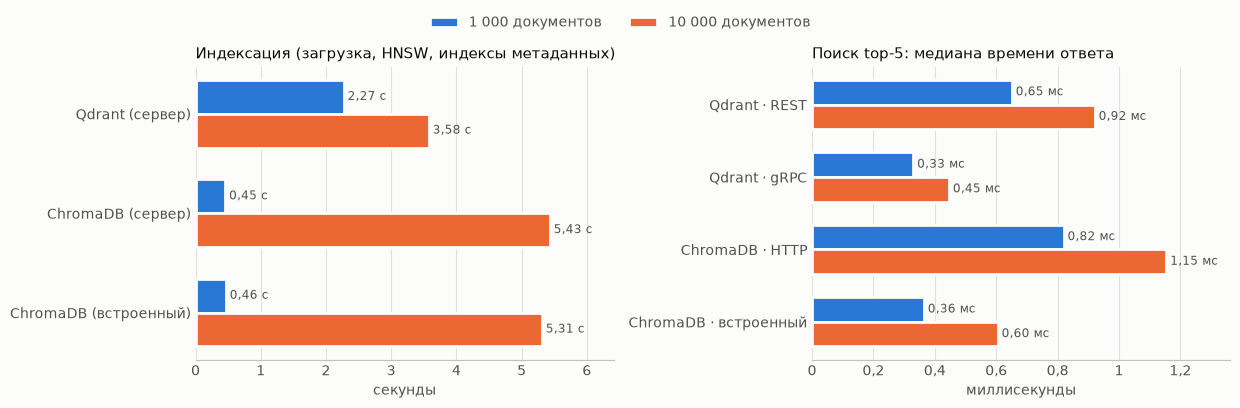

In [29]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834"]  # категориальная палитра: слоты 1–2 (проверены валидатором палитры)


def ru_number(value, digits=2):
    """Число с десятичной запятой."""
    return f"{value:.{digits}f}".replace(".", ",")


def style_axes(ax):
    ax.set_facecolor(SURFACE)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(AXIS)
    ax.tick_params(colors=INK_2, length=0)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}".replace(".", ",")))


def grouped_barh(ax, labels, values, title, xlabel, fmt):
    y = np.arange(len(labels))
    h = 0.34
    for j, (series, color) in enumerate(zip(["1 000 документов", "10 000 документов"], SERIES)):
        bars = ax.barh(y + (j - 0.5) * h, values[:, j], height=h, color=color, edgecolor=SURFACE, linewidth=2,
                       label=series)
        for bar, v in zip(bars, values[:, j]):
            ax.text(bar.get_width(), bar.get_y() + bar.get_height() / 2, " " + fmt(v), va="center", fontsize=8.5,
                    color=INK_2)
    ax.set_yticks(y, labels, color=INK)
    ax.invert_yaxis()
    ax.set_title(title, loc="left", color=INK, fontsize=11)
    ax.set_xlabel(xlabel, color=INK_2)
    ax.margins(x=0.18)
    style_axes(ax)


fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.1), facecolor=SURFACE)
db_labels = ["Qdrant (сервер)", "ChromaDB (сервер)", "ChromaDB (встроенный)"]
index_vals = np.array([[df_index.loc[(db, n), "Индексация всего, с"] for n in (SMALL, LARGE)] for db in db_labels])
grouped_barh(axes[0], db_labels, index_vals, "Индексация (загрузка, HNSW, индексы метаданных)", "секунды",
             lambda v: f"{ru_number(v)} с")
clients = ["Qdrant · REST", "Qdrant · gRPC", "ChromaDB · HTTP", "ChromaDB · встроенный"]
search_vals = np.array([[df_search.loc[(cl, n), "Медиана, мс"] for n in (SMALL, LARGE)] for cl in clients])
grouped_barh(axes[1], clients, search_vals, "Поиск top-5: медиана времени ответа", "миллисекунды",
             lambda v: f"{ru_number(v)} мс")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, labelcolor=INK_2, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

### 2.8. Фильтрация

In [30]:
filter_rows = []
for c in bench["configs"]:
    if "filters" not in c:
        continue
    name = DB_NAMES[(c["db"], c["mode"])]
    for fname, f in c["filters"].items():
        filter_rows.append({"Фильтр": fname, "БД": name, "Подходящих документов": f["matching"],
                            "Медиана, мс": float(np.median(f["latency_ms"])), "p95, мс": float(np.percentile(f["latency_ms"], 95)),
                            "Корректность": f["valid"], "Recall@5": f["recall"]})
df_filters = pd.DataFrame(filter_rows).set_index(["Фильтр", "БД"])
no_filter = {DB_NAMES[(c["db"], c["mode"])]: float(np.median(next(iter(c["search"].values()))["latency_ms"]))
             for c in bench["configs"] if c["n"] == LARGE}
print("Медиана без фильтра (10 000 документов), мс:", {k: round(v, 2) for k, v in no_filter.items()})
df_filters.style.format("{:.2f}", subset=["Медиана, мс", "p95, мс"]).format("{:.0%}", subset=["Корректность"]) \
    .format("{:.3f}", subset=["Recall@5"])

Медиана без фильтра (10 000 документов), мс: {'Qdrant (сервер)': 0.92, 'ChromaDB (сервер)': 1.15, 'ChromaDB (встроенный)': 0.6}


,,Подходящих документов,"Медиана, мс","p95, мс",Корректность,Recall@5
Фильтр,БД,,,,,
равенство: split = test,Qdrant (сервер),3221,0.94,1.15,100%,1.000
диапазон: 600 ≤ n_chars ≤ 900,Qdrant (сервер),4805,0.99,1.32,100%,1.000
конъюнкция: split = train и n_questions ≥ 5,Qdrant (сервер),6738,1.07,1.40,100%,1.000
дизъюнкция: n_questions = 1 или n_chars > 1500,Qdrant (сервер),134,0.70,0.92,100%,1.000
список: doc_id из 100 значений,Qdrant (сервер),100,0.71,0.96,100%,1.000
полнотекстовое: «Москва»,Qdrant (сервер),22,0.68,0.96,100%,1.000
равенство: split = test,ChromaDB (сервер),3221,8.44,9.07,100%,1.000
диапазон: 600 ≤ n_chars ≤ 900,ChromaDB (сервер),4805,22.61,33.29,100%,1.000
конъюнкция: split = train и n_questions ≥ 5,ChromaDB (сервер),6738,20.17,23.16,100%,1.000


### 2.9. Удобство API и гибкость фильтрации

| Критерий | Qdrant | ChromaDB |
|---|---|---|
| Развёртывание | отдельный сервер (бинарный файл, Docker, Qdrant Cloud); встроенный режим `QdrantClient(path=…)` реализован на Python и предназначен для тестов | встроенная библиотека (`PersistentClient`) или сервер `chroma run`; запуск одной строкой без отдельной установки |
| Создание коллекции | явная схема: размерность, метрика, параметры HNSW и оптимизатора, при необходимости квантование и именованные векторы | имя коллекции и словарь `configuration`; размерность определяется по первой загрузке |
| Эмбеддинги | передаются клиентом; интеграция FastEmbed (`models.Document`) использована в ноутбуке курса | встроенная функция эмбеддингов по умолчанию (англоязычная `all-MiniLM-L6-v2`), которую для русского текста нужно заменять |
| Идентификаторы и метаданные | целые числа или UUID; payload — произвольный JSON (вложенные объекты, массивы, гео, даты) | строки; метаданные — плоский словарь: строки, числа, логические значения, списки, разреженные векторы; вложенные объекты не допускаются (проверено на версии 1.5.9) |
| Язык фильтров | `must` / `should` / `must_not`, диапазоны, `MatchAny` / `MatchExcept`, полнотекстовое и гео-условия, условия по вложенным объектам, `IsEmpty`, `HasId`, число значений; индексы payload создаются явно | `$eq`, `$ne`, `$gt`, `$gte`, `$lt`, `$lte`, `$in`, `$nin`, `$and`, `$or`, `$contains` для списков; по тексту документа — `$contains`, `$not_contains`, `$regex`; индексы создаются автоматически |
| Полнотекстовый поиск | индекс по словам: токенизаторы `word`, `whitespace`, `prefix`, `multilingual`, нижний регистр, стоп-слова, стемминг Snowball (в том числе для русского языка), поиск фраз | поиск подстроки или регулярного выражения с учётом регистра |
| Типизация | модели Pydantic (`qm.Filter`, `qm.FieldCondition`), ошибки обнаруживаются до отправки запроса | словари, проверка на стороне сервера |
| Масштабирование | шардирование и репликация в распределённом режиме открытой версии, хранение векторов на диске (mmap), квантование | открытая версия рассчитана на один узел; распределённая архитектура предлагается в облачном сервисе Chroma Cloud |

### 2.10. Итоговая таблица сравнения

In [31]:
def cfg(db, mode, n):
    return next(c for c in bench["configs"] if c["db"] == db and c["mode"] == mode and c["n"] == n)


def med(c, client):
    return float(np.median(c["search"][client]["latency_ms"]))


def filt(c):
    return [float(np.median(f["latency_ms"])) for f in c["filters"].values()]


q1, q10 = cfg("qdrant", "сервер", SMALL), cfg("qdrant", "сервер", LARGE)
s1, s10 = cfg("chroma", "сервер", SMALL), cfg("chroma", "сервер", LARGE)
e1, e10 = cfg("chroma", "встроенный", SMALL), cfg("chroma", "встроенный", LARGE)
r = lambda v, d=2: ru_number(v, d)
final = pd.DataFrame({
    "Qdrant (сервер)": [
        f"{r(q1['index_total_s'])} / {r(q10['index_total_s'])} (из них индексы payload {r(q1['index_total_s'] - q1['hnsw_ready_s'])} / {r(q10['index_total_s'] - q10['hnsw_ready_s'])})",
        f"{q10['rss_loaded_mb']:.0f} (прирост {q10['rss_loaded_mb'] - q10['rss_idle_mb']:.0f}, пик {q10['rss_peak_mb']:.0f})",
        f"{q10['disk_allocated_mb']:.0f} (логический {q10['disk_apparent_mb']:.0f})",
        f"REST {r(med(q1, 'Qdrant · REST'))} / {r(med(q10, 'Qdrant · REST'))}; gRPC {r(med(q1, 'Qdrant · gRPC'))} / {r(med(q10, 'Qdrant · gRPC'))}",
        f"REST {q10['search']['Qdrant · REST']['sequential_total_ms']:.0f}; gRPC {q10['search']['Qdrant · gRPC']['sequential_total_ms']:.0f}",
        f"REST {r(np.median([b['wall_ms'] for b in q10['search']['Qdrant · REST']['parallel']]))}; gRPC {r(np.median([b['wall_ms'] for b in q10['search']['Qdrant · gRPC']['parallel']]))}",
        f"{r(min(filt(q10)))}–{r(max(filt(q10)))}",
        "1,000 / 1,000; выдача воспроизводима",
        "типизированные модели Pydantic, явная схема коллекции и индексов, REST и gRPC",
        "логические комбинации, диапазоны, списки, полнотекстовый индекс со стеммингом, гео, вложенные объекты",
        "шардирование и репликация, mmap-хранение, квантование"],
    "ChromaDB (сервер)": [
        f"{r(s1['index_total_s'])} / {r(s10['index_total_s'])}",
        f"{s10['rss_loaded_mb']:.0f} (прирост {s10['rss_loaded_mb'] - s10['rss_idle_mb']:.0f})",
        f"{s10['disk_allocated_mb']:.0f}",
        f"{r(med(s1, 'ChromaDB · HTTP'))} / {r(med(s10, 'ChromaDB · HTTP'))}",
        f"{s10['search']['ChromaDB · HTTP']['sequential_total_ms']:.0f}",
        f"{r(np.median([b['wall_ms'] for b in s10['search']['ChromaDB · HTTP']['parallel']]))}",
        f"{r(min(filt(s10)))}–{r(max(filt(s10)))}",
        "1,000 / 0,987; выдача воспроизводима",
        "минимальный код, словари, единый API для встроенного и серверного режимов",
        "логические комбинации, диапазоны, списки по метаданным; подстрока и регулярное выражение по тексту",
        "один узел в открытой версии"],
    "ChromaDB (встроенный)": [
        f"{r(e1['index_total_s'])} / {r(e10['index_total_s'])}",
        f"прирост процесса {e10['rss_loaded_mb'] - e10['rss_idle_mb']:.0f} (пик {e10['rss_peak_mb'] - e10['rss_idle_mb']:.0f})",
        f"{e10['disk_allocated_mb']:.0f}",
        f"{r(med(e1, 'ChromaDB · встроенный'))} / {r(med(e10, 'ChromaDB · встроенный'))}",
        f"{e10['search']['ChromaDB · встроенный']['sequential_total_ms']:.0f}",
        f"{r(np.median([b['wall_ms'] for b in e10['search']['ChromaDB · встроенный']['parallel']]))}",
        f"{r(min(filt(e10)))}–{r(max(filt(e10)))}",
        "1,000 / 1,000; выдача воспроизводима",
        "без отдельного сервера; данные доступны только одному процессу",
        "как у сервера ChromaDB",
        "ограничено одним процессом"],
}, index=["Индексация 1 000 / 10 000 документов, с", "RAM после загрузки 10 000 документов, МБ",
          "Диск, 10 000 документов (фактически), МБ", "Поиск top-5, медиана 1 000 / 10 000, мс",
          "20 последовательных запросов (10 000), мс всего", "5 параллельных запросов (10 000), серия, мс",
          "Поиск с фильтром (10 000), медиана по типам фильтров, мс", "Recall@5 к точному поиску 1 000 / 10 000",
          "Удобство API", "Гибкость фильтрации", "Масштабирование"])
final

,Qdrant (сервер),ChromaDB (сервер),ChromaDB (встроенный)
"Индексация 1 000 / 10 000 документов, с","2,27 / 3,58 (из них индексы payload 1,68 / 2,17)","0,45 / 5,43","0,46 / 5,31"
"RAM после загрузки 10 000 документов, МБ","299 (прирост 239, пик 392)",173 (прирост 64),прирост процесса 42 (пик 69)
"Диск, 10 000 документов (фактически), МБ",132 (логический 372),129,129
"Поиск top-5, медиана 1 000 / 10 000, мс","REST 0,65 / 0,92; gRPC 0,33 / 0,45","0,82 / 1,15","0,36 / 0,60"
"20 последовательных запросов (10 000), мс всего",REST 17; gRPC 9,23,12
"5 параллельных запросов (10 000), серия, мс","REST 2,78; gRPC 1,50","4,51","1,46"
"Поиск с фильтром (10 000), медиана по типам фильтров, мс","0,68–1,07","5,97–24,31","5,25–23,86"
Recall@5 к точному поиску 1 000 / 10 000,"1,000 / 1,000; выдача воспроизводима","1,000 / 0,987; выдача воспроизводима","1,000 / 1,000; выдача воспроизводима"
Удобство API,"типизированные модели Pydantic, явная схема коллекции и индексов, REST и gRPC","минимальный код, словари, единый API для встроенного и серверного режимов",без отдельного сервера; данные доступны только одному процессу
Гибкость фильтрации,"логические комбинации, диапазоны, списки, полнотекстовый индекс со стеммингом, гео, вложенные объекты","логические комбинации, диапазоны, списки по метаданным; подстрока и регулярное выражение по тексту",как у сервера ChromaDB


### 2.11. Выводы по заданию 2

**Скорость индексации.** При 10 000 документов Qdrant загружает векторы за 1,07 с и завершает построение HNSW за 1,41 с. С созданием индексов payload, необходимых для фильтрации (в том числе полнотекстового), индексация занимает 3,58 с. ChromaDB в обоих режимах тратит на загрузку 5,3–5,4 с: при добавлении она одновременно записывает документы и метаданные в SQLite и строит полнотекстовый индекс. На коллекции из 1 000 документов соотношение обратное: 0,45 с у ChromaDB против 2,27 с у Qdrant, из которых 1,67 с занимает фиксированная по длительности операция создания индексов payload. При росте коллекции в 10 раз время загрузки Qdrant растёт пропорционально объёму (0,13 → 1,07 с), а у ChromaDB — в 12 раз (0,45 → 5,43 с).

**Скорость и стабильность поиска.**

* Все конфигурации отвечают на запрос top-5 быстрее 1,2 мс (медиана). При росте коллекции в 10 раз время поиска увеличивается на 36–66 %.
* Быстрее всего работают клиент Qdrant по gRPC (0,33 / 0,45 мс) и встроенная ChromaDB (0,36 / 0,60 мс), у которой отсутствует сетевой уровень. По REST и HTTP Qdrant отвечает за 0,65 / 0,92 мс, сервер ChromaDB — за 0,82 / 1,15 мс.
* Выдача воспроизводима во всех конфигурациях (идентичные top-5 во всех повторах); Hit@5 исходного абзаца — 100 %.
* Recall@5 относительно точного поиска равен 1,0, кроме сервера ChromaDB на 10 000 документов (0,987: одна позиция из 75 отличается, что соответствует приближённому характеру HNSW).
* Наименее стабильно время ответа сервера ChromaDB: коэффициент вариации 1,21, отдельный запрос до 16 мс. У остальных конфигураций коэффициент вариации составляет 0,10–0,46.

**Стресс-тест.** 20 последовательных запросов выполняются за 6–23 мс. В параллельных сериях по 5 запросов время одного запроса возрастает в 1,7–2,6 раза из-за конкуренции потоков клиента и сервера, но серия завершается за 1,0–4,5 мс. Наибольшую пропускную способность показывают Qdrant по gRPC и встроенная ChromaDB (3 300–5 100 запросов в секунду в сериях).

**Фильтрация — наиболее существенное различие.**

* Qdrant выполняет поиск с фильтром за 0,68–1,07 мс, то есть не медленнее поиска без фильтра, независимо от числа подходящих документов (от 22 до 6 738). Фильтр применяется в ходе обхода графа HNSW с опорой на индексы payload.
* У ChromaDB поиск с фильтром занимает 5,3–24,3 мс, в 5–40 раз дольше поиска без фильтра, и время растёт с числом подходящих документов. Метаданные фильтруются в SQLite до векторного поиска; полнотекстовое условие требует просмотра документов.
* Корректность фильтрации (все результаты удовлетворяют условию) и Recall@5 относительно точного поиска среди подходящих документов составляют 100 % и 1,0 у обеих БД.
* Язык фильтров Qdrant шире: вложенные объекты, гео-условия, полнотекстовый индекс со стеммингом.

**Память и диск.**

* Qdrant потребляет больше памяти: 299 МБ после загрузки 10 000 документов против 173 МБ у сервера ChromaDB. Qdrant хранит в памяти payload, полнотекстовый индекс и несколько сегментов.
* Встроенная ChromaDB увеличивает память процесса приложения лишь на 42 МБ.
* Фактически занятое место на диске при 10 000 документов близко (132 МБ у Qdrant, 129 МБ у ChromaDB). Однако Qdrant заранее резервирует разреженные файлы: при 1 000 документов логический размер его хранилища — 672 МБ при 71 МБ фактически занятых.

**Какая БД лучше для небольших проектов.** Для прототипов и небольших RAG-систем (до десятков тысяч документов, один экземпляр приложения, простые фильтры) предпочтительна **ChromaDB во встроенном режиме**:

* запуск без отдельного сервера;
* минимальный объём кода;
* наименьшее время поиска без фильтров;
* небольшой прирост памяти;
* быстрая индексация малых коллекций.

**Какая масштабируется лучше.** Лучше масштабируется **Qdrant**:

* время загрузки растёт пропорционально объёму;
* поиск с фильтрами не замедляется с ростом числа подходящих документов;
* доступен gRPC, вдвое сокращающий время ответа по сравнению с REST;
* открытая версия поддерживает распределённый режим (шардирование, репликация), хранение на диске и квантование векторов.

**Ограничения.**

* **Qdrant:**
  * повышенное потребление памяти;
  * фиксированные накладные расходы на создание индексов payload;
  * необходимость явно создавать индексы и настраивать порог индексации (по умолчанию коллекции меньше 10 МБ векторов обслуживаются полным перебором);
  * эксплуатация отдельного сервиса.
* **ChromaDB:**
  * медленная фильтрация по метаданным и тексту;
  * более узкий язык фильтров;
  * отсутствие gRPC;
  * один узел в открытой версии;
  * англоязычная функция эмбеддингов по умолчанию, которую для русскоязычного корпуса необходимо заменять.
* **Ограничения эксперимента:**
  * один компьютер и обмен через localhost без сетевых задержек;
  * коллекции до 10 000 документов, полностью помещающиеся в память;
  * абсолютные значения времени поиска — доли миллисекунды.

  В RAG-приложении на фоне вычисления эмбеддинга запроса (11,3 мс) и генерации ответа LLM (секунды) вклад векторной БД в задержку незначителен. Выбор БД определяется прежде всего требованиями к фильтрации, масштабированию и эксплуатации.

---
## Задание 3. Эксперимент с GigaChat и сравнение с моделями OpenRouter

### 3.1. Модели и единый интерфейс вызова

Модели выбраны по схеме «провайдер × размер», чтобы отделить влияние провайдера от влияния масштаба модели:

| Модель | Провайдер | Параметров | Контекст | Доступ |
|---|---|---|---|---|
| GigaChat-2 (Lite) | GigaChat API | не раскрывается | 128 тыс. токенов | Freemium |
| GigaChat-2-Max | GigaChat API | не раскрывается | 128 тыс. токенов | Freemium |
| LFM-2.5-2.6B (`liquid/lfm-2.5-2.6b:free`) | OpenRouter | 2,6 млрд (плотная) | 65 536 токенов | бесплатная модель |
| Nemotron 3 Super 120B (`nvidia/nemotron-3-super-120b-a12b:free`) | OpenRouter | 120 млрд (MoE, 12 млрд активных) | 262 144 токена | бесплатная модель |
| LFM-2.5-2.6B, 8 бит | локально (MLX) | 2,6 млрд | — | собственное оборудование |

Задание рекомендует малую модель класса 7B. В перечне бесплатных моделей OpenRouter на октябрь 2026 года моделей такого размера нет: доступны модели на 2,6 млрд параметров, MoE-модели с 3–4 млрд активных параметров и крупнее. Поэтому малой моделью выбрана плотная LFM-2.5-2.6B. Крупной моделью первоначально была выбрана плотная Gemma 4 31B (`google/gemma-4-31b-it:free`), однако все обращения к ней в день эксперимента завершились ошибкой 429 «temporarily rate-limited upstream»: исчерпана общая квота бесплатного провайдера Google AI Studio. Эти попытки сохранены в журнале и учтены в анализе стабильности API (п. 3.6), а крупной моделью выбрана Nemotron 3 Super 120B (MoE, 12 млрд активных параметров) провайдера NVIDIA. Открытые веса LFM-2.5-2.6B позволяют запустить ту же модель локально и сравнить локальный запуск с API на одной и той же модели.

**Единый интерфейс.** Все модели вызываются одной функцией `ask(имя_модели, сообщения)`. Под ней находятся классы-провайдеры с общим методом `chat`:

* `GigaChatProvider` — SDK `gigachat`;
* `OpenRouterProvider` — SDK `openai`, так как OpenRouter совместим с OpenAI API;
* `MLXProvider` — локальный запуск через `mlx-lm`.

Ответ любой модели приводится к структуре `LLMResult`: текст, время ответа, входные, выходные и рассуждающие токены, причина остановки, версия модели, ошибка и HTTP-код. Смена модели в приложении сводится к смене имени в реестре `MODELS`.

**Кэширование.** Каждый ответ (включая ошибки API с HTTP-кодом) сохраняется в `practice_db/results/llm_cache.json` по хэшу запроса. Сетевые сбои повторяются до трёх раз и не кэшируются. Повторные вызовы с теми же параметрами не обращаются к API; для повторяющихся запросов нагрузочного теста в ключ добавляется номер запроса.

**Адрес API GigaChat.** SDK `gigachat` версии 0.2.3 по умолчанию обращается к адресу `https://api.giga.chat/v1`, который из сети выполнения работы был недоступен (превышение времени ожидания TLS). Поэтому адрес задан явно: `https://gigachat.devices.sberbank.ru/api/v1`.

In [32]:
from abc import ABC, abstractmethod

CA_BUNDLE = Path("certs/russian_trusted_root_ca.pem")
GIGACHAT_BASE_URL = os.getenv("GIGACHAT_BASE_URL") or "https://gigachat.devices.sberbank.ru/api/v1"
LLM_CACHE_PATH = RESULTS / "llm_cache.json"


@dataclass
class LLMResult:
    model: str
    text: str = ""
    latency_s: float = 0.0
    input_tokens: int | None = None
    output_tokens: int | None = None
    reasoning_tokens: int | None = None
    cached_input_tokens: int | None = None
    finish_reason: str | None = None
    model_version: str | None = None
    error: str | None = None
    status_code: int | None = None
    attempts: int = 1


class NetworkError(Exception):
    """Сетевой сбой или таймаут: результат не кэшируется, запрос повторяется."""


class ChatProvider(ABC):
    @abstractmethod
    def chat(self, model_id: str, messages: list[dict], *, temperature: float, max_tokens: int) -> LLMResult:
        """Один запрос к модели; ответ приводится к LLMResult."""


class GigaChatProvider(ChatProvider):
    def __init__(self):
        from gigachat import GigaChat
        ssl = {"ca_bundle_file": str(CA_BUNDLE)} if CA_BUNDLE.exists() else {"verify_ssl_certs": False}
        self.client = GigaChat(credentials=os.environ["GIGACHAT_CREDENTIALS"], scope=os.getenv("GIGACHAT_SCOPE"),
                               base_url=GIGACHAT_BASE_URL, timeout=600, **ssl)

    def chat(self, model_id, messages, *, temperature, max_tokens):
        import httpx
        from gigachat.exceptions import ResponseError
        from gigachat.models import Chat, Messages, MessagesRole
        payload = Chat(model=model_id, temperature=temperature, max_tokens=max_tokens,
                       messages=[Messages(role=MessagesRole(m["role"]), content=m["content"]) for m in messages])
        t0 = time.perf_counter()
        try:
            resp = self.client.chat(payload)
        except ResponseError as e:
            return LLMResult(model_id, latency_s=time.perf_counter() - t0, error=str(e)[:500],
                             status_code=getattr(e, "status_code", None))
        except (httpx.TransportError, httpx.TimeoutException) as e:
            raise NetworkError(repr(e)) from e
        usage = resp.usage
        return LLMResult(model_id, text=resp.choices[0].message.content, latency_s=time.perf_counter() - t0,
                         input_tokens=usage.prompt_tokens, output_tokens=usage.completion_tokens,
                         cached_input_tokens=getattr(usage, "precached_prompt_tokens", None),
                         finish_reason=resp.choices[0].finish_reason, model_version=resp.model)


class OpenAICompatibleProvider(ChatProvider):
    """Провайдер с OpenAI-совместимым API (OpenRouter, DeepSeek)."""
    def __init__(self, base_url, key_env):
        from openai import OpenAI
        self.client = OpenAI(base_url=base_url, api_key=os.environ[key_env], timeout=600, max_retries=0)

    def chat(self, model_id, messages, *, temperature, max_tokens):
        from openai import APIConnectionError, APIStatusError, APITimeoutError
        t0 = time.perf_counter()
        try:
            resp = self.client.chat.completions.create(model=model_id, messages=messages, temperature=temperature,
                                                       max_tokens=max_tokens)
        except APIStatusError as e:
            return LLMResult(model_id, latency_s=time.perf_counter() - t0, error=str(e)[:500], status_code=e.status_code)
        except (APIConnectionError, APITimeoutError) as e:
            raise NetworkError(repr(e)) from e
        latency = time.perf_counter() - t0
        extra = resp.model_extra or {}
        if not resp.choices:  # ошибка провайдера, возвращённая с кодом 200
            err = extra.get("error") or {}
            return LLMResult(model_id, latency_s=latency, error=str(err)[:500], status_code=err.get("code"))
        usage = resp.usage
        details = getattr(usage, "completion_tokens_details", None)
        provider_name = extra.get("provider")
        return LLMResult(model_id, text=resp.choices[0].message.content or "", latency_s=latency,
                         input_tokens=usage.prompt_tokens, output_tokens=usage.completion_tokens,
                         reasoning_tokens=getattr(details, "reasoning_tokens", None) if details else None,
                         finish_reason=resp.choices[0].finish_reason,
                         model_version=resp.model + (f" ({provider_name})" if provider_name else ""))


class MLXProvider(ChatProvider):
    """Локальный запуск через MLX на Apple Silicon; модель загружается при первом вызове."""
    def __init__(self):
        self.models, self.load_s = {}, {}

    def chat(self, model_id, messages, *, temperature, max_tokens):
        from mlx_lm import load, stream_generate
        from mlx_lm.sample_utils import make_sampler
        if model_id not in self.models:
            t0 = time.perf_counter()
            self.models[model_id] = load(model_id)
            self.load_s[model_id] = time.perf_counter() - t0
        model, tokenizer = self.models[model_id]
        prompt = tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
        t0, text, last = time.perf_counter(), "", None
        for last in stream_generate(model, tokenizer, prompt, max_tokens=max_tokens,
                                    sampler=make_sampler(temp=temperature)):
            text += last.text
        latency = time.perf_counter() - t0
        reasoning_tokens = None
        if "</think>" in text:  # рассуждение отделяется от ответа так же, как в API OpenRouter
            reasoning, text = text.split("</think>", 1)
            reasoning_tokens = len(tokenizer.encode(reasoning))
            text = text.strip()
        elif prompt.rstrip().endswith("<think>"):  # шаблон открыл рассуждение, но оно не завершилось
            reasoning_tokens, text = last.generation_tokens, ""
        return LLMResult(model_id, text=text, latency_s=latency, input_tokens=last.prompt_tokens,
                         output_tokens=last.generation_tokens, reasoning_tokens=reasoning_tokens,
                         finish_reason=last.finish_reason,
                         model_version=f"{model_id} (MLX, пиковая память {last.peak_memory:.2f} ГБ)")


PROVIDERS = {
    "gigachat": GigaChatProvider,
    "openrouter": lambda: OpenAICompatibleProvider("https://openrouter.ai/api/v1", "OPENROUTER_API_KEY"),
    "deepseek": lambda: OpenAICompatibleProvider("https://api.deepseek.com", "DEEPSEEK_API_KEY"),
    "mlx": MLXProvider,
}
MODELS = {  # имя модели в работе -> (провайдер, идентификатор модели у провайдера)
    "GigaChat-2": ("gigachat", "GigaChat-2"),
    "GigaChat-2-Max": ("gigachat", "GigaChat-2-Max"),
    "LFM-2.5-2.6B": ("openrouter", "liquid/lfm-2.5-2.6b:free"),
    "Nemotron-3-Super-120B": ("openrouter", "nvidia/nemotron-3-super-120b-a12b:free"),
    "LFM-2.5-2.6B (локально)": ("mlx", "LiquidAI/LFM2.5-2.6B-MLX-8bit"),
    "deepseek-flash (оценщик)": ("deepseek", "deepseek-flash"),
}
COMPARED = [m for m in MODELS if "оценщик" not in m]
ATTEMPTS_LOG = RESULTS / "llm_attempts.jsonl"  # журнал всех обращений к API, включая повторные попытки
RETRY_STATUS = {429, 500, 502, 503, 504}
_providers = {}
_llm_cache = json.loads(LLM_CACHE_PATH.read_text("utf-8")) if LLM_CACHE_PATH.exists() else {}


def log_attempt(name, tag, result, attempt):
    record = {"time": time.strftime("%Y-%m-%d %H:%M:%S"), "model": name, "tag": tag, "attempt": attempt,
              "status": result.status_code or (200 if not result.error else None),
              "latency_s": round(result.latency_s, 3), "error": (result.error or "")[:200]}
    with ATTEMPTS_LOG.open("a", encoding="utf-8") as f:
        f.write(json.dumps(record, ensure_ascii=False) + "\n")


def ask(name, messages, *, temperature=0.3, max_tokens=4096, tag="", retries=3, backoff=(20, 60, 120)):
    """Единая точка вызова любой модели из реестра MODELS.

    Ответы и ошибки API кэшируются. При кодах 429 и 5xx выполняется до `retries` повторных попыток
    с паузами `backoff`; каждая попытка записывается в журнал llm_attempts.jsonl."""
    kind, model_id = MODELS[name]
    key = hashlib.sha256(json.dumps({"provider": kind, "model": model_id, "messages": messages,
                                     "temperature": temperature, "max_tokens": max_tokens, "tag": tag},
                                    ensure_ascii=False, sort_keys=True).encode()).hexdigest()
    if key in _llm_cache:
        return LLMResult(**_llm_cache[key])
    if kind not in _providers:
        _providers[kind] = PROVIDERS[kind]()
    attempt, network_failures = 0, 0
    while True:
        attempt += 1
        try:
            result = _providers[kind].chat(model_id, messages, temperature=temperature, max_tokens=max_tokens)
        except NetworkError:
            network_failures += 1
            if network_failures > 3:
                raise
            time.sleep(5 * network_failures)
            continue
        if kind != "mlx":
            log_attempt(name, tag, result, attempt)
        if result.status_code in RETRY_STATUS and attempt <= retries:
            time.sleep(backoff[min(attempt, len(backoff)) - 1])
            continue
        break
    result.attempts = attempt
    _llm_cache[key] = asdict(result)
    LLM_CACHE_PATH.write_text(json.dumps(_llm_cache, ensure_ascii=False, indent=1), "utf-8")
    return result


def messages_for(text, system=None):
    return ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": text}]


def openrouter_model_info():
    import httpx
    data = httpx.get("https://openrouter.ai/api/v1/models", timeout=60).json()["data"]
    by_id = {m["id"]: m for m in data}
    info = {}
    for name in ["LFM-2.5-2.6B", "Nemotron-3-Super-120B"]:
        mid = MODELS[name][1]
        paid = by_id.get(mid.replace(":free", ""), {})
        info[name] = {"context_length": by_id[mid]["context_length"],
                      "max_completion_tokens": (by_id[mid].get("top_provider") or {}).get("max_completion_tokens"),
                      "paid_prompt_usd_per_1m": float(paid["pricing"]["prompt"]) * 1e6 if paid else None,
                      "paid_completion_usd_per_1m": float(paid["pricing"]["completion"]) * 1e6 if paid else None}
    info["free_models_total"] = sum(m["id"].endswith(":free") for m in data)
    return info


or_info = stored("task3_openrouter_models", openrouter_model_info)
print(f"Бесплатных моделей в OpenRouter на момент эксперимента: {or_info['free_models_total']}")
pd.DataFrame({k: v for k, v in or_info.items() if k != "free_models_total"}).T

Бесплатных моделей в OpenRouter на момент эксперимента: 16


,context_length,max_completion_tokens,paid_prompt_usd_per_1m,paid_completion_usd_per_1m
LFM-2.5-2.6B,65536.0,8192.0,NaN,NaN
Nemotron-3-Super-120B,262144.0,235929.0,0.08,0.45


### 3.2. Подключение моделей к приложению: RAG-консультант

Приложение из ноутбука курса переработано с учётом результатов заданий 1 и 2.

* **База знаний** — 108 чанков собственного парсера из шести документов корпуса, хранится во встроенной ChromaDB с метаданными (файл, номер чанка, страница).
* **Каталог** — 12 ювелирных изделий из `practice_db/data/catalog.json`, отдельная коллекция ChromaDB.
* **Поиск и промпт.** Эмбеддинги вычисляются моделью `multilingual-e5-small`. Консультант находит 4 ближайших чанка и 2 изделия каталога и формирует промпт с инструкцией отвечать только по контексту.
* **Вызов модели** — через `ask`, поэтому модель задаётся параметром метода `answer`.

Класс `LLMChain`, на котором построено приложение курса, в LangChain 1.x отсутствует, поэтому приложение реализовано без LangChain. Единый интерфейс `ask` не зависит от фреймворка.

In [33]:
KB_PATH = STORAGE / "jewelry_kb"
CATALOG = json.loads((DATA / "catalog.json").read_text("utf-8"))
RAG_SYSTEM = ("Ты — консультант ювелирного магазина. Отвечай только на основе предоставленного контекста. "
              "Если в контексте нет ответа, прямо скажи, что в документах нет этой информации, и не придумывай факты. "
              "Отвечай на русском языке.")


class JewelryConsultant:
    """RAG-консультант: база знаний и каталог во встроенной ChromaDB, модель выбирается при вызове."""
    def __init__(self, path=KB_PATH):
        shutil.rmtree(path, ignore_errors=True)
        client = chromadb.PersistentClient(path=str(path))
        self.kb = client.create_collection("jewelry_kb", embedding_function=None, configuration={"hnsw": {"space": "cosine"}})
        self.kb.add(ids=[f"{c.source}#{c.chunk_id}" for c in ALL_CHUNKS],
                    embeddings=embed_passages([c.text for c in ALL_CHUNKS]),
                    documents=[c.text for c in ALL_CHUNKS],
                    metadatas=[{"source": c.source, "chunk_id": c.chunk_id, "page": c.page or 0} for c in ALL_CHUNKS])
        self.catalog = client.create_collection("jewelry_catalog", embedding_function=None,
                                                configuration={"hnsw": {"space": "cosine"}})
        texts = [f"{p['name']}. {p['description']} Металл: {p['metal']}. Вставка: {p['insert']}. Уход: {p['care']}"
                 for p in CATALOG]
        self.catalog.add(ids=[p["url"] for p in CATALOG], embeddings=embed_passages(texts), documents=texts,
                         metadatas=[{"name": p["name"], "price": p["price"], "url": p["url"]} for p in CATALOG])

    def retrieve(self, question, k=4, k_products=2):
        q = embed_queries([question])
        docs = self.kb.query(query_embeddings=q, n_results=k, include=["documents", "metadatas"])
        products = self.catalog.query(query_embeddings=q, n_results=k_products, include=["documents", "metadatas"])
        return docs, products

    def build_messages(self, question, k=4, k_products=2):
        docs, products = self.retrieve(question, k, k_products)
        context = "\n\n".join(f"[{m['source']}, фрагмент {m['chunk_id']}]\n{d}"
                              for d, m in zip(docs["documents"][0], docs["metadatas"][0]))
        catalog = "\n".join(f"- {d} Цена: {m['price']} руб. Ссылка: {m['url']}"
                            for d, m in zip(products["documents"][0], products["metadatas"][0]))
        user_text = (f"Контекст из документов:\n{context}\n\nТовары из каталога магазина:\n{catalog}\n\n"
                     f"Вопрос клиента: {question}")
        sources = [f"{m['source']} (фрагмент {m['chunk_id']})" for m in docs["metadatas"][0]]
        return messages_for(user_text, RAG_SYSTEM), sources, context

    def answer(self, question, model="GigaChat-2", **params):
        messages, sources, _ = self.build_messages(question)
        result = ask(model, messages, **params)
        return result, sources


consultant = JewelryConsultant()
print(f"База знаний: {consultant.kb.count()} чанков; каталог: {consultant.catalog.count()} изделий")

База знаний: 108 чанков; каталог: 12 изделий


### 3.3. Тестовые задачи и автоматические проверки

Все модели получают одинаковые сообщения с одинаковыми параметрами генерации (`temperature = 0,3`, `max_tokens = 4096`). Для каждой задачи определены эталон и автоматическая проверка.

| Задача | Содержание | Автоматическая проверка (0–1) |
|---|---|---|
| Логическая | распределение четырёх покупок по пяти условиям; единственное решение: Анна — браслет, Белла — цепочка, Вика — кольцо, Галя — серьги | доля верно названных пар в строке «Ответ: …» |
| Генерация кода | функция `chunk_text` с перекрытием и проверкой аргументов | доля пройденных тестов (10 проверок, включая исключения и случайные строки); код выполняется в отдельном процессе после проверки на запрещённые вызовы |
| Аналитическая | изменение выручки по четырём категориям и общее изменение; категории роста и проблемные; три решения | наличие верных значений: +15 %, −5 %, +30 %, +5 %, общий рост +11,86 % |
| RAG-вопрос | очистка серебра от тёмного налёта по контексту консультанта | доля ключевых фактов контекста, приведённых в ответе |
| RAG-вопрос без ответа | гарантийный срок изделий бренда SOKOLOV (в документах его нет) | признание отсутствия информации |

In [34]:
SYSTEM = "Ты — полезный ассистент. Отвечай на русском языке, точно и по существу."

LOGIC = """Решите логическую задачу.

Четыре покупательницы — Анна, Белла, Вика и Галя — купили в ювелирном магазине по одному изделию: кольцо, серьги, браслет и цепочку (все изделия разные). Известно:
1. Анна не покупала ни кольцо, ни серьги.
2. Изделие, которое купила Вика, дороже серёг, а серьги дороже и браслета, и цепочки.
3. Галя не покупала цепочку.
4. Белла не покупала браслет.
5. Серьги купила не Белла.

Кто что купил? Приведите краткое рассуждение, а в последней строке дайте ответ в формате: «Ответ: Анна — …, Белла — …, Вика — …, Галя — …»."""

CODE = """Напишите на Python функцию `chunk_text(text: str, size: int, overlap: int) -> list[str]`, которая разбивает текст на фрагменты фиксированной длины с перекрытием.

Требования:
1. Каждый фрагмент имеет длину не более `size` символов; начало каждого следующего фрагмента сдвинуто на `size - overlap` символов относительно предыдущего.
2. Последний фрагмент заканчивается концом текста; фрагмент, целиком входящий в предыдущий, не добавляется.
3. Для пустой строки функция возвращает пустой список.
4. При `size <= 0`, `overlap < 0` или `overlap >= size` функция возбуждает `ValueError`.

Пример: `chunk_text("abcdefghij", 4, 1)` → `["abcd", "defg", "ghij"]`.

Приведите только код функции в одном блоке ```python``` без примеров использования."""

ANALYTICS = """Проанализируйте выручку ювелирного интернет-магазина по категориям (руб.):

| Категория | I квартал | II квартал |
|---|---|---|
| Кольца | 1 200 000 | 1 380 000 |
| Серьги | 800 000 | 760 000 |
| Цепочки | 650 000 | 845 000 |
| Браслеты | 300 000 | 315 000 |

Задание: 1) рассчитайте изменение выручки по каждой категории в процентах и общее изменение выручки магазина; 2) определите категории роста и проблемные категории; 3) предложите три обоснованных управленческих решения. Объём ответа — не более 250 слов."""

RAG_QUESTION = "Как в домашних условиях очистить серебряное украшение от тёмного налёта?"
RAG_NO_ANSWER = "Какой гарантийный срок установлен на изделия бренда SOKOLOV?"
RAG_FACTS = {"зубной порошок или мел": r"зубн\w* порош|мел\w*\b", "50 г соды на 1 л воды": r"50\s*г",
             "нашатырный спирт": r"нашатыр", "мыльная вода": r"мыльн", "пропорция 1:1": r"1\s*:\s*1"}
EXPECTED_LOGIC = {"Анна": "браслет", "Белла": "цепочк", "Вика": "кольц", "Галя": "серьг"}

rag_messages, rag_sources, rag_context = consultant.build_messages(RAG_QUESTION)
noans_messages, noans_sources, noans_context = consultant.build_messages(RAG_NO_ANSWER)
TASKS = {
    "logic": ("Логическая задача", messages_for(LOGIC, SYSTEM)),
    "code": ("Генерация кода", messages_for(CODE, SYSTEM)),
    "analytics": ("Аналитический ответ", messages_for(ANALYTICS, SYSTEM)),
    "rag": ("RAG-вопрос", rag_messages),
    "rag_no_answer": ("RAG-вопрос без ответа", noans_messages),
}
print("Источники контекста RAG-вопроса:", "; ".join(rag_sources))
print("Факты, присутствующие в контексте:", [f for f, p in RAG_FACTS.items() if re.search(p, rag_context)])
print("Источники контекста вопроса без ответа:", "; ".join(noans_sources))

Источники контекста RAG-вопроса: docx_care.docx (фрагмент 5); docx_care.docx (фрагмент 6); docx_care.docx (фрагмент 4); docx_care.docx (фрагмент 3)
Факты, присутствующие в контексте: ['зубной порошок или мел', '50 г соды на 1 л воды', 'нашатырный спирт', 'мыльная вода', 'пропорция 1:1']
Источники контекста вопроса без ответа: docx_choice.docx (фрагмент 9); docx_choice.docx (фрагмент 10); pdf_scan.pdf (фрагмент 15); pdf_scan.pdf (фрагмент 16)


In [35]:
FORBIDDEN_CODE = re.compile(r"\b(?:os|sys|subprocess|socket|shutil|pathlib|requests|urllib|ctypes|importlib|pickle)\b"
                            r"|\b(?:open|exec|eval|compile|__import__|input|globals|locals|breakpoint)\s*\(")
CODE_TESTS = r'''
import json, random
results = []
def check(name, fn):
    try:
        results.append((name, bool(fn())))
    except Exception as e:
        results.append((name, False))
def raises(*args):
    try:
        chunk_text(*args)
    except ValueError:
        return True
    return False
check("пример из условия", lambda: chunk_text("abcdefghij", 4, 1) == ["abcd", "defg", "ghij"])
check("неполный последний фрагмент", lambda: chunk_text("abcdefghijk", 4, 1) == ["abcd", "defg", "ghij", "jk"])
check("пустая строка", lambda: chunk_text("", 5, 2) == [])
check("текст короче size", lambda: chunk_text("abc", 5, 2) == ["abc"])
check("без перекрытия", lambda: chunk_text("abcdefg", 3, 0) == ["abc", "def", "g"])
check("overlap = size - 1", lambda: chunk_text("abcde", 3, 2) == ["abc", "bcd", "cde"])
check("ValueError: size <= 0", lambda: raises("abc", 0, 0))
check("ValueError: overlap < 0", lambda: raises("abc", 3, -1))
check("ValueError: overlap >= size", lambda: raises("abc", 3, 3))
def reference(text, size, overlap):
    if not text:
        return []
    out, i = [], 0
    while True:
        out.append(text[i:i + size])
        if i + size >= len(text):
            return out
        i += size - overlap
rng = random.Random(0)
cases = []
for _ in range(200):
    s = "".join(rng.choice("абв гд") for _ in range(rng.randint(0, 60)))
    size = rng.randint(1, 12)
    cases.append((s, size, rng.randint(0, size - 1)))
check("200 случайных строк", lambda: all(chunk_text(*c) == reference(*c) for c in cases))
print(json.dumps(results, ensure_ascii=False))
'''


def extract_code(text):
    blocks = re.findall(r"```(?:python|py)?\s*\n(.*?)```", text, re.S)
    return max(blocks, key=len) if blocks else text


def check_code(text):
    """Доля пройденных тестов; код запускается в отдельном процессе Python с ограничением времени."""
    code = extract_code(text)
    if FORBIDDEN_CODE.search(code):
        return 0.0, "код содержит запрещённые вызовы"
    try:
        proc = subprocess.run([sys.executable, "-I", "-c", code + "\n" + CODE_TESTS], capture_output=True, text=True,
                              timeout=20, cwd=STORAGE)
        results = json.loads(proc.stdout.strip().splitlines()[-1])
    except Exception as e:
        return 0.0, f"ошибка выполнения: {type(e).__name__}"
    failed = [name for name, ok in results if not ok]
    return sum(ok for _, ok in results) / len(results), ("не пройдены: " + ", ".join(failed)) if failed else "все тесты пройдены"


def plain(text):
    """Текст без разметки LaTeX и Markdown для поиска чисел."""
    t = text.replace("\\%", "%").replace("\\,", "").replace("$", "").replace("**", "")
    t = re.sub(r"\\(?:text|mathrm|left|right|frac|times|approx)", " ", t)
    return re.sub(r"(?<=\d)[\N{THIN SPACE}\N{NO-BREAK SPACE}\N{NARROW NO-BREAK SPACE} ](?=\d{3})", "", t)


def check_logic(text):
    """Доля верных пар «покупательница — изделие» в строке «Ответ: …»."""
    lines = [ln for ln in text.splitlines() if "Ответ" in ln]
    target = (lines[-1] if lines else text[-300:]).replace("ё", "е").replace("*", "")
    found = {}
    for name in EXPECTED_LOGIC:
        m = re.search(name + r"\W{0,6}(?:купила\s+)?([а-яА-Я]+)", target)
        found[name] = m.group(1).lower() if m else None
    correct = sum(bool(v) and v.startswith(EXPECTED_LOGIC[k]) for k, v in found.items())
    return correct / 4, ", ".join(f"{k} — {v}" for k, v in found.items())


CATEGORY_GROWTH = {"Кольца": 15, "Серьги": 5, "Цепочки": 30, "Браслеты": 5}


def check_analytics(text):
    """Верные значения изменения выручки по категориям и общего изменения (+11,86 %)."""
    t = plain(text)
    checks = {}
    for name, value in CATEGORY_GROWTH.items():
        start = t.find(name)
        if start < 0:
            checks[name] = False
            continue
        later = [t.find(other, start + 1) for other in CATEGORY_GROWTH if other != name]
        end = min([p for p in later if p > start] + [start + 400])
        values = [float(v.replace(",", ".")) for v in re.findall(r"(\d+(?:[.,]\d+)?)\s*%", t[start:end])]
        checks[name] = any(abs(v - value) < 0.05 for v in values)
    totals = [float(v.replace(",", ".")) for v in re.findall(r"(\d{1,2}[.,]\d{1,2})\s*%", t)]
    checks["итого +11,86 %"] = any(11.8 <= v <= 11.9 for v in totals)
    missed = [k for k, ok in checks.items() if not ok]
    return sum(checks.values()) / len(checks), ("неверно или нет: " + ", ".join(missed)) if missed else "все значения верны"


def check_rag(text):
    in_context = {f: p for f, p in RAG_FACTS.items() if re.search(p, rag_context)}
    found = [f for f, p in in_context.items() if re.search(p, text)]
    return len(found) / len(in_context), f"{len(found)} из {len(in_context)} фактов: {', '.join(found)}"


REFUSAL = re.compile(r"нет\s+(?:\w+\s+){0,2}(?:информации|сведений|данных)|не\s+(?:указан|содерж|приведен|привод|упомина"
                     r"|сообща|говорится|описан)|отсутству|не знаю|не могу (?:ответить|сказать|точно)", re.I)


def check_refusal(text):
    ok = bool(REFUSAL.search(text))
    return float(ok), "отсутствие информации признано" if ok else "ответ дан без оговорки"


CHECKS = {"logic": check_logic, "code": check_code, "analytics": check_analytics, "rag": check_rag,
          "rag_no_answer": check_refusal}
REFERENCE_SOLUTION = """```python
def chunk_text(text, size, overlap):
    if size <= 0 or overlap < 0 or overlap >= size:
        raise ValueError("недопустимые параметры")
    if not text:
        return []
    out, i = [], 0
    while True:
        out.append(text[i:i + size])
        if i + size >= len(text):
            return out
        i += size - overlap
```"""
print("Проверка автоматических проверок на эталонных ответах:")
print("  код:", check_code(REFERENCE_SOLUTION))
print("  логика:", check_logic("Ответ: Анна — браслет, Белла — цепочка, Вика — кольцо, Галя — серьги"))
print("  аналитика:", check_analytics("Кольца: +15%. Серьги: −5%. Цепочки: +30%. Браслеты: +5%. Итого: +11,86%."))
print("  отказ:", check_refusal("В документах нет информации о гарантийном сроке SOKOLOV."))

Проверка автоматических проверок на эталонных ответах:
  код: (1.0, 'все тесты пройдены')
  логика: (1.0, 'Анна — браслет, Белла — цепочка, Вика — кольцо, Галя — серьги')
  аналитика: (1.0, 'все значения верны')
  отказ: (1.0, 'отсутствие информации признано')


### 3.4. Прогон моделей: время ответа, длина ответа и число токенов

In [36]:
def run_tasks(models):
    out = []
    for model in models:
        for task, (title, msgs) in TASKS.items():
            r = ask(model, msgs)
            score, note = CHECKS[task](r.text) if not r.error else (0.0, f"ошибка API: {r.status_code}")
            out.append({**asdict(r), "model": model, "model_id": MODELS[model][1], "task": task, "title": title,
                        "score": score, "note": note})
    return out


API_MODELS = ["GigaChat-2", "GigaChat-2-Max", "LFM-2.5-2.6B", "Nemotron-3-Super-120B"]
task_runs = stored("task3_tasks", lambda: run_tasks(API_MODELS + ["LFM-2.5-2.6B (локально)"]))
df_tasks = pd.DataFrame(task_runs)
df_tasks["words"] = df_tasks["text"].str.split().str.len()
df_tasks["chars"] = df_tasks["text"].str.len()
df_tasks["tokens_per_s"] = df_tasks["output_tokens"] / df_tasks["latency_s"]
table = df_tasks.pivot_table(index="model", columns="title", values="latency_s", sort=False)
print("Время ответа, с:")
table.round(1)

Время ответа, с:


title,Логическая задача,Генерация кода,Аналитический ответ,RAG-вопрос,RAG-вопрос без ответа
model,,,,,
GigaChat-2,5.5,1.1,4.2,2.7,0.4
GigaChat-2-Max,8.1,2.8,6.0,4.0,0.5
LFM-2.5-2.6B,19.5,11.4,5.1,6.7,2.5
Nemotron-3-Super-120B,45.7,33.3,24.5,13.7,3.7
LFM-2.5-2.6B (локально),107.0,107.1,27.0,26.8,18.3


In [37]:
summary = df_tasks.groupby("model", sort=False).agg(
    **{"Время ответа, с (медиана)": ("latency_s", "median"), "Время ответа, с (макс.)": ("latency_s", "max"),
       "Длина ответа, слов (медиана)": ("words", "median"), "Входных токенов (сумма)": ("input_tokens", "sum"),
       "Выходных токенов (сумма)": ("output_tokens", "sum"), "Из них рассуждений": ("reasoning_tokens", "sum"),
       "Выходных токенов в секунду (медиана)": ("tokens_per_s", "median"), "Ошибок API": ("error", "count")})
summary.style.format("{:.1f}", subset=["Время ответа, с (медиана)", "Время ответа, с (макс.)",
                                       "Выходных токенов в секунду (медиана)"]) \
    .format("{:.0f}", subset=["Длина ответа, слов (медиана)", "Входных токенов (сумма)", "Выходных токенов (сумма)",
                              "Из них рассуждений", "Ошибок API"])

,"Время ответа, с (медиана)","Время ответа, с (макс.)","Длина ответа, слов (медиана)",Входных токенов (сумма),Выходных токенов (сумма),Из них рассуждений,Выходных токенов в секунду (медиана),Ошибок API
model,,,,,,,,
GigaChat-2,2.7,5.5,65,2490,1145,0,58.7,0
GigaChat-2-Max,4.0,8.1,111,2490,956,0,45.7,0
LFM-2.5-2.6B,6.7,19.5,68,3407,8987,7912,209.7,0
Nemotron-3-Super-120B,24.5,45.7,105,3331,4559,3212,42.6,0
LFM-2.5-2.6B (локально),27.0,107.1,121,3407,10915,9734,38.1,0


In [38]:
detail_cols = {"latency_s": "Время, с", "input_tokens": "Вход, токенов", "output_tokens": "Выход, токенов",
               "reasoning_tokens": "Рассуждения, токенов", "words": "Слов", "finish_reason": "Остановка"}
df_tasks.set_index(["title", "model"])[list(detail_cols)].rename(columns=detail_cols) \
    .style.format({"Время, с": "{:.1f}", "Вход, токенов": "{:.0f}", "Выход, токенов": "{:.0f}",
                   "Рассуждения, токенов": "{:.0f}"}, na_rep="—")

,,"Время, с","Вход, токенов","Выход, токенов","Рассуждения, токенов",Слов,Остановка
title,model,,,,,,
Логическая задача,GigaChat-2,5.5,194,297,—,183,stop
Генерация кода,GigaChat-2,1.1,209,122,—,65,stop
Аналитический ответ,GigaChat-2,4.2,216,595,—,175,stop
RAG-вопрос,GigaChat-2,2.7,1029,107,—,65,stop
RAG-вопрос без ответа,GigaChat-2,0.4,842,24,—,14,stop
Логическая задача,GigaChat-2-Max,8.1,194,347,—,218,stop
Генерация кода,GigaChat-2-Max,2.8,209,141,—,73,stop
Аналитический ответ,GigaChat-2-Max,6.0,216,276,—,111,stop
RAG-вопрос,GigaChat-2-Max,4.0,1029,185,—,116,stop


LFM-2.5-2.6B — рассуждающая модель: прежде чем дать ответ, она генерирует рассуждение, и токены рассуждения входят в лимит `max_tokens`. Если на какой-либо задаче рассуждение исчерпывает лимит (остановка `length` при пустом ответе), проводится дополнительный запуск этой задачи с лимитом 16 384 токена. Он показывает, связан ли отказ с недостатком бюджета токенов или с неспособностью модели решить задачу. В основной таблице сохраняется результат с единым для всех моделей лимитом.

In [39]:
def run_budget_check():
    rows = []
    for t in task_runs:
        if t["finish_reason"] == "length" and not (t["text"] or "").strip():
            r = ask(t["model"], TASKS[t["task"]][1], max_tokens=16384)
            score, note = CHECKS[t["task"]](r.text) if not r.error else (0.0, f"ошибка API: {r.status_code}")
            rows.append({**asdict(r), "model": t["model"], "task": t["task"], "score": score, "note": note})
    return rows


budget_runs = stored("task3_budget_check", run_budget_check)
if budget_runs:
    display(pd.DataFrame(budget_runs).set_index(["task", "model"])[["latency_s", "output_tokens", "reasoning_tokens",
                                                             "finish_reason", "score", "note"]] \
        .rename(columns={"latency_s": "Время, с", "output_tokens": "Выход, токенов",
                         "reasoning_tokens": "Рассуждения, токенов", "finish_reason": "Остановка",
                         "score": "Авто-оценка", "note": "Результат проверки"})
            .style.format({"Время, с": "{:.1f}", "Выход, токенов": "{:.0f}", "Рассуждения, токенов": "{:.0f}",
                           "Авто-оценка": "{:.1f}"}))
else:
    print("Ни одна модель не исчерпала лимит токенов.")

### 3.5. Длинный промпт (1000+ токенов) и ограничения контекста

**Длинный промпт.** Модели получают полный текст четырёх документов корпуса (около 29 тыс. символов, после парсинга) и вопрос, ответ на который находится в середине одного из документов: сколько капель нашатырного спирта на стакан воды нужно для чистки украшения с камнями (эталон — 6 капель).

**Проверка ограничений контекста.** Модели получают запросы, превышающие заявленное окно контекста; фиксируются ответ API, код ошибки и время до отказа.

* **LFM-2.5-2.6B** (65 536 токенов): текст корпуса, повторённый 12 раз (около 346 тыс. символов).
* **GigaChat-2** (128 тыс. токенов), два запроса:
  * текст корпуса, повторённый 24 раза (около 692 тыс. символов, 1,4 МБ);
  * «плотный» текст из шестнадцатеричных групп, у которого на токен приходится около 1,15 символа (180 тыс. символов, около 158 тыс. токенов). Такой текст превышает окно контекста при небольшом размере запроса.

Отдельно измерен предельный размер содержимого запроса к API GigaChat. Применялся двоичный поиск по длине сообщения с заведомо несуществующим именем модели: запрос, превышающий лимит, отклоняется шлюзом с кодом 413, меньший — самим API с кодом 404, без генерации и расхода токенов.

In [40]:
LONG_DOCS = ["docx_care.docx", "docx_choice.docx", "txt_novgorod.txt", "pdf_scan.pdf"]
long_context = "\n\n".join(f"=== Документ: {name} ===\n{PARSED[name]['text']}" for name in LONG_DOCS)
LONG_QUESTION = "Сколько капель нашатырного спирта на стакан воды рекомендуется использовать при чистке украшения с камнями?"
long_messages = messages_for(f"{long_context}\n\nВопрос: {LONG_QUESTION}", RAG_SYSTEM)
OVERFLOW = {"LFM-2.5-2.6B": 12, "GigaChat-2": 24}  # число повторов текста корпуса в запросе
DENSE_TEXT = " ".join(f"{(i * 2654435761) % 2**32:08x}" for i in range(20000))  # ≈1,15 символа на токен GigaChat
print(f"Длинный промпт: {len(long_messages[1]['content']):,} символов".replace(",", " "))


def run_long_context():
    rows = []
    for model in COMPARED:
        r = ask(model, long_messages)
        rows.append({**asdict(r), "model": model, "kind": "длинный промпт",
                     "correct": bool(re.search(r"6\s*капел", r.text)), "prompt_chars": len(long_messages[1]["content"])})
    for model, times in OVERFLOW.items():
        text = "\n\n".join([long_context] * times)
        r = ask(model, messages_for(f"{text}\n\nВопрос: {LONG_QUESTION}", RAG_SYSTEM), max_tokens=256)
        rows.append({**asdict(r), "model": model, "kind": "переполнение: русский текст",
                     "correct": bool(re.search(r"6\s*капел", r.text)), "prompt_chars": len(text)})
    r = ask("GigaChat-2", messages_for(DENSE_TEXT + "\n\nСколько групп символов в тексте выше?"), max_tokens=256)
    rows.append({**asdict(r), "model": "GigaChat-2", "kind": "переполнение: плотный текст", "correct": False,
                 "prompt_chars": len(DENSE_TEXT)})
    return rows


def gigachat_request_limit():
    """Предельный размер содержимого запроса GigaChat (двоичный поиск с несуществующей моделью: 413 — отказ шлюза,
    404 — запрос принят шлюзом и отклонён API без генерации)."""
    from gigachat.exceptions import ResponseError
    from gigachat.models import Chat, Messages, MessagesRole
    _providers.setdefault("gigachat", PROVIDERS["gigachat"]())
    client = _providers["gigachat"].client

    def status(n_bytes):
        try:
            client.chat(Chat(model="no-such-model", max_tokens=1,
                             messages=[Messages(role=MessagesRole.USER, content="a" * n_bytes)]))
            return 200
        except ResponseError as e:
            return e.status_code
    lo, hi = 100_000, 2_000_000
    probes = [(lo, status(lo)), (hi, status(hi))]
    while hi - lo > 10_000:
        mid = (lo + hi) // 2
        code = status(mid)
        probes.append((mid, code))
        lo, hi = (lo, mid) if code == 413 else (mid, hi)
    return {"accepted_bytes": lo, "rejected_bytes": hi, "probes": probes}


long_runs = stored("task3_long_context", run_long_context)
df_long = pd.DataFrame(long_runs)
df_long["Ответ (начало) или ошибка"] = [(r["error"] or r["text"])[:230].replace("\n", " ") for r in long_runs]
df_long.set_index(["kind", "model"])[["prompt_chars", "input_tokens", "output_tokens", "latency_s", "correct",
                                      "status_code", "Ответ (начало) или ошибка"]] \
    .rename(columns={"prompt_chars": "Символов в запросе", "input_tokens": "Входных токенов",
                     "output_tokens": "Выходных токенов", "latency_s": "Время, с", "correct": "Ответ «6 капель»",
                     "status_code": "HTTP-код"}) \
    .style.format({"Входных токенов": "{:.0f}", "Выходных токенов": "{:.0f}", "Время, с": "{:.1f}",
                   "HTTP-код": "{:.0f}"}, na_rep="—")

Длинный промпт: 28 952 символов


In [41]:
limit = stored("task3_gigachat_request_limit", gigachat_request_limit)
giga_long = df_long[(df_long.model == "GigaChat-2") & (df_long.kind == "длинный промпт")].iloc[0]
chars_per_token = giga_long["prompt_chars"] / giga_long["input_tokens"]
russian_chars = limit["accepted_bytes"] / 2  # кириллица в UTF-8 занимает 2 байта на символ
print(f"Запрос к API GigaChat принимается при {limit['accepted_bytes']:,} байт содержимого и отклоняется (413) при "
      f"{limit['rejected_bytes']:,} байт, то есть предел около 1 МиБ.".replace(",", " "))
print(f"Для русского текста это около {russian_chars / 1000:.0f} тыс. символов, или около "
      f"{russian_chars / chars_per_token / 1000:.0f} тыс. токенов GigaChat ({ru_number(chars_per_token)} символа на токен).")

Запрос к API GigaChat принимается при 1 042 578 байт содержимого и отклоняется (413) при 1 050 000 байт  то есть предел около 1 МиБ.
Для русского текста это около 521 тыс. символов, или около 121 тыс. токенов GigaChat (4,32 символа на токен).


### 3.6. Нагрузочный тест: 10 запросов подряд

Каждая модель получает 10 одинаковых коротких запросов подряд, без пауз. Фиксируются доля успешных ответов, распределение времени ответа, ошибки и стабильность длины ответа. Для бесплатных моделей OpenRouter действуют ограничения: 20 запросов в минуту и 50 запросов в сутки для учётной записи без пополнения баланса. Для тарифа Freemium GigaChat генерация выполняется в одном потоке.

In [42]:
LOAD_MESSAGES = messages_for("Кратко, в одном-двух предложениях: что означает проба 585 на золотом изделии?", SYSTEM)
LOAD_N = 10


def run_load_test(models):
    rows = []
    for model in models:
        t_start = time.perf_counter()
        for i in range(LOAD_N):
            r = ask(model, LOAD_MESSAGES, tag=f"load-{i + 1}", retries=0)  # без повторов: фиксируется поведение API
            rows.append({**asdict(r), "model": model, "i": i + 1})
        rows[-1]["series_s"] = time.perf_counter() - t_start
    return rows


load_runs = stored("task3_load_test", lambda: run_load_test(COMPARED))
df_load = pd.DataFrame(load_runs)
df_load["ok"] = df_load["error"].isna() & (df_load["text"].str.len() > 0)
load_summary = df_load.groupby("model", sort=False).apply(lambda g: pd.Series({
    "Успешных ответов": f"{g['ok'].sum()}/{len(g)}",
    "Время: медиана, с": g.loc[g.ok, "latency_s"].median(), "p95, с": g.loc[g.ok, "latency_s"].quantile(0.95),
    "мин, с": g.loc[g.ok, "latency_s"].min(), "макс, с": g.loc[g.ok, "latency_s"].max(),
    "Коэфф. вариации": g.loc[g.ok, "latency_s"].std() / g.loc[g.ok, "latency_s"].mean(),
    "Выходных токенов: медиана": g.loc[g.ok, "output_tokens"].median(),
    "Ошибки": "; ".join(sorted({f"{int(c)}: {e[:60]}" for c, e in zip(g["status_code"].fillna(0), g["error"]) if isinstance(e, str)})) or "—",
}), include_groups=False)
load_summary.style.format({"Время: медиана, с": "{:.2f}", "p95, с": "{:.2f}", "мин, с": "{:.2f}", "макс, с": "{:.2f}",
                           "Коэфф. вариации": "{:.2f}", "Выходных токенов: медиана": "{:.0f}"}, na_rep="—")

,Успешных ответов,"Время: медиана, с","p95, с","мин, с","макс, с",Коэфф. вариации,Выходных токенов: медиана,Ошибки
model,,,,,,,,
GigaChat-2,10/10,0.56,1.38,0.50,1.62,0.51,43,—
GigaChat-2-Max,10/10,1.43,1.64,1.10,1.65,0.13,52,—
LFM-2.5-2.6B,9/10,2.34,10.87,1.22,11.42,0.90,269,429: Error code: 429 - {'error': {'message': 'Provider returned e
Nemotron-3-Super-120B,10/10,3.73,8.39,2.37,10.84,0.55,126,—
LFM-2.5-2.6B (локально),10/10,5.55,11.48,4.17,14.74,0.47,215,—


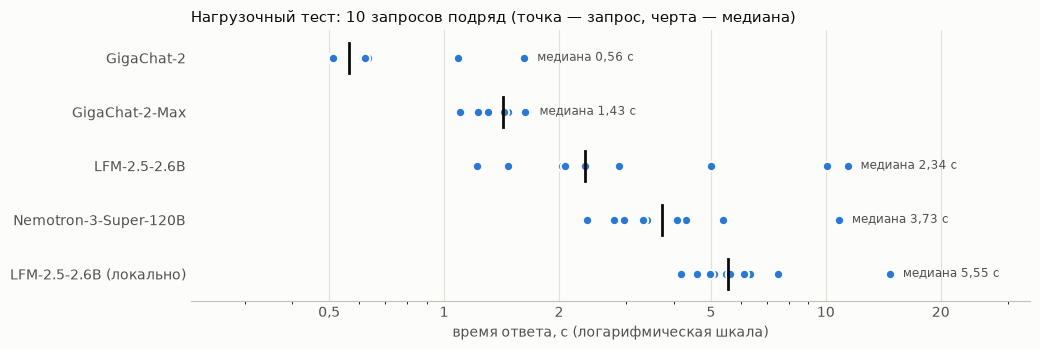

In [43]:
fig, ax = plt.subplots(figsize=(10.5, 3.6), facecolor=SURFACE)
order = list(load_summary.index)
for y, model in enumerate(order):
    g = df_load[(df_load.model == model) & df_load.ok]
    ax.scatter(g["latency_s"], np.full(len(g), y), s=46, color=SERIES[0], edgecolor=SURFACE, linewidth=1.5, zorder=3)
    med = g["latency_s"].median()
    ax.plot([med, med], [y - 0.28, y + 0.28], color=INK, linewidth=2, zorder=4)
    ax.text(g["latency_s"].max() * 1.08, y, f"медиана {ru_number(med)} с", va="center", fontsize=8.5, color=INK_2)
from matplotlib.ticker import NullFormatter

ax.set_xscale("log")
ax.set_yticks(range(len(order)), order, color=INK)
ax.invert_yaxis()
ax.set_xlabel("время ответа, с (логарифмическая шкала)", color=INK_2)
ax.set_title("Нагрузочный тест: 10 запросов подряд (точка — запрос, черта — медиана)", loc="left", color=INK, fontsize=11)
style_axes(ax)
ok_latency = df_load.loc[df_load.ok, "latency_s"]
ax.set_xticks([t for t in [0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200]
               if ok_latency.min() / 2 <= t <= ok_latency.max() * 2])
ax.xaxis.set_minor_formatter(NullFormatter())
ax.margins(x=0.25)
fig.tight_layout()
plt.show()

**Стабильность API за весь эксперимент.** Журнал `llm_attempts.jsonl` содержит каждое обращение к API, включая повторные попытки после ошибок 429 и 5xx. Попытки, выполненные до включения повторов, перенесены в журнал из кэша с отметкой «первый прогон». Ответы 400, 413 и 422 на намеренные запросы сверх пределов (п. 3.5) выделены отдельно и в долю отказов не входят. Доля отказов показывает, какую часть обычных запросов провайдер отклонил.

In [44]:
attempts = (pd.read_json(ATTEMPTS_LOG, lines=True) if ATTEMPTS_LOG.exists()
            else pd.DataFrame(columns=["time", "model", "tag", "attempt", "status", "latency_s", "error"]))
codes = attempts["status"].astype(float).fillna(
    attempts["error"].astype(str).str.extract(r"^(\d{3}) ")[0].astype(float))  # код из текста ошибки SDK
LIMIT_TEST_CODES = [400, 413, 422]  # ожидаемые ответы тестов пределов контекста и размера запроса (п. 3.5)
attempts["Результат"] = np.select([codes == 200, codes == 429, codes.isin(LIMIT_TEST_CODES)],
                                  ["успех", "429 (лимит провайдера)", "тест пределов (400/413/422)"], "другая ошибка")
stability = attempts.pivot_table(index="model", columns="Результат", values="attempt", aggfunc="count", fill_value=0)
stability["Всего обращений"] = stability.sum(axis=1)
unexpected = stability.get("429 (лимит провайдера)", 0) + stability.get("другая ошибка", 0)
stability["Доля отказов"] = unexpected / (stability["Всего обращений"] - stability.get("тест пределов (400/413/422)", 0))
stability.style.format({"Доля отказов": "{:.0%}"})

Результат,429 (лимит провайдера),тест пределов (400/413/422),успех,Всего обращений,Доля отказов
model,,,,,
Gemma-4-31B,8,0,0,8,100%
GigaChat-2,0,3,16,19,0%
GigaChat-2-Max,0,0,16,16,0%
LFM-2.5-2.6B,1,1,16,18,6%
Nemotron-3-Super-120B,0,0,16,16,0%
deepseek-flash (оценщик),0,0,58,58,0%


### 3.7. Оценка качества: точность, структурированность, галлюцинации

Качество оценивается двумя независимыми способами.

1. **Автоматические проверки** (п. 3.3) измеряют точность там, где её можно проверить объективно: ответ логической задачи, тесты кода, числа аналитической задачи, факты RAG-ответа, отказ при отсутствии ответа, ответ на вопрос длинного промпта.
2. **LLM-as-a-Judge.** Модель `deepseek-flash` не участвует в сравнении. Она получает задание, эталон или критерии верного ответа, контекст (для RAG-вопросов) и ответ модели и выставляет оценки от 1 до 5 по трём критериям:
   * точность;
   * структурированность;
   * отсутствие галлюцинаций — утверждений, не следующих из условия или контекста.

   Оценщик вызывается через тот же единый интерфейс `ask` с `temperature = 0` и лимитом 4096 токенов. `deepseek-flash` — рассуждающая модель, и при меньшем лимите рассуждение обрывает JSON с оценкой. Для RAG-вопросов оценщик получает полный текст запроса консультанта (контекст документов и каталога), чтобы сведения из каталога не считались галлюцинацией.

In [45]:
REFERENCES = {
    "logic": "Единственное решение: Анна — браслет, Белла — цепочка, Вика — кольцо, Галя — серьги. Из условия 2 Вика купила "
             "изделие дороже серёг, то есть кольцо. Если Анна купила цепочку, то Белла (не браслет, не серьги) не получает "
             "изделия, поэтому Анна купила браслет, Белла — цепочку, Галя — серьги.",
    "code": "Функция должна удовлетворять всем четырём требованиям и примеру; правильная реализация: проверка аргументов, "
            "пустой список для пустой строки, сдвиг на size - overlap, остановка, когда фрагмент дошёл до конца текста.",
    "analytics": "Кольца +15,0 %, серьги −5,0 %, цепочки +30,0 %, браслеты +5,0 %; выручка 2 950 000 → 3 300 000 руб., "
                 "общий рост +11,86 %. Категории роста — цепочки и кольца (браслеты — слабый рост), проблемная — серьги. "
                 "Решения должны быть обоснованы данными.",
    "rag": "Ответ должен опираться только на контекст: чистка зубным порошком или мелом, содовый раствор (50 г соды на 1 л "
           "горячей воды), тёплая мыльная вода с нашатырным спиртом (1 ст. ложка на 1 л), раствор горячей воды и "
           "нашатырного спирта 1:1, затем ополоснуть и вытереть мягкой тканью. Любые способы, которых нет в контексте, — "
           "галлюцинации.",
    "rag_no_answer": "В контексте нет сведений о гарантийном сроке изделий SOKOLOV; верный ответ — сообщить об отсутствии "
                     "информации. Допустимо упомянуть общие нормы из контекста, явно отделив их от ответа о SOKOLOV; "
                     "указание конкретного гарантийного срока SOKOLOV — галлюцинация.",
    "long": "Эталон: 6 капель нашатырного спирта на 1 стакан воды (для украшений с камнями).",
}
TASK_TEXT = {"logic": LOGIC, "code": CODE, "analytics": ANALYTICS,
             "rag": f"Вопрос клиента: {RAG_QUESTION} (ответ строится по контексту ниже)",
             "rag_no_answer": f"Вопрос клиента: {RAG_NO_ANSWER} (ответ строится по контексту ниже)",
             "long": f"Вопрос по длинному документу: {LONG_QUESTION}"}
JUDGE_SYSTEM = ("Ты — строгий эксперт, оценивающий ответы языковых моделей. Оценивай только по приведённым "
                "эталону и контексту. Верни только JSON без пояснений вне него.")


def judge(task, answer):
    context = {"rag": rag_messages[1]["content"], "rag_no_answer": noans_messages[1]["content"]}.get(task)
    prompt = (f"Задание:\n{TASK_TEXT[task]}\n\nЭталон и критерии верного ответа:\n{REFERENCES[task]}\n\n"
              + (f"Запрос, полученный моделью (контекст документов и каталога):\n{context}\n\n" if context else "")
              + f"Ответ модели:\n{answer}\n\n"
              "Оцени ответ по шкале от 1 до 5 по трём критериям:\n"
              "accuracy — точность (5 — полностью верно, 1 — неверно);\n"
              "structure — структурированность и соблюдение требуемого формата (5 — образцово, 1 — хаотично);\n"
              "hallucinations — отсутствие галлюцинаций, то есть утверждений, не следующих из условия или контекста "
              "(5 — галлюцинаций нет, 1 — много).\n"
              'Формат ответа: {"accuracy": 0, "structure": 0, "hallucinations": 0, "comment": "обоснование до 25 слов"}')
    r = ask("deepseek-flash (оценщик)", messages_for(prompt, JUDGE_SYSTEM), temperature=0.0, max_tokens=4096)
    m = re.search(r"\{.*\}", r.text, re.S)
    return json.loads(m.group(0)) if m else {"accuracy": None, "structure": None, "hallucinations": None,
                                             "comment": r.error or r.text[:100]}


def run_judging():
    rows = []
    for t in task_runs:
        rows.append({"model": t["model"], "task": t["task"], **judge(t["task"], t["text"] or t["error"] or "")})
    for t in long_runs:
        if t["kind"] == "длинный промпт":
            rows.append({"model": t["model"], "task": "long", **judge("long", t["text"] or t["error"] or "")})
    return rows


judgements = stored("task3_judge", run_judging)
df_judge = pd.DataFrame(judgements)
auto = df_tasks.pivot_table(index="model", columns="title", values="score", sort=False)
auto["Длинный промпт"] = df_long[df_long.kind == "длинный промпт"].set_index("model")["correct"].astype(float)
auto["Среднее"] = auto.mean(axis=1)
print("Автоматические проверки (доля выполненных требований, 0–1):")
auto.round(2)

Автоматические проверки (доля выполненных требований, 0–1):


title,Логическая задача,Генерация кода,Аналитический ответ,RAG-вопрос,RAG-вопрос без ответа,Длинный промпт,Среднее
model,,,,,,,
GigaChat-2,0.5,0.7,0.8,0.8,1.0,1.0,0.80
GigaChat-2-Max,1.0,0.6,0.8,0.6,1.0,1.0,0.83
LFM-2.5-2.6B,0.0,0.7,0.8,0.6,1.0,0.0,0.52
Nemotron-3-Super-120B,1.0,0.9,1.0,0.8,1.0,1.0,0.95
LFM-2.5-2.6B (локально),0.0,0.0,0.8,0.8,1.0,1.0,0.60


In [46]:
judge_mean = df_judge.groupby("model", sort=False)[["accuracy", "structure", "hallucinations"]].mean()
judge_mean.columns = ["Точность (1–5)", "Структурированность (1–5)", "Отсутствие галлюцинаций (1–5)"]
judge_mean["Среднее"] = judge_mean.mean(axis=1)
print("LLM-as-a-Judge (deepseek-flash), средние по 6 задачам:")
judge_mean.round(2)

LLM-as-a-Judge (deepseek-flash), средние по 6 задачам:


,Точность (1–5),Структурированность (1–5),Отсутствие галлюцинаций (1–5),Среднее
model,,,,
GigaChat-2,3.50,5.00,4.50,4.33
GigaChat-2-Max,3.83,5.00,4.17,4.33
LFM-2.5-2.6B,2.50,4.17,4.17,3.61
Nemotron-3-Super-120B,4.67,5.00,4.67,4.78
LFM-2.5-2.6B (локально),3.00,3.67,4.50,3.72


In [47]:
notes = df_tasks.set_index(["title", "model"])[["score", "note"]]
jt = df_judge.assign(title=df_judge["task"].map({k: v[0] for k, v in TASKS.items()} | {"long": "Длинный промпт"})) \
    .set_index(["title", "model"])[["accuracy", "structure", "hallucinations", "comment"]]
notes.join(jt, how="outer").rename(columns={"score": "Авто", "note": "Результат проверки", "accuracy": "Точн.",
                                            "structure": "Структ.", "hallucinations": "Без галл.",
                                            "comment": "Комментарий оценщика"})

Авто  \
title                 model                           
RAG-вопрос            GigaChat-2                0.8   
                      GigaChat-2-Max            0.6   
                      LFM-2.5-2.6B              0.6   
                      LFM-2.5-2.6B (локально)   0.8   
                      Nemotron-3-Super-120B     0.8   
RAG-вопрос без ответа GigaChat-2                1.0   
                      GigaChat-2-Max            1.0   
                      LFM-2.5-2.6B              1.0   
                      LFM-2.5-2.6B (локально)   1.0   
                      Nemotron-3-Super-120B     1.0   
Аналитический ответ   GigaChat-2                0.8   
                      GigaChat-2-Max            0.8   
                      LFM-2.5-2.6B              0.8   
                      LFM-2.5-2.6B (локально)   0.8   
                      Nemotron-3-Super-120B     1.0   
Генерация кода        GigaChat-2                0.7   
                      GigaChat-2-Max            0.6   
                      LFM-2.5-2.6B              0.7   
                      LFM-2.5-2.6B (локально)   0.0   
                      Nemotron-3-Super-120B     0.9   
Длинный промпт        GigaChat-2                NaN   
                      GigaChat-2-Max            NaN   
                      LFM-2.5-2.6B              NaN   
                      LFM-2.5-2.6B (локально)   NaN   
                      Nemotron-3-Super-120B     NaN   
Логическая задача     GigaChat-2                0.5   
                      GigaChat-2-Max            1.0   
                      LFM-2.5-2.6B              0.0   
                      LFM-2.5-2.6B (локально)   0.0   
                      Nemotron-3-Super-120B     1.0   

                                                                                                                                                                                            Результат проверки  \
title                 model                                                                                                                                                                                      
RAG-вопрос            GigaChat-2                                                                                  4 из 5 фактов: зубной порошок или мел, 50 г соды на 1 л воды, нашатырный спирт, мыльная вода   
                      GigaChat-2-Max                                                                                            3 из 5 фактов: зубной порошок или мел, 50 г соды на 1 л воды, нашатырный спирт   
                      LFM-2.5-2.6B                                                                                                                3 из 5 фактов: нашатырный спирт, мыльная вода, пропорция 1:1   
                      LFM-2.5-2.6B (локально)                                                                        4 из 5 фактов: зубной порошок или мел, 50 г соды на 1 л воды, мыльная вода, пропорция 1:1   
                      Nemotron-3-Super-120B                                                                       4 из 5 фактов: зубной порошок или мел, 50 г соды на 1 л воды, нашатырный спирт, мыльная вода   
RAG-вопрос без ответа GigaChat-2                                                                                                                                                отсутствие информации признано   
                      GigaChat-2-Max                                                                                                                                            отсутствие информации признано   
                      LFM-2.5-2.6B                                                                                                                                              отсутствие информации признано   
                      LFM-2.5-2.6B (локально)                                                                                                                                   отсутствие

Ответы моделей на RAG-вопрос показывают работу приложения при переключении модели: контекст и промпт одинаковы, меняется только имя модели в вызове `ask`.

In [48]:
for t in task_runs:
    if t["task"] == "rag":
        print(f"=== {t['model']} ({t['latency_s']:.1f} с)\n{(t['text'] or t['error'])[:900]}\n")

=== GigaChat-2 (2.7 с)
В домашних условиях тёмный налёт с серебряных изделий можно удалить следующими способами:

1. Специальным раствором.
2. Зубным порошком или мелко толчёным мелом.
3. Промыванием в содовом растворе (50 г питьевой соды на 1 литр горячей воды).
4. Промыванием в тёплой мыльной воде с нашатырным спиртом (1 столовая ложка на 1 литр воды).

После любого способа очищения изделие необходимо ополоснуть чистой водой и досушить мягкой тканью.

=== GigaChat-2-Max (4.0 с)
Для удаления тёмного налёта с серебряного украшения в домашних условиях можно использовать следующие методы:

1. **Содовый раствор**: Приготовьте раствор из расчёта 50 граммов питьевой соды на 1 литр горячей воды. Поместите серебряное изделие в этот раствор до исчезновения налёта, затем тщательно промойте чистой водой и высушите мягкой тканью.

2. **Нашатырный спирт**: Сделайте тёплый раствор из одной столовой ложки нашатырного спирта на один литр воды. Опустите туда серебряное изделие, после чего осторожно вы

### 3.8. Локальный запуск и сравнение с API

Модель LFM-2.5-2.6B запущена локально в квантовании 8 бит через MLX (официальные веса `LiquidAI/LFM2.5-2.6B-MLX-8bit`, 2,9 ГБ) на графическом ускорителе Apple M5. Та же модель вызывалась через OpenRouter, что позволяет сравнить способы запуска без влияния различий моделей.

In [49]:
local_name, api_name = "LFM-2.5-2.6B (локально)", "LFM-2.5-2.6B"


def local_model_info():
    """Размер весов и время загрузки локальной модели в память ускорителя."""
    from huggingface_hub import snapshot_download
    from mlx_lm import load
    model_id = MODELS[local_name][1]
    path = Path(snapshot_download(model_id))
    t0 = time.perf_counter()
    load(model_id)
    return {"load_s": time.perf_counter() - t0,
            "weights_gb": sum(f.stat().st_size for f in path.rglob("*.safetensors")) / 1e9}


local_info = stored("task3_local_model", local_model_info)
peaks = [float(m) for m in re.findall(r"пиковая память ([\d.]+)", " ".join(
    r["model_version"] or "" for r in task_runs + long_runs + load_runs if r["model"] == local_name))]
print(f"Веса: {local_info['weights_gb']:.2f} ГБ; загрузка модели: {local_info['load_s']:.1f} с; "
      f"пиковая память ускорителя при генерации: до {max(peaks):.2f} ГБ")
lc = df_tasks[df_tasks.model.isin([local_name, api_name])]
compare = lc.pivot_table(index="title", columns="model", values=["latency_s", "tokens_per_s", "score"], sort=False)
compare.columns = [f"{m}: {dict(latency_s='время, с', tokens_per_s='токенов/с', score='авто-оценка')[v]}" for v, m in compare.columns]
local_meta = next(r for r in task_runs if r["model"] == local_name)
print("Версия локальной модели:", local_meta["model_version"])
compare.round(2)

Веса: 2.87 ГБ; загрузка модели: 3.0 с; пиковая память ускорителя при генерации: до 3.85 ГБ
Версия локальной модели: LiquidAI/LFM2.5-2.6B-MLX-8bit (MLX, пиковая память 3.21 ГБ)


,"LFM-2.5-2.6B: время, с","LFM-2.5-2.6B (локально): время, с",LFM-2.5-2.6B: токенов/с,LFM-2.5-2.6B (локально): токенов/с,LFM-2.5-2.6B: авто-оценка,LFM-2.5-2.6B (локально): авто-оценка
title,,,,,,
Логическая задача,19.53,107.00,209.73,38.28,0.0,0.0
Генерация кода,11.38,107.11,238.47,38.24,0.7,0.0
Аналитический ответ,5.11,26.98,209.90,38.14,0.8,0.8
RAG-вопрос,6.73,26.78,96.37,37.52,0.6,0.8
RAG-вопрос без ответа,2.52,18.31,180.25,37.63,1.0,1.0


### 3.9. Сравнительная таблица

Стоимость платного использования приведена по тарифам GigaChat для физических лиц (с 1 сентября 2026 года) и по ценам платных версий моделей в OpenRouter на дату эксперимента.

In [50]:
nemotron_paid = or_info["Nemotron-3-Super-120B"]
INTEGRATION = {
    "GigaChat-2": "собственный SDK, OAuth-токен, сертификат Минцифры; адрес API задан явно; один поток на Freemium",
    "GigaChat-2-Max": "как у GigaChat-2",
    "LFM-2.5-2.6B": "OpenAI-совместимый API, один ключ для всех моделей; бесплатные модели: 20 запросов/мин, 50/сутки",
    "Nemotron-3-Super-120B": "как у LFM-2.5-2.6B; состав бесплатных моделей и их доступность меняются",
    "LFM-2.5-2.6B (локально)": "mlx-lm и 2,9 ГБ весов; только Apple Silicon (на других платформах — llama.cpp, vLLM); без сетевых ограничений",
}
COST = {
    "GigaChat-2": "Freemium: 250 млн токенов на 12 мес.; платно 65 ₽ за 1 млн токенов (пакет 20 млн — 1 300 ₽)",
    "GigaChat-2-Max": "Freemium: 25 млн токенов на 12 мес.; платно 650 ₽ за 1 млн токенов (пакет 3 млн — 1 950 ₽)",
    "LFM-2.5-2.6B": "бесплатно в пределах лимитов; платной версии в OpenRouter нет",
    "Nemotron-3-Super-120B": (f"бесплатно в пределах лимитов; платная версия ${ru_number(nemotron_paid['paid_prompt_usd_per_1m'])} "
                              f"/ ${ru_number(nemotron_paid['paid_completion_usd_per_1m'])} за 1 млн входных / выходных токенов"),
    "LFM-2.5-2.6B (локально)": "без оплаты за запрос; затраты на оборудование и электроэнергию",
}
fail_share = stability["Доля отказов"].to_dict()


def comparison_row(name):
    g = df_tasks[df_tasks.model == name]
    ok = df_load[(df_load.model == name) & df_load.ok]
    jm = judge_mean.loc[name]
    return {
        "Время ответа на задачи, с (медиана / макс.)": f"{ru_number(g.latency_s.median(), 1)} / {ru_number(g.latency_s.max(), 1)}",
        "Выходных токенов в секунду (медиана)": ru_number(g.tokens_per_s.median(), 0),
        "Нагрузочный тест: успешно, медиана / p95, с": (f"{len(ok)}/{LOAD_N}, {ru_number(ok.latency_s.median())} / "
                                                       f"{ru_number(ok.latency_s.quantile(0.95))}") if len(ok) else f"0/{LOAD_N}",
        "Авто-оценка, 0–1 (среднее по 6 задачам)": ru_number(auto.loc[name, "Среднее"]),
        "Оценщик: точность / структура / без галлюцинаций, 1–5": " / ".join(ru_number(v, 1) for v in jm.iloc[:3]),
        "Доля отказов API за эксперимент": f"{fail_share[name]:.0%}" if name in fail_share else "— (локальный запуск)",
        "Длинный промпт: ответ «6 капель»": "да" if bool(df_long[(df_long.model == name) & (df_long.kind == "длинный промпт")]["correct"].iloc[0]) else "нет",
        "Удобство интеграции": INTEGRATION[name],
        "Стоимость": COST[name],
    }


pd.DataFrame({name: comparison_row(name) for name in COMPARED})

,GigaChat-2,GigaChat-2-Max,LFM-2.5-2.6B,Nemotron-3-Super-120B,LFM-2.5-2.6B (локально)
"Время ответа на задачи, с (медиана / макс.)","2,7 / 5,5","4,0 / 8,1","6,7 / 19,5","24,5 / 45,7","27,0 / 107,1"
Выходных токенов в секунду (медиана),59,46,210,43,38
"Нагрузочный тест: успешно, медиана / p95, с","10/10, 0,56 / 1,38","10/10, 1,43 / 1,64","9/10, 2,34 / 10,87","10/10, 3,73 / 8,39","10/10, 5,55 / 11,48"
"Авто-оценка, 0–1 (среднее по 6 задачам)","0,80","0,83","0,52","0,95","0,60"
"Оценщик: точность / структура / без галлюцинаций, 1–5","3,5 / 5,0 / 4,5","3,8 / 5,0 / 4,2","2,5 / 4,2 / 4,2","4,7 / 5,0 / 4,7","3,0 / 3,7 / 4,5"
Доля отказов API за эксперимент,0%,0%,6%,0%,— (локальный запуск)
Длинный промпт: ответ «6 капель»,да,да,нет,да,да
Удобство интеграции,"собственный SDK, OAuth-токен, сертификат Минцифры; адрес API задан явно; один поток на Freemium",как у GigaChat-2,"OpenAI-совместимый API, один ключ для всех моделей; бесплатные модели: 20 запросов/мин, 50/сутки",как у LFM-2.5-2.6B; состав бесплатных моделей и их доступность меняются,"mlx-lm и 2,9 ГБ весов; только Apple Silicon (на других платформах — llama.cpp, vLLM); без сетевых ограничений"
Стоимость,Freemium: 250 млн токенов на 12 мес.; платно 65 ₽ за 1 млн токенов (пакет 20 млн — 1 300 ₽),Freemium: 25 млн токенов на 12 мес.; платно 650 ₽ за 1 млн токенов (пакет 3 млн — 1 950 ₽),бесплатно в пределах лимитов; платной версии в OpenRouter нет,"бесплатно в пределах лимитов; платная версия $0,08 / $0,45 за 1 млн входных / выходных токенов",без оплаты за запрос; затраты на оборудование и электроэнергию


### 3.10. Выводы по заданию 3

**Скорость.**

* Наименьшее время ответа — у моделей GigaChat: медиана 2,7 с (GigaChat-2) и 4,0 с (GigaChat-2-Max) на тестовых задачах, 0,56 и 1,43 с на коротком запросе нагрузочного теста. Модели GigaChat не генерируют рассуждений, поэтому время ответа определяется длиной ответа (46–59 токенов в секунду).
* Обе модели OpenRouter — рассуждающие:
  * LFM-2.5-2.6B генерирует быстрее всех (210 токенов в секунду у провайдера Liquid), но 88 % её выходных токенов составляет рассуждение (7 912 из 8 987), и медиана времени ответа достигает 6,7 с;
  * Nemotron 3 Super 120B генерирует 43 токена в секунду, рассуждение занимает 70 % токенов, медиана времени ответа — 24,5 с, максимум — 45,7 с.
* Число токенов у разных провайдеров несопоставимо. Один и тот же длинный промпт (28 952 символа) — это 6 709 токенов GigaChat и 9 364–9 584 токена у моделей OpenRouter: токенизатор GigaChat кодирует русский текст в 1,4 раза компактнее (4,3 символа на токен против 3,0–3,1).

**Качество.**

* **Nemotron 3 Super 120B** показала лучшее качество: 0,95 по автоматическим проверкам, оценки 4,7 / 5,0 / 4,7. Это единственная модель, верно рассчитавшая общее изменение выручки (+11,9 %). Она решила логическую задачу, её код прошёл 9 из 10 тестов.
* **GigaChat-2-Max и GigaChat-2** набрали 0,83 и 0,80; структурированность ответов безупречна (5,0), но допущены арифметические и логические ошибки:
  * обе модели неверно сложили выручку (+11,5 % и ≈10 % вместо +11,86 %);
  * GigaChat-2 неверно решила логическую задачу, GigaChat-2-Max пришла к верному ответу через ошибочное рассуждение;
  * код обеих моделей не проходит пример из условия.
* **LFM-2.5-2.6B** — 0,52 через API и 0,60 локально.
  * В логической задаче рассуждение исчерпало лимит 4096 токенов, и ответ не был получен. Через API не помогает и лимит 16 384 токена: провайдер ограничивает вывод 8 192 токенами. Локально, без этого ограничения, модель решила задачу верно (5 772 токена, 150 с).
  * В длинном промпте версия через API не нашла ответ («нет информации»), локальная нашла его, но с искажением слова.
* **Галлюцинации.** На вопрос, ответа на который в документах нет (гарантийный срок SOKOLOV), все пять моделей корректно сообщили об отсутствии информации. Основной вид галлюцинаций в RAG-ответах — детали, отсутствующие в контексте: у GigaChat-2-Max оценка по этому критерию 4,2, у LFM в ответе о серебре оказался совет для позолоченных изделий.

**Ограничения контекста и ошибки API.**

* Окна контекста подтверждены экспериментально. LFM-2.5-2.6B возвращает ошибку 400 с указанием лимита 65 536 токенов. GigaChat-2 возвращает ошибку 422 «context too long 158 137, maximum allowed context is 130 048», то есть фактическое окно — 130 048 токенов.
* Для русского текста у GigaChat раньше окна контекста срабатывает ограничение размера запроса. Шлюз отклоняет тело больше ≈1 МиБ (ошибка 413), что соответствует ≈521 тыс. символов кириллицы, или ≈121 тыс. токенов.
* Провайдер LFM в OpenRouter ограничивает вывод 8 192 токенами, включая рассуждение.

**Стабильность.**

* GigaChat: ни одного отказа на 32 обычных запроса; самое стабильное время ответа — у GigaChat-2-Max (коэффициент вариации 0,13). Однако адрес API, заданный в SDK по умолчанию, был недоступен из сети выполнения и потребовал явной настройки.
* OpenRouter:
  * первоначально выбранная Gemma 4 31B была полностью недоступна: все 8 обращений завершились ошибкой 429 «temporarily rate-limited upstream»;
  * у LFM — один отказ 429 в нагрузочном тесте (6 % обычных запросов) и большой разброс времени ответа (коэффициент вариации 0,90, до 11,4 с);
  * у Nemotron отказов не было.

**Когда лучше использовать GigaChat.** GigaChat подходит для русскоязычных RAG-сценариев, где важны низкая и стабильная задержка, например для консультанта магазина, отвечающего по документам:

* ответ за 0,5–3 с без рассуждений, отказов нет;
* большие бесплатные квоты (250 млн токенов GigaChat-2 в год);
* компактный токенизатор снижает стоимость русского текста;
* данные обрабатываются в российской юрисдикции, оплата в рублях.

Ограничения:

* API не совместим с OpenAI (собственный SDK, OAuth-токен, сертификат Минцифры);
* на тарифе Freemium — один поток;
* ошибки в многошаговой арифметике и логике, поэтому в таких задачах ответы требуют проверки вычислений или более сильной модели.

**Когда выгоднее OpenRouter.** OpenRouter выгоднее:

* при прототипировании и выборе модели: один OpenAI-совместимый API для десятков моделей;
* в задачах, требующих рассуждений, вычислений и генерации кода, где Nemotron 3 Super показала лучшее качество;
* когда допустима задержка в десятки секунд.

Бесплатный доступ ограничен 50 запросами в сутки и 20 в минуту, а доступность и состав бесплатных моделей меняются (случай Gemma 4 31B). Для промышленного применения нужны платная версия модели (у Nemotron — 0,08 / 0,45 доллара за 1 млн входных / выходных токенов) и резервная модель.

**Оправдан ли локальный запуск.** Локальная LFM-2.5-2.6B работает на Apple M5: загрузка за 3 с, до 3,9 ГБ памяти, 38 токенов в секунду. Это в 5,5 раза медленнее той же модели через API (210 токенов в секунду), при этом качество сопоставимо (0,60 против 0,52 по автоматическим проверкам, 3,7 против 3,6 у оценщика). Локальный запуск оправдан в следующих случаях:

* важна конфиденциальность данных;
* требуется работа без сети;
* нужно избежать лимитов и ограничений провайдера (неограниченный бюджет вывода позволил решить логическую задачу);
* предстоит большой объём однотипных запросов к небольшой модели.

Для качества уровня Nemotron (120 млрд параметров) локально нужны серверные GPU, поэтому в учебных и небольших проектах API экономически оправданнее.

---
## Общие выводы

1. **Парсинг.** Собственный конвейер (pypdf, python-docx, стандартная библиотека) извлекает 43 из 44 контрольных фраз и обрабатывает документы в 36–155 раз быстрее режима `hi_res` библиотеки unstructured. Его чанки с метаданными дают в контексте 90 % частей ответа на вопросы со списками и таблицами против 39 % у мелких элементов unstructured. Сканы и сложные таблицы требуют дополнительных этапов: распознавания (Tesseract) и анализа разметки страницы.
2. **Векторные БД.** На масштабе консультанта (сотни чанков) выбор векторной БД не влияет на задержку: поиск занимает доли миллисекунды, тогда как эмбеддинг запроса — 11 мс, а генерация ответа — секунды.
   * ChromaDB во встроенном режиме проще в эксплуатации.
   * Qdrant предпочтителен при росте коллекции и интенсивной фильтрации по метаданным: там ChromaDB замедляется в 5–40 раз, а время ответа Qdrant не меняется.
3. **Языковые модели.** Лучшее качество показала рассуждающая Nemotron 3 Super 120B (OpenRouter), наименьшую и наиболее стабильную задержку — модели GigaChat. Малая рассуждающая модель LFM-2.5-2.6B ненадёжна в многошаговых задачах: рассуждение исчерпывает бюджет токенов раньше, чем модель формирует ответ.
4. **Рекомендуемая конфигурация консультанта.**
   * Собственный парсинг с чанками 800 / 150 символов; страницы без текстового слоя направляются на OCR.
   * Встроенная ChromaDB; переход на Qdrant — при росте корпуса и фильтрации по каталогу.
   * GigaChat-2 как основная модель для ответов по документам, с проверкой вычислений. Через единый интерфейс `ask` аналитические запросы переключаются на более сильную модель: GigaChat-2-Max или Nemotron в платном доступе OpenRouter.
5. **Ограничения работы.**
   * Эксперименты проведены на одном компьютере, с небольшим корпусом документов и коллекциями до 10 000 векторов.
   * Каждая модель решала каждую задачу один раз (`temperature = 0,3`).
   * Использовались бесплатные тарифы с их лимитами и колебаниями доступности.

   Выводы о качестве моделей основаны на шести задачах и требуют подтверждения на расширенном наборе.